# Violencia armada: conflicto global y homicidios en Colombia
## Gerencia y almacenamiento en Big Data — Proyecto final

**Autor:** Diego Felipe Almanza Ruiz
**Datasets:** UCDP Georeferenced Event Dataset 26.1 + UCDP Candidate 2026 (violencia organizada global) y Homicidios del Ministerio de Defensa Nacional de Colombia (datos.gov.co)
**Video de sustentación:** https://fundacionlibertadores-my.sharepoint.com/:v:/r/personal/dfalmanzar_libertadores_edu_co/_layouts/15/stream.aspx?id=%2Fpersonal%2Fdfalmanzar_libertadores_edu_co%2FDocuments%2FGrabaciones%2FSustentaci%C3%B3n%20Proyecto%20Final-20261118_142214-Grabaci%C3%B3n%20de%20la%20reuni%C3%B3n.mp4&nav=eyJyZWZlcnJhbEluZm8iOnsicmVmZXJyYWxBcHAiOiJTdHJlYW1XZWJBcHAiLCJyZWZlcnJhbFZpZXciOiJTaGFyZURpYWxvZy1MaW5rIiwicmVmZXJyYWxBcHBQbGF0Zm9ybSI6IldlYiIsInJlZmVycmFsTW9kZSI6InZpZXcifX0%3D&share=cQrFitqTYfKwSJvRgqMLMAypEgUCbcMy09nY8zbpc4TyGzq3zg

## 1. Business Understanding

### 1.1 Problema
La violencia con armas no es un fenómeno único. En un extremo está la **violencia militarizada** (combates entre fuerzas del Estado y grupos armados, ataques de guerrillas o paramilitares). En el otro está la **violencia criminal urbana** (sicariato, atracos, riñas, enfrentamientos entre pandillas). Las dos se responden con políticas distintas (operaciones militares y procesos de paz en un caso; policía, prevención y control de armas en el otro), pero las cifras agregadas de homicidios las mezclan.

Este proyecto combina dos fuentes oficiales que se complementan:

| Fuente | Nivel | Qué aporta |
|---|---|---|
| **UCDP GED 26.1 + Candidate 2026** (Uppsala University) | Global, un registro por evento | Violencia organizada en el mundo entre 1989 y 2026, clasificada en conflicto estatal, conflicto no estatal (entre grupos armados, incluidos carteles) y violencia unilateral contra civiles |
| **Homicidios — MinDefensa** (datos.gov.co) | Colombia, un registro por día, municipio, sexo, arma y modalidad | Homicidios de 2003 a 2026 con el **arma usada** (arma de fuego, arma blanca, explosivos…) y la **modalidad** (sicariato, riñas, atraco, ataque de grupos armados, enfrentamientos…) |

### 1.2 Pregunta de negocio
> **¿Qué distingue a los homicidios asociados al conflicto armado de los asociados a la criminalidad urbana en Colombia, y se puede anticipar el tipo de homicidio a partir de dónde, cuándo y con qué arma ocurre?**

### 1.3 Preguntas específicas
1. ¿Cómo ha evolucionado la violencia organizada en el mundo por tipo de violencia (estatal, no estatal, unilateral) entre 1989 y 2026, y en qué regiones se concentra?
2. ¿Qué proporción de los homicidios en Colombia se comete con arma de fuego y cómo cambia esa proporción según la modalidad (sicariato, riñas, conflicto armado)?
3. ¿Cambió la composición de los homicidios (conflicto frente a criminalidad) después del Acuerdo de Paz de 2016?
4. ¿Los departamentos con más eventos de conflicto registrados por UCDP son también los que tienen más homicidios por sicariato y crimen organizado?

### 1.4 Tarea de Machine Learning y criterio de éxito
- **Tarea:** clasificación multiclase. La variable objetivo `categoria_violencia` agrupa la modalidad presunta del homicidio en cuatro clases: *conflicto armado*, *crimen organizado y sicariato*, *convivencia (riñas y violencia intrafamiliar)* y *delincuencia común (atraco)*.
- **Variables de entrada:** departamento/municipio, zona (urbana/rural), sexo de la víctima, arma, mes, día de la semana, año y actividad del conflicto según UCDP en el departamento (variable de enriquecimiento).
- **Línea base:** predecir siempre la clase más frecuente.
- **Criterio de éxito (provisional, se confirma en la fase de Modeling):** el mejor modelo debe superar la **F1 macro** de la línea base en al menos **0,10 puntos** y lograr un *recall* de al menos 0,50 en la clase *conflicto armado*, que es la minoritaria y la de mayor interés.

## 2. Configuración del entorno y rutas
Todas las rutas se construyen a partir de la raíz del proyecto, tanto si el notebook se abre desde `notebooks/` como si se abre desde la raíz. Si los datos crudos no existen, la celda indica cómo descargarlos.

In [1]:
import json
import platform
from pathlib import Path

import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

# Raíz del proyecto: el notebook vive en notebooks/
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = RAIZ / "data" / "raw"
PROCESSED = RAIZ / "data" / "processed"

ARCHIVOS = {
    "ucdp_ged": RAW / "ucdp_ged_261.csv",
    "ucdp_candidate": RAW / "ucdp_candidate_2026.csv",
    "homicidios_col": RAW / "homicidios_mindefensa.csv",
}
faltantes = [nombre for nombre, ruta in ARCHIVOS.items() if not ruta.exists()]
if faltantes:
    raise FileNotFoundError(
        f"Faltan datos crudos: {faltantes}. Ejecute desde la raíz del proyecto: python src/descargar_datos.py"
    )

print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__}")
print(f"Raíz del proyecto: {RAIZ.resolve()}")

Python 3.12.16 | pandas 2.2.3 | numpy 2.1.3
Raíz del proyecto: /proyecto


## 3. Descripción de los datasets
Para cada archivo se registra lo que pide la guía: URL de origen, fecha de descarga (tomada de `data/raw/descargas.json`, que escribe el script de descarga), número de filas y columnas, peso en disco y peso en memoria.

En la carga se leen todas las columnas como vienen. La optimización de tipos se hace después, en la fase de preparación, para poder medir el ahorro de memoria. Las dos versiones de UCDP tienen las mismas 49 columnas: la versión *Candidate* es la publicación mensual preliminar que extiende la serie hasta 2026, así que en la preparación se unen en una sola tabla de eventos.

In [2]:
registro_descargas = json.loads((RAW / "descargas.json").read_text(encoding="utf-8"))

datos = {}
for nombre, ruta in ARCHIVOS.items():
    datos[nombre] = pd.read_csv(ruta, low_memory=False)

def describir_dataset(nombre: str, df: pd.DataFrame) -> dict:
    info = registro_descargas.get(nombre, {})
    return {
        "dataset": nombre,
        "fuente": info.get("descripcion", ""),
        "url": info.get("url", ""),
        "fecha_descarga": info.get("fecha_descarga", "")[:10],
        "filas": len(df),
        "columnas": df.shape[1],
        "disco_mb": round(ARCHIVOS[nombre].stat().st_size / 1e6, 1),
        "memoria_mb": round(df.memory_usage(deep=True).sum() / 1e6, 1),
    }

resumen_datasets = pd.DataFrame([describir_dataset(n, df) for n, df in datos.items()])
total_registros = int(resumen_datasets["filas"].sum())
print(f"Total de registros reales entre las tres fuentes: {total_registros:,} (la guía pide más de 500.000)".replace(",", "."))
print(f"Memoria total en pandas sin optimizar: {resumen_datasets['memoria_mb'].sum():,.1f} MB")
resumen_datasets

Total de registros reales entre las tres fuentes: 779.796 (la guía pide más de 500.000)
Memoria total en pandas sin optimizar: 957.9 MB


,dataset,fuente,url,fecha_descarga,filas,columnas,disco_mb,memoria_mb
0,ucdp_ged,UCDP Georeferenced Event Dataset (GED) Global ...,https://ucdp.uu.se/downloads/ged/ged261-csv.zip,2026-11-11,417968,49,274.0,743.2
1,ucdp_candidate,"UCDP Candidate Events Dataset v26.01.26.09, en...",https://ucdp.uu.se/downloads/candidateged/GEDE...,2026-11-11,16633,49,13.1,34.8
2,homicidios_col,Homicidios en Colombia - Ministerio de Defensa...,https://www.datos.gov.co/api/views/m8fd-ahd9/r...,2026-11-11,345195,11,41.4,179.9


## 4. Primer vistazo a los datos (Data Understanding)
**UCDP GED (violencia organizada global).** Cada fila es un evento: un hecho violento con al menos una muerte, con fecha y lugar. La columna `type_of_violence` separa la violencia militarizada de otros tipos:

| Código | Tipo | Ejemplo |
|---|---|---|
| 1 | Conflicto estatal | Ejército contra una guerrilla |
| 2 | Conflicto no estatal | Dos carteles o dos milicias que se enfrentan entre sí |
| 3 | Violencia unilateral | Un grupo armado (o el Estado) que ataca a civiles desarmados |

**Homicidios en Colombia (MinDefensa).** Cada fila es un registro de homicidio con su fecha, municipio, zona, sexo de la víctima, arma y modalidad presunta. La columna `CANTIDAD` dice cuántas víctimas tiene el registro: casi siempre es 1, pero llega a 38 en ataques con muchas víctimas. Por eso, para contar víctimas se suma `CANTIDAD` y no se cuentan filas.

La estructura completa (tipos, nulos y estadísticas) se revisa en la sección 6.1; aquí se ven las distribuciones que definen el problema.

In [3]:
tipos_violencia = {1: "Conflicto estatal", 2: "Conflicto no estatal", 3: "Violencia unilateral"}
ucdp_total = pd.concat([datos["ucdp_ged"], datos["ucdp_candidate"]], ignore_index=True)
print(f"UCDP — periodo cubierto: {ucdp_total['date_start'].min()[:10]} a {ucdp_total['date_end'].max()[:10]}")

eventos_por_tipo = ucdp_total["type_of_violence"].map(tipos_violencia).value_counts().rename_axis("tipo_de_violencia").to_frame("eventos")
eventos_por_tipo["porcentaje"] = (eventos_por_tipo["eventos"] / eventos_por_tipo["eventos"].sum() * 100).round(1)
display(eventos_por_tipo)

# Eventos y muertes (estimación 'best' de UCDP) por región
(ucdp_total.groupby("region")
    .agg(eventos=("id", "size"), muertes_estimadas=("best", "sum"))
    .sort_values("eventos", ascending=False))

UCDP — periodo cubierto: 1989-01-01 a 2026-10-04


,eventos,porcentaje
tipo_de_violencia,,
Conflicto estatal,302097,69.5
Violencia unilateral,66717,15.4
Conflicto no estatal,65787,15.1


,eventos,muertes_estimadas
region,,
Middle East,130857,784146
Asia,102557,606584
Africa,79900,2182806
Europe,60846,567782
Americas,60441,256582


In [4]:
homicidios = datos["homicidios_col"]
fechas = pd.to_datetime(homicidios["FECHA HECHO"], format="%d/%m/%Y", errors="coerce")
print("Columnas tal como vienen en el archivo:", list(homicidios.columns))
print(f"Periodo: {fechas.min():%Y-%m-%d} a {fechas.max():%Y-%m-%d} | "
      f"víctimas: {homicidios['CANTIDAD'].sum():,} | filas: {len(homicidios):,}".replace(",", "."))

def victimas_por(columna, filas):
    # Víctimas (suma de CANTIDAD) y porcentaje por cada valor de la columna
    tabla = homicidios.groupby(columna, dropna=False)["CANTIDAD"].sum().sort_values(ascending=False).to_frame("victimas")
    tabla["porcentaje"] = (tabla["victimas"] / tabla["victimas"].sum() * 100).round(2)
    return tabla.head(filas)

columna_modalidad = [c for c in homicidios.columns if "MODALIDAD" in c][0]
print(f"Armas distintas: {homicidios['ARMA MEDIO'].nunique()} | modalidades distintas: {homicidios[columna_modalidad].nunique()}")
display(victimas_por("ARMA MEDIO", 8))
victimas_por(columna_modalidad, 15)  # la modalidad es la base de la variable objetivo del modelo

Columnas tal como vienen en el archivo: ['FECHA HECHO', 'COD_DEPTO', 'DEPARTAMENTO', 'COD_MUNI', 'MUNICIPIO', 'ZONA', 'SEXO', 'ARMA MEDIO', ' MODALIDAD PRESUNTA', 'SPOA_CARACTERIZACION', 'CANTIDAD']
Periodo: 2003-01-01 a 2026-09-30 | víctimas: 345.917 | filas: 345.195
Armas distintas: 43 | modalidades distintas: 69


,victimas,porcentaje
ARMA MEDIO,,
ARMA DE FUEGO,268022,77.48
ARMA BLANCA / CORTOPUNZANTE,60193,17.40
CONTUNDENTES,10732,3.10
ARTEFACTO EXPLOSIVO/CARGA DINAMITA,1775,0.51
NO REPORTADO,1028,0.30
CUERDA/SOGA/CADENA,825,0.24
MINA ANTIPERSONA,739,0.21
NaN,343,0.10


,victimas,porcentaje
MODALIDAD PRESUNTA,,
SICARIATO,150867,43.61
RIÑAS,74650,21.58
AGRESION,27913,8.07
NO REPORTADA,27002,7.81
ATRACO,16901,4.89
RIÑA O CONFLICTO ENTRE PANDILLAS,6605,1.91
POR ESTABLECER,6472,1.87
ATACADOS POR GAO O GAO-R,6360,1.84
ATACADOS POR SUBVERSION,5940,1.72


**Primeras observaciones de calidad.** Este vistazo ya deja ver problemas que se documentan y resuelven en la sección 6:

- **Nombres de columna inconsistentes:** en el archivo de homicidios la columna de modalidad trae un espacio al inicio (`' MODALIDAD PRESUNTA'`) y otras tienen espacios internos (`'FECHA HECHO'`).
- **Fechas como texto:** las fechas vienen como cadenas (`dd/mm/aaaa` en homicidios, `aaaa-mm-dd hh:mm:ss.000` en UCDP) y hay que convertirlas.
- **Categorías vacías o sin información:** hay modalidades vacías, *NO REPORTADA* y *POR ESTABLECER*, y armas *NO REPORTADO* o *SIN ESTABLECER*.
- **Filas idénticas:** hay registros repetidos en todas sus columnas. Hay que decidir si son duplicados o víctimas distintas con los mismos atributos (sección 6.1).
- **Demasiadas categorías:** hay 69 modalidades y 43 armas distintas (sin contar los vacíos), que deben agruparse para el análisis y el modelo.
- **Dos versiones de UCDP:** la versión final (hasta 2025) y la preliminar (2026) deben unirse sin duplicar eventos, y los departamentos de UCDP vienen en inglés (*Antioquia department*), distinto de MinDefensa (*ANTIOQUIA*).

La tabla completa de problemas de calidad, con sus conteos antes y después, se construye en la sección de ETL.

## 5. Decisión de arquitectura: pandas o Spark
En la Actividad 4 se vio que Spark compensa cuando los datos no caben en la memoria de una sola máquina o cuando hay un clúster que reparta el trabajo; con volúmenes que caben en memoria, el costo de arrancar la JVM y planificar las tareas suele hacer a pandas más rápido. Aquí la decisión se toma midiendo, con los datos reales de este proyecto y dentro del mismo contenedor que ejecuta el notebook.

Se miden tres cosas con cada herramienta: la lectura de los CSV crudos, una agregación típica del proyecto (víctimas por año × departamento × modalidad, y eventos por año × región × tipo de violencia) y la memoria que ocupan los datos.

In [5]:
import gc
import os
import time

def memoria_contenedor_gb() -> float:
    # Memoria total visible para el contenedor (Linux); en otro sistema devuelve NaN
    try:
        with open("/proc/meminfo") as archivo:
            return int(archivo.readline().split()[1]) / 1024**2
    except OSError:
        return float("nan")

recursos = {
    "núcleos de CPU": os.cpu_count(),
    "memoria total del contenedor (GB)": round(memoria_contenedor_gb(), 2),
    "registros a procesar": total_registros,
    "peso de los CSV en disco (MB)": round(resumen_datasets["disco_mb"].sum(), 1),
    "peso en memoria con pandas sin optimizar (MB)": round(resumen_datasets["memoria_mb"].sum(), 1),
}

# Antes de medir se libera la memoria de la exploración: el contenedor tiene pocos GB y Spark necesita la suya
del datos, homicidios, ucdp_total
gc.collect()

def cronometrar(funcion, repeticiones=1):
    # Ejecuta la función varias veces y devuelve (mediana de segundos, último resultado)
    tiempos, resultado = [], None
    for _ in range(repeticiones):
        inicio = time.perf_counter()
        resultado = funcion()
        tiempos.append(time.perf_counter() - inicio)
    return float(np.median(tiempos)), resultado

mediciones = []
pd.Series(recursos, name="valor").to_frame()

,valor
núcleos de CPU,8.0
memoria total del contenedor (GB),3.7
registros a procesar,779796.0
peso de los CSV en disco (MB),328.5
peso en memoria con pandas sin optimizar (MB),957.9


### 5.1 Mediciones con pandas y con Spark
La `SparkSession` se configura en modo local, con todos los núcleos y un límite de memoria acorde con el contenedor:

| Parámetro | Valor | Motivo |
|---|---|---|
| `master` | `local[*]` | Un solo nodo (el contenedor), usando todos los núcleos |
| `spark.driver.memory` | `1536m` | El contenedor tiene menos de 4 GB; hay que dejar memoria al sistema y a Python |
| `spark.sql.shuffle.partitions` | `8` | El valor por defecto (200) crea demasiadas tareas pequeñas para este volumen |
| `spark.ui.showConsoleProgress` | `false` | Evita que las barras de progreso llenen la salida del notebook |

El CSV de UCDP tiene textos largos (titulares y fuentes de prensa) con saltos de línea dentro de comillas, así que con Spark se mide la lectura con `multiLine=False` (la opción por defecto) y con `multiLine=True`, para ver el efecto en el conteo de filas.

**Problema de infraestructura detectado:** `spark.stop()` detiene el contexto de Spark, pero **no termina el proceso de Java** (la JVM): en este contenedor siguió ocupando unos 930 MB. En una primera ejecución completa, esa memoria retenida agotó los 3,7 GB del contenedor durante el entrenamiento de los modelos y la ejecución murió sin terminar. La solución, al final de la celda de Spark, es cerrar también el puente Py4J entre Python y Java. El diagnóstico completo está en el README.

In [6]:
t_lectura_ucdp, ucdp_pd = cronometrar(lambda: pd.read_csv(ARCHIVOS["ucdp_ged"], low_memory=False))
t_lectura_hom, hom_pd = cronometrar(lambda: pd.read_csv(ARCHIVOS["homicidios_col"], low_memory=False))
hom_pd.columns = hom_pd.columns.str.strip()

def agregar_pandas():
    anio = pd.to_datetime(hom_pd["FECHA HECHO"], format="%d/%m/%Y").dt.year
    cubo_h = hom_pd.assign(anio=anio).groupby(["anio", "DEPARTAMENTO", "MODALIDAD PRESUNTA"])["CANTIDAD"].sum()
    cubo_u = ucdp_pd.groupby(["year", "region", "type_of_violence"]).agg(eventos=("id", "size"), muertes=("best", "sum"))
    return len(cubo_h), len(cubo_u)

t_agregacion, filas_cubos = cronometrar(agregar_pandas, repeticiones=3)
memoria_pd = (ucdp_pd.memory_usage(deep=True).sum() + hom_pd.memory_usage(deep=True).sum()) / 1e6

mediciones += [
    {"herramienta": "pandas", "operación": "Leer CSV UCDP GED (418 mil filas)", "segundos": t_lectura_ucdp, "filas": len(ucdp_pd)},
    {"herramienta": "pandas", "operación": "Leer CSV homicidios (345 mil filas)", "segundos": t_lectura_hom, "filas": len(hom_pd)},
    {"herramienta": "pandas", "operación": "Agregaciones (mediana de 3)", "segundos": t_agregacion, "filas": sum(filas_cubos)},
]
print(f"pandas — memoria de los dos DataFrames: {memoria_pd:,.0f} MB")
del ucdp_pd, hom_pd
gc.collect();

pandas — memoria de los dos DataFrames: 923 MB


In [7]:
import subprocess
from pyspark import SparkContext
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (SparkSession.builder
         .master("local[*]")
         .appName("violencia-armada-benchmark")
         .config("spark.driver.memory", "1536m")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

def leer_spark(ruta, multilinea):
    return spark.read.csv(str(ruta), header=True, inferSchema=True, multiLine=multilinea, escape='"')

t_spark_ucdp_simple, filas_ucdp_simple = cronometrar(lambda: leer_spark(ARCHIVOS["ucdp_ged"], False).count())
t_spark_ucdp_multi, filas_ucdp_multi = cronometrar(lambda: leer_spark(ARCHIVOS["ucdp_ged"], True).count())
ucdp_sp = leer_spark(ARCHIVOS["ucdp_ged"], True).cache()
t_spark_hom, filas_hom_sp = cronometrar(lambda: leer_spark(ARCHIVOS["homicidios_col"], False).count())
hom_sp = leer_spark(ARCHIVOS["homicidios_col"], False)
hom_sp = hom_sp.toDF(*[c.strip() for c in hom_sp.columns]).cache()
ucdp_sp.count(); hom_sp.count()  # materializa la caché antes de medir la agregación

def agregar_spark():
    cubo_h = (hom_sp.withColumn("anio", F.year(F.to_date("FECHA HECHO", "dd/MM/yyyy")))
              .groupBy("anio", "DEPARTAMENTO", "MODALIDAD PRESUNTA").agg(F.sum("CANTIDAD").alias("victimas")))
    cubo_u = (ucdp_sp.groupBy("year", "region", "type_of_violence")
              .agg(F.count("id").alias("eventos"), F.sum("best").alias("muertes")))
    return cubo_h.count(), cubo_u.count()

t_spark_agregacion, filas_cubos_sp = cronometrar(agregar_spark, repeticiones=3)

mediciones += [
    {"herramienta": "Spark", "operación": "Leer CSV UCDP GED con multiLine=False (por defecto)", "segundos": t_spark_ucdp_simple, "filas": filas_ucdp_simple},
    {"herramienta": "Spark", "operación": "Leer CSV UCDP GED con multiLine=True", "segundos": t_spark_ucdp_multi, "filas": filas_ucdp_multi},
    {"herramienta": "Spark", "operación": "Leer CSV homicidios (345 mil filas)", "segundos": t_spark_hom, "filas": filas_hom_sp},
    {"herramienta": "Spark", "operación": "Agregaciones (mediana de 3, datos en caché)", "segundos": t_spark_agregacion, "filas": sum(filas_cubos_sp)},
]
ucdp_sp.unpersist(); hom_sp.unpersist()

# --- Cierre de Spark: spark.stop() no termina la JVM; hay que cerrar también el puente Py4J
def memoria_java_mb():
    # Memoria residente (RSS) de los procesos Java del contenedor
    salida = subprocess.run(["ps", "-eo", "rss=,comm="], capture_output=True, text=True).stdout
    return sum(int(linea.split()[0]) for linea in salida.splitlines() if "java" in linea) / 1024

spark.stop()
print(f"Memoria de Java después de spark.stop(): {memoria_java_mb():,.0f} MB")

puente = SparkContext._gateway
if puente is not None:
    puente.shutdown()
    puente.proc.kill()
    puente.proc.wait()
    SparkContext._gateway, SparkContext._jvm = None, None
gc.collect()
print(f"Memoria de Java después de cerrar el puente Py4J: {memoria_java_mb():,.0f} MB")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/13 16:46:22 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Memoria de Java después de spark.stop(): 1,101 MB
Memoria de Java después de cerrar el puente Py4J: 0 MB


In [8]:
filas_fantasma = filas_ucdp_simple - filas_ucdp_multi
print(f"Spark con multiLine=False leyó {filas_ucdp_simple:,} filas en vez de {filas_ucdp_multi:,}: "
      f"{filas_fantasma:,} filas falsas creadas por saltos de línea dentro de textos.".replace(",", "."))

lectura_pandas = t_lectura_ucdp + t_lectura_hom
lectura_spark = t_spark_ucdp_multi + t_spark_hom
print(f"Lectura correcta de los dos CSV: pandas {lectura_pandas:.1f} s | Spark {lectura_spark:.1f} s "
      f"({lectura_spark / lectura_pandas:.1f} veces más lento)")
print(f"Agregaciones: pandas {t_agregacion:.2f} s | Spark {t_spark_agregacion:.2f} s")

comparacion = pd.DataFrame(mediciones)
comparacion["segundos"] = comparacion["segundos"].round(2)
comparacion

Spark con multiLine=False leyó 485.656 filas en vez de 417.968: 67.688 filas falsas creadas por saltos de línea dentro de textos.
Lectura correcta de los dos CSV: pandas 9.9 s | Spark 31.8 s (3.2 veces más lento)
Agregaciones: pandas 0.18 s | Spark 1.14 s


,herramienta,operación,segundos,filas
0,pandas,Leer CSV UCDP GED (418 mil filas),9.07,417968
1,pandas,Leer CSV homicidios (345 mil filas),0.83,345195
2,pandas,Agregaciones (mediana de 3),0.18,9441
3,Spark,Leer CSV UCDP GED con multiLine=False (por def...,14.18,485656
4,Spark,Leer CSV UCDP GED con multiLine=True,30.35,417968
5,Spark,Leer CSV homicidios (345 mil filas),1.49,345195
6,Spark,"Agregaciones (mediana de 3, datos en caché)",1.14,9512


### 5.3 Decisión: pandas
Con los datos de este proyecto **pandas es la herramienta adecuada**:

- **El volumen cabe en memoria.** Los datos ocupan menos de 1 GB en pandas aun sin optimizar, en un contenedor con cerca de 4 GB. Spark aporta valor cuando los datos no caben en una máquina o hay un clúster; aquí no se da ninguna de las dos condiciones.
- **pandas es más rápido tanto en la lectura como en las agregaciones** (ver la tabla), aun con los datos de Spark ya en caché. Spark paga el arranque de la JVM, la inferencia de esquema (que recorre el archivo completo) y la planificación de tareas, costos que solo se recuperan con volúmenes mucho mayores.
- **Spark exige cuidado extra con este CSV.** Con su configuración por defecto crea decenas de miles de filas falsas sin avisar; el error solo se detecta comparando conteos. pandas lee el archivo correctamente sin configuración adicional.
- **El resto del proyecto usa scikit-learn**, que trabaja con DataFrames de pandas o arreglos de NumPy; usar Spark obligaría a convertir los datos de todos modos.

**Técnicas para manejar el volumen con pandas** (se aplican en la sección 6):
1. **Lectura selectiva** (`usecols`): de las 49 columnas de UCDP solo se cargan las que usa el análisis.
2. **Tipos de datos optimizados**: las columnas de texto con pocos valores distintos (departamento, arma, modalidad, zona, sexo) pasan a `category`, y las fechas a `datetime64`.
3. **Formato Parquet** para los datos limpios: es columnar, comprimido y conserva los tipos, así que el dashboard y el modelo los cargan mucho más rápido que un CSV.
4. **Liberar memoria** (`del` + `gc.collect()`) entre etapas, como se hizo antes de medir con Spark.

## 6. ETL con CRISP-DM (Data Understanding + Data Preparation)

### 6.0 Carga optimizada
Se vuelven a cargar los datos aplicando las técnicas elegidas: lectura selectiva de columnas en UCDP y unión de la versión final (1989–2025) con la preliminar (2026).

In [9]:
COLUMNAS_UCDP = [
    "id", "year", "type_of_violence", "conflict_name", "dyad_name", "side_a", "side_b",
    "code_status", "event_clarity", "date_prec", "where_prec",
    "country", "region", "adm_1", "adm_2", "latitude", "longitude",
    "date_start", "date_end",
    "deaths_a", "deaths_b", "deaths_civilians", "deaths_unknown", "best", "high", "low",
]

def leer_ucdp(ruta, version):
    tabla = pd.read_csv(ruta, usecols=COLUMNAS_UCDP, low_memory=False)
    tabla["version_ucdp"] = version
    return tabla

ucdp_crudo = pd.concat(
    [leer_ucdp(ARCHIVOS["ucdp_ged"], "GED 26.1 (definitiva)"),
     leer_ucdp(ARCHIVOS["ucdp_candidate"], "Candidate 2026 (preliminar)")],
    ignore_index=True,
)
hom_crudo = pd.read_csv(ARCHIVOS["homicidios_col"], low_memory=False)

memoria_mb = lambda tabla: round(tabla.memory_usage(deep=True).sum() / 1e6, 1)
print(f"UCDP (unido, {len(COLUMNAS_UCDP)} de 49 columnas): {len(ucdp_crudo):,} filas | {memoria_mb(ucdp_crudo)} MB".replace(",", "."))
print(f"Homicidios: {len(hom_crudo):,} filas | {memoria_mb(hom_crudo)} MB".replace(",", "."))

UCDP (unido. 26 de 49 columnas): 434.601 filas | 399.4 MB


Homicidios: 345.195 filas | 179.9 MB


### 6.1 Exploración inicial: estructura, tipos, nulos, duplicados y estadísticas

In [10]:
def perfil(tabla: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame({
        "tipo": tabla.dtypes.astype(str),
        "nulos": tabla.isna().sum(),
        "pct_nulos": (tabla.isna().mean() * 100).round(2),
        "valores_distintos": tabla.nunique(),
    })

print("HOMICIDIOS — estructura, nulos y valores distintos:")
display(perfil(hom_crudo))
print("HOMICIDIOS — estadísticas descriptivas:")
hom_crudo.describe(include="all").T

HOMICIDIOS — estructura, nulos y valores distintos:


,tipo,nulos,pct_nulos,valores_distintos
FECHA HECHO,object,0,0.0,8674
COD_DEPTO,int64,0,0.0,33
DEPARTAMENTO,object,0,0.0,33
COD_MUNI,int64,0,0.0,1108
MUNICIPIO,object,0,0.0,1024
ZONA,object,0,0.0,2
SEXO,object,0,0.0,4
ARMA MEDIO,object,343,0.1,43
MODALIDAD PRESUNTA,object,2424,0.7,69
SPOA_CARACTERIZACION,object,0,0.0,2


HOMICIDIOS — estadísticas descriptivas:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
FECHA HECHO,345195,8674,01/01/2003,144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
COD_DEPTO,345195.0,NaN,NaN,NaN,39.847863,28.933726,5.0,11.0,41.0,73.0,99.0
DEPARTAMENTO,345195,33,VALLE DEL CAUCA,67446,NaN,NaN,NaN,NaN,NaN,NaN,NaN
COD_MUNI,345195.0,NaN,NaN,NaN,40104.233714,28942.601724,5001.0,11001.0,41132.0,73124.0,99773.0
MUNICIPIO,345195,1024,CALI,33520,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ZONA,345195,2,URBANA,238675,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SEXO,345195,4,MASCULINO,317458,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ARMA MEDIO,344852,43,ARMA DE FUEGO,267420,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MODALIDAD PRESUNTA,342771,69,SICARIATO,150610,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SPOA_CARACTERIZACION,345195,2,HOMICIDIO INTENCIONAL O CON DOLO,343276,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
print("UCDP — estructura, nulos y valores distintos:")
display(perfil(ucdp_crudo))
print("UCDP — estadísticas de muertes por evento:")
display(ucdp_crudo[["best", "low", "high", "deaths_civilians", "deaths_a", "deaths_b", "deaths_unknown"]].describe().T.round(2))
print("IDs de evento repetidos entre la versión definitiva y la preliminar:", ucdp_crudo["id"].duplicated().sum())
ucdp_crudo["code_status"].value_counts().to_frame("eventos")

UCDP — estructura, nulos y valores distintos:


,tipo,nulos,pct_nulos,valores_distintos
id,int64,0,0.00,434601
year,int64,0,0.00,38
code_status,object,0,0.00,8
type_of_violence,int64,0,0.00,3
conflict_name,object,0,0.00,1904
dyad_name,object,0,0.00,2184
side_a,object,0,0.00,1185
side_b,object,0,0.00,1181
where_prec,int64,0,0.00,7
adm_1,object,20758,4.78,1801


UCDP — estadísticas de muertes por evento:


,count,mean,std,min,25%,50%,75%,max
best,434601.0,10.12,337.17,0.0,1.0,2.0,4.0,121848.0
low,434601.0,8.38,299.82,0.0,1.0,2.0,4.0,121848.0
high,434601.0,14.70,416.31,0.0,1.0,2.0,5.0,121848.0
deaths_civilians,434601.0,3.67,179.01,0.0,0.0,0.0,1.0,40000.0
deaths_a,434601.0,2.61,244.03,0.0,0.0,0.0,0.0,121848.0
deaths_b,434601.0,2.15,51.54,0.0,0.0,0.0,1.0,19874.0
deaths_unknown,434601.0,1.69,96.66,0.0,0.0,0.0,0.0,48183.0


IDs de evento repetidos entre la versión definitiva y la preliminar: 0


,eventos
code_status,
Clear,428892
Check dyad,3869
Check deaths,642
Check type of violence,466
Check geography,289
Check vague or biased source,243
Check,193
Check incompatibility,7


#### ¿Las filas idénticas de homicidios son duplicados?
El archivo no trae un identificador de víctima ni la hora del hecho. Por eso, dos homicidios distintos ocurridos el mismo día, en el mismo municipio, con el mismo sexo de la víctima, la misma arma y la misma modalidad producen dos filas exactamente iguales. Si fueran errores de carga, aparecerían con una frecuencia parecida en cualquier municipio; si son víctimas distintas, deberían concentrarse donde ocurren más homicidios.

In [12]:
filas_repetidas = hom_crudo.duplicated(keep=False)
print(f"Filas idénticas a otra: {filas_repetidas.sum():,} "
      f"({filas_repetidas.mean() * 100:.1f} %). Copias que se eliminarían con drop_duplicates: "
      f"{hom_crudo.duplicated().sum():,}".replace(",", "."))

por_municipio = (hom_crudo.assign(repetida=filas_repetidas)
                 .groupby("COD_MUNI")
                 .agg(victimas=("CANTIDAD", "sum"), pct_filas_repetidas=("repetida", "mean")))
por_municipio["grupo"] = pd.qcut(por_municipio["victimas"].rank(method="first"), 4,
                                  labels=["Q1: menos homicidios", "Q2", "Q3", "Q4: más homicidios"])
(por_municipio.groupby("grupo", observed=True)
    .agg(municipios=("victimas", "size"), victimas=("victimas", "sum"),
         pct_filas_repetidas=("pct_filas_repetidas", "mean"))
    .assign(pct_filas_repetidas=lambda t: (t["pct_filas_repetidas"] * 100).round(1)))

Filas idénticas a otra: 97.029 (28.1 %). Copias que se eliminarían con drop_duplicates: 58.475


,municipios,victimas,pct_filas_repetidas
grupo,,,
Q1: menos homicidios,277,3132,10.3
Q2,277,12519,13.1
Q3,277,34587,16.2
Q4: más homicidios,277,295679,16.9


La proporción de filas repetidas crece con el número de homicidios del municipio, que es lo que se espera si son víctimas distintas que coinciden en todos los atributos (por ejemplo, dos hombres asesinados por sicariato con arma de fuego el mismo día en Cali). En los municipios pequeños también aparecen, lo que es coherente con hechos de varias víctimas (masacres, ataques armados) registrados como una fila por víctima. Además, `CANTIDAD` vale 1 en casi todas las filas, así que cada fila representa una víctima.

**Decisión: no se eliminan.** La evidencia no prueba que cada fila repetida sea una víctima distinta, pero sin un identificador de víctima no hay forma de distinguir un duplicado real de dos víctimas iguales, y eliminarlas restaría de golpe el 17 % de los registros. Se prefiere conservar el dato oficial tal como lo publica la fuente y dejar documentada la limitación.

### 6.2 Tabla de problemas de calidad detectados

In [13]:
hom_crudo.columns = hom_crudo.columns.str.strip()  # necesario para poder referirse a las columnas por nombre
SIN_INFO_MODALIDAD = {"NO REPORTADA", "POR ESTABLECER", "POR EL PADRE"}
SIN_INFO_ARMA = {"NO REPORTADO", "SIN ESTABLECER"}
SIN_INFO_SEXO = {"NO REPORTA", "SIN ESTABLECER"}
ucdp_colombia_crudo = ucdp_crudo[ucdp_crudo["country"] == "Colombia"]

problemas_calidad = pd.DataFrame([
    {"dataset": "Homicidios", "columna": "nombres de columnas",
     "problema": "Espacio inicial (' MODALIDAD PRESUNTA') y espacios internos en los nombres",
     "registros_afectados": 0, "tecnica": "Limpieza / Normalización", "decision": "Quitar espacios y pasar a snake_case"},
    {"dataset": "Homicidios", "columna": "FECHA HECHO", "problema": "Fecha guardada como texto dd/mm/aaaa",
     "registros_afectados": len(hom_crudo), "tecnica": "Normalización", "decision": "Convertir a datetime64"},
    {"dataset": "Homicidios", "columna": "MODALIDAD PRESUNTA", "problema": "Valores nulos",
     "registros_afectados": int(hom_crudo["MODALIDAD PRESUNTA"].isna().sum()), "tecnica": "Limpieza",
     "decision": "Asignar 'SIN INFORMACION'"},
    {"dataset": "Homicidios", "columna": "MODALIDAD PRESUNTA",
     "problema": "Valores sin información con nombres distintos (NO REPORTADA, POR ESTABLECER, POR EL PADRE)",
     "registros_afectados": int(hom_crudo["MODALIDAD PRESUNTA"].isin(SIN_INFO_MODALIDAD).sum()), "tecnica": "Limpieza",
     "decision": "Unificar en 'SIN INFORMACION'; se excluyen del modelo"},
    {"dataset": "Homicidios", "columna": "MODALIDAD PRESUNTA", "problema": "69 modalidades distintas, muchas con muy pocos casos",
     "registros_afectados": len(hom_crudo), "tecnica": "Normalización", "decision": "Homologar en 6 categorías de violencia"},
    {"dataset": "Homicidios", "columna": "ARMA MEDIO", "problema": "Valores nulos",
     "registros_afectados": int(hom_crudo["ARMA MEDIO"].isna().sum()), "tecnica": "Limpieza", "decision": "Asignar 'NO REPORTADO'"},
    {"dataset": "Homicidios", "columna": "ARMA MEDIO", "problema": "Sin información con nombres distintos (NO REPORTADO, SIN ESTABLECER)",
     "registros_afectados": int(hom_crudo["ARMA MEDIO"].isin(SIN_INFO_ARMA).sum()), "tecnica": "Limpieza", "decision": "Unificar en 'NO REPORTADO'"},
    {"dataset": "Homicidios", "columna": "ARMA MEDIO", "problema": "43 armas distintas (ej. CORTANTES, PUNZANTES y CORTOPUNZANTES por separado)",
     "registros_afectados": len(hom_crudo), "tecnica": "Normalización", "decision": "Homologar en 8 grupos de arma"},
    {"dataset": "Homicidios", "columna": "SEXO", "problema": "Sin información con nombres distintos (NO REPORTA, SIN ESTABLECER)",
     "registros_afectados": int(hom_crudo["SEXO"].isin(SIN_INFO_SEXO).sum()), "tecnica": "Limpieza", "decision": "Unificar en 'SIN DATO'"},
    {"dataset": "Homicidios", "columna": "todas", "problema": "Filas idénticas en todas las columnas",
     "registros_afectados": int(hom_crudo.duplicated().sum()), "tecnica": "Limpieza (diagnóstico)",
     "decision": "Se conservan: son víctimas distintas (ver 6.1)"},
    {"dataset": "Homicidios", "columna": "MUNICIPIO", "problema": "Nombres de municipio repetidos en distintos departamentos",
     "registros_afectados": int(hom_crudo["COD_MUNI"].nunique() - hom_crudo["MUNICIPIO"].nunique()),
     "tecnica": "Normalización", "decision": "Usar el código DANE (COD_MUNI) como llave, no el nombre"},
    {"dataset": "UCDP", "columna": "49 columnas", "problema": "Columnas de fuentes y códigos internos que no usa el análisis",
     "registros_afectados": 0, "tecnica": "Limpieza", "decision": f"Leer solo {len(COLUMNAS_UCDP)} columnas (usecols)"},
    {"dataset": "UCDP", "columna": "date_start, date_end", "problema": "Fechas guardadas como texto",
     "registros_afectados": len(ucdp_crudo), "tecnica": "Normalización", "decision": "Convertir a datetime64"},
    {"dataset": "UCDP", "columna": "code_status", "problema": "Eventos que UCDP marca como pendientes de revisión",
     "registros_afectados": int((ucdp_crudo["code_status"] != "Clear").sum()), "tecnica": "Limpieza",
     "decision": "Se conservan y se marcan con requiere_revision"},
    {"dataset": "UCDP", "columna": "adm_1", "problema": "Eventos sin primera división administrativa",
     "registros_afectados": int(ucdp_crudo["adm_1"].isna().sum()), "tecnica": "Limpieza",
     "decision": "Se conservan para el análisis global; no se usan en el cruce por departamento"},
    {"dataset": "UCDP", "columna": "adm_1 (Colombia)", "problema": "Nombres en inglés y con tildes ('Bolívar department', 'Bogotá district')",
     "registros_afectados": int(ucdp_colombia_crudo["adm_1"].notna().sum()), "tecnica": "Normalización",
     "decision": "Homologar con los nombres de MinDefensa para poder cruzar"},
    {"dataset": "UCDP", "columna": "date_prec", "problema": "Eventos con fecha imprecisa (semana, mes o año)",
     "registros_afectados": int((ucdp_crudo["date_prec"] > 1).sum()), "tecnica": "Limpieza (diagnóstico)",
     "decision": "Se usa date_start; el cruce es mensual, así que la imprecisión menor a un mes no afecta"},
])
problemas_calidad

,dataset,columna,problema,registros_afectados,tecnica,decision
0,Homicidios,nombres de columnas,Espacio inicial (' MODALIDAD PRESUNTA') y espa...,0,Limpieza / Normalización,Quitar espacios y pasar a snake_case
1,Homicidios,FECHA HECHO,Fecha guardada como texto dd/mm/aaaa,345195,Normalización,Convertir a datetime64
2,Homicidios,MODALIDAD PRESUNTA,Valores nulos,2424,Limpieza,Asignar 'SIN INFORMACION'
3,Homicidios,MODALIDAD PRESUNTA,Valores sin información con nombres distintos ...,33459,Limpieza,Unificar en 'SIN INFORMACION'; se excluyen del...
4,Homicidios,MODALIDAD PRESUNTA,"69 modalidades distintas, muchas con muy pocos...",345195,Normalización,Homologar en 6 categorías de violencia
5,Homicidios,ARMA MEDIO,Valores nulos,343,Limpieza,Asignar 'NO REPORTADO'
6,Homicidios,ARMA MEDIO,Sin información con nombres distintos (NO REPO...,1150,Limpieza,Unificar en 'NO REPORTADO'
7,Homicidios,ARMA MEDIO,"43 armas distintas (ej. CORTANTES, PUNZANTES y...",345195,Normalización,Homologar en 8 grupos de arma
8,Homicidios,SEXO,Sin información con nombres distintos (NO REPO...,127,Limpieza,Unificar en 'SIN DATO'
9,Homicidios,todas,Filas idénticas en todas las columnas,58475,Limpieza (diagnóstico),Se conservan: son víctimas distintas (ver 6.1)


### 6.3 Técnica 1: Limpieza
Cada paso queda registrado en `registro_etl` con las filas y víctimas antes y después, y con cuántos valores se corrigieron.

In [14]:
registro_etl = []

def total_columna(tabla, columna):
    # Suma una columna sin importar si su nombre está en mayúsculas o ya normalizado
    nombre = next(c for c in tabla.columns if c.lower() == columna.lower())
    return int(tabla[nombre].sum())

def registrar(tecnica, paso, antes, despues, valores_corregidos=0, columna_conteo=None):
    # 'victimas' = suma de CANTIDAD en homicidios o de muertes estimadas (best) en UCDP
    registro_etl.append({
        "tecnica": tecnica, "paso": paso,
        "filas_antes": len(antes), "filas_despues": len(despues),
        "valores_corregidos": int(valores_corregidos),
        "victimas_antes": total_columna(antes, columna_conteo) if columna_conteo else None,
        "victimas_despues": total_columna(despues, columna_conteo) if columna_conteo else None,
    })

# --- Homicidios ---
hom = hom_crudo.copy()

columnas_texto = hom.select_dtypes(include="object").columns
antes = hom.copy()
hom[columnas_texto] = hom[columnas_texto].apply(lambda serie: serie.str.strip())
cambios = int((antes[columnas_texto].fillna("") != hom[columnas_texto].fillna("")).sum().sum())
registrar("Limpieza", "Homicidios: quitar espacios sobrantes en textos", antes, hom, cambios, "CANTIDAD")

antes = hom.copy()
mascara = hom["MODALIDAD PRESUNTA"].isna() | hom["MODALIDAD PRESUNTA"].isin(SIN_INFO_MODALIDAD)
hom.loc[mascara, "MODALIDAD PRESUNTA"] = "SIN INFORMACION"
registrar("Limpieza", "Homicidios: modalidad nula o sin información -> 'SIN INFORMACION'", antes, hom, mascara.sum(), "CANTIDAD")

antes = hom.copy()
mascara = hom["ARMA MEDIO"].isna() | hom["ARMA MEDIO"].isin(SIN_INFO_ARMA)
hom.loc[mascara, "ARMA MEDIO"] = "NO REPORTADO"
registrar("Limpieza", "Homicidios: arma nula o sin información -> 'NO REPORTADO'", antes, hom, mascara.sum(), "CANTIDAD")

antes = hom.copy()
mascara = hom["SEXO"].isin(SIN_INFO_SEXO)
hom.loc[mascara, "SEXO"] = "SIN DATO"
registrar("Limpieza", "Homicidios: sexo sin información -> 'SIN DATO'", antes, hom, mascara.sum(), "CANTIDAD")

antes = hom.copy()
fechas_validas = pd.to_datetime(hom["FECHA HECHO"], format="%d/%m/%Y", errors="coerce").notna()
hom = hom[fechas_validas]
registrar("Limpieza", "Homicidios: eliminar filas con fecha inválida", antes, hom, (~fechas_validas).sum(), "CANTIDAD")

antes = hom.copy()
registrar("Limpieza", "Homicidios: filas idénticas (diagnóstico: se conservan)", antes, hom, 0, "CANTIDAD")

# --- UCDP ---
ucdp = ucdp_crudo.copy()
antes = ucdp.copy()
ucdp = ucdp.drop_duplicates(subset="id")
registrar("Limpieza", "UCDP: eliminar eventos con id repetido entre versiones", antes, ucdp, len(antes) - len(ucdp), "best")

antes = ucdp.copy()
ucdp["requiere_revision"] = ucdp["code_status"] != "Clear"
registrar("Limpieza", "UCDP: marcar eventos pendientes de revisión (requiere_revision)", antes, ucdp, ucdp["requiere_revision"].sum(), "best")

pd.DataFrame(registro_etl)

,tecnica,paso,filas_antes,filas_despues,valores_corregidos,victimas_antes,victimas_despues
0,Limpieza,Homicidios: quitar espacios sobrantes en textos,345195,345195,0,345917,345917
1,Limpieza,Homicidios: modalidad nula o sin información -...,345195,345195,35883,345917,345917
2,Limpieza,Homicidios: arma nula o sin información -> 'NO...,345195,345195,1493,345917,345917
3,Limpieza,Homicidios: sexo sin información -> 'SIN DATO',345195,345195,127,345917,345917
4,Limpieza,Homicidios: eliminar filas con fecha inválida,345195,345195,0,345917,345917
5,Limpieza,Homicidios: filas idénticas (diagnóstico: se c...,345195,345195,0,345917,345917
6,Limpieza,UCDP: eliminar eventos con id repetido entre v...,434601,434601,0,4397900,4397900
7,Limpieza,UCDP: marcar eventos pendientes de revisión (r...,434601,434601,5709,4397900,4397900


### 6.4 Técnica 2: Normalización
- **Nombres de columnas** en `snake_case`, sin tildes ni espacios.
- **Fechas** convertidas a `datetime64`.
- **Departamentos** homologados entre las dos fuentes con una llave común en mayúsculas y sin tildes (`depto_clave`).
- **Categorías homologadas**: las 69 modalidades se agrupan en 6 categorías de violencia y las 43 armas en 8 grupos. La agrupación de modalidades responde a la pregunta de negocio: separar la violencia del conflicto armado de la criminalidad urbana.
- **Tipos optimizados**: las columnas de texto con pocos valores pasan a `category`.

In [15]:
import re
import unicodedata

def quitar_tildes(texto: str) -> str:
    return "".join(c for c in unicodedata.normalize("NFKD", texto) if not unicodedata.combining(c))

def a_snake_case(nombre: str) -> str:
    return re.sub(r"[^a-z0-9]+", "_", quitar_tildes(nombre).strip().lower()).strip("_")

EQUIVALENCIAS_DEPTO = {"BOGOTA": "BOGOTA D.C.", "SAN ANDRES Y PROVIDENCIA": "SAN ANDRES ISLAS"}

def normalizar_departamento(nombre):
    if pd.isna(nombre):
        return np.nan
    limpio = quitar_tildes(str(nombre)).upper().strip()
    limpio = re.sub(r"\s+(DEPARTMENT|DISTRICT)$", "", limpio)
    return EQUIVALENCIAS_DEPTO.get(limpio, limpio)

# Nombres de columnas
antes = hom.copy()
hom.columns = [a_snake_case(c) for c in hom.columns]
registrar("Normalización", "Homicidios: nombres de columna a snake_case", antes, hom, len(hom.columns), "cantidad")
print("Columnas de homicidios:", list(hom.columns))

# Fechas
antes = hom.copy()
hom["fecha_hecho"] = pd.to_datetime(hom["fecha_hecho"], format="%d/%m/%Y")
registrar("Normalización", "Homicidios: fecha de texto a datetime64", antes, hom, len(hom), "cantidad")

antes = ucdp.copy()
ucdp["date_start"] = pd.to_datetime(ucdp["date_start"])
ucdp["date_end"] = pd.to_datetime(ucdp["date_end"])
registrar("Normalización", "UCDP: fechas de texto a datetime64", antes, ucdp, len(ucdp) * 2, "best")

# Llave común de departamento
antes = hom.copy()
hom["depto_clave"] = hom["departamento"].map(normalizar_departamento)
registrar("Normalización", "Homicidios: llave de departamento sin tildes", antes, hom,
          (hom["depto_clave"] != antes["departamento"]).sum(), "cantidad")

antes = ucdp.copy()
ucdp["depto_clave"] = np.where(ucdp["country"] == "Colombia", ucdp["adm_1"].map(normalizar_departamento), np.nan)
registrar("Normalización", "UCDP: departamentos de Colombia homologados con MinDefensa", antes, ucdp,
          ucdp["depto_clave"].notna().sum(), "best")

deptos_ucdp = set(ucdp["depto_clave"].dropna())
deptos_hom = set(hom["depto_clave"])
print(f"Departamentos UCDP que no existen en MinDefensa: {sorted(deptos_ucdp - deptos_hom) or 'ninguno'}")
print(f"Departamentos de MinDefensa sin eventos UCDP: {sorted(deptos_hom - deptos_ucdp) or 'ninguno'}")

Columnas de homicidios: ['fecha_hecho', 'cod_depto', 'departamento', 'cod_muni', 'municipio', 'zona', 'sexo', 'arma_medio', 'modalidad_presunta', 'spoa_caracterizacion', 'cantidad']


Departamentos UCDP que no existen en MinDefensa: ninguno
Departamentos de MinDefensa sin eventos UCDP: ninguno


In [16]:
# Homologación de las 69 modalidades en 6 categorías de violencia
CATEGORIAS_MODALIDAD = {
    "Conflicto armado": [
        "ATACADOS POR GAO O GAO-R", "ATACADOS POR SUBVERSION", "ATACADOS POR AUTODEFENSAS", "TERRORISMO",
        "ENFRENTAMIENTO EJERCOL-SUBVERSION", "ENFRENTAMIENTO ENTRE SUBVERSIVOS", "ENFRENTAMIENTO AUTODEFENSAS-SUBVERSION",
        "ENFRENTAMIENTO EJERCOL-AUTODEFENSAS", "ENFRENTAMIENTO POLICIA-SUBVERSION", "ENFRENTAMIENTO ENTRE AUTODEFENSAS",
        "ENFRENTAMIENTO POLICIA-AUTODEFENSAS", "ENFRENTAMIENTO DAS-SUBVERSION", "ENFRENTAMIENTO DAS-AUTODEFENSAS",
        "ENFRENTAMIENTO ELN-CRIMEN ORGANIZADO", "ENFRENTAMIENTO FARC-CRIMEN ORGANIZADO",
    ],
    "Crimen organizado y sicariato": [
        "SICARIATO", "ENFRENTAMIENTO ENTRE CRIMEN ORGANIZADO", "ENFRENTAMIENTO ENTRE DELINCUENCIA ORGANIZADA",
        "ENFRENTAMIENTO POLICIA-CRIMEN ORGANIZADO", "ENFRENTAMIENTO EJERCOL-CRIMEN ORGANIZADO",
        "ENFRENTAMIENTO ARMADA-CRIMEN ORGANIZADO", "ENFRENTAMIENTO ARMADA-DELINCUENCIA ORGANIZADA",
        "ENFRENTAMIENTO POLICIA-DELINCUENCIA ORG", "ENFRENTAMIENTO BACRIM-DELINCUENCIA",
    ],
    "Convivencia y riñas": [
        "RIÑAS", "AGRESION", "RIÑA O CONFLICTO ENTRE PANDILLAS", "VIOLENCIA INTRAFAMILIAR",
        "RIÑA ENTRE COMPAÑEROS PERMANENTES", "RIÑA ENTRE ESPOSOS", "RIÑA ENTRE HERMANOS", "RIÑA ENTRE HIJO-PADRE",
        "RIÑA HIJO-MADRE", "ENFRENTAMIENTO BARRA BRAVAS",
    ],
    "Delincuencia común": [
        "ATRACO", "ENFRENTAMIENTO ENTRE DELINCUENCIA COMUN", "ENFRENTAMIENTO POLICIA-DELINCUENCIA",
        "ENFRENTAMIENTO EJERCOL-DELINCUENCIA", "ENFRENTAMIENTO ARMADA-DELINCUENCIA", "ENFRENTAMIENTO DAS-DELINCUENCIA",
        "ENFRENTAMIENTO CTI-DELINCUENCIA", "SECUESTRO AL PASO (PESCA MILAGROSA)", "FRUSTRACION DELITO",
    ],
    "Sin información": ["SIN INFORMACION"],
}
modalidad_a_categoria = {m: cat for cat, lista in CATEGORIAS_MODALIDAD.items() for m in lista}

antes = hom.copy()
hom["categoria_violencia"] = hom["modalidad_presunta"].map(modalidad_a_categoria).fillna("Otras modalidades")
registrar("Normalización", "Homicidios: 69 modalidades -> 6 categorías de violencia", antes, hom, len(hom), "cantidad")

# Lo que queda en 'Otras modalidades' describe el mecanismo (estrangulación, degollamiento...) y no el contexto
otras = hom.loc[hom["categoria_violencia"] == "Otras modalidades", "modalidad_presunta"].value_counts()
print(f"Modalidades agrupadas en 'Otras modalidades' ({len(otras)}):", ", ".join(otras.index[:12]), "...")

(hom.groupby("categoria_violencia")["cantidad"].sum().sort_values(ascending=False)
    .to_frame("victimas").assign(porcentaje=lambda t: (t["victimas"] / t["victimas"].sum() * 100).round(1)))

Modalidades agrupadas en 'Otras modalidades' (23): SIGNOS DE VIOLENCIA FÍSICA (TORTURA), ESTRANGULACION, DEGOLLAMIENTO, SACADO FUERZA DE LA RESIDENCIA, FORCEJEO, DESMEMBRAMIENTO, AHORCAMIENTO, LINCHAMIENTO, AHOGAMIENTO, SECUESTRO, VIOLENCIA SEXUAL, INCINERACION ...


,victimas,porcentaje
categoria_violencia,,
Crimen organizado y sicariato,151666,43.8
Convivencia y riñas,114821,33.2
Sin información,35899,10.4
Delincuencia común,18175,5.3
Conflicto armado,18008,5.2
Otras modalidades,7348,2.1


Decisiones de agrupación que conviene explicar:
- Los **enfrentamientos de la fuerza pública o de guerrillas con el crimen organizado** (por ejemplo, *ELN–crimen organizado*) se cuentan como *conflicto armado* cuando uno de los actores es un grupo armado del conflicto, y como *crimen organizado* cuando los dos son estructuras criminales.
- **AGRESION** se agrupa con *convivencia y riñas* porque describe violencia interpersonal sin móvil económico ni grupo armado. Es la decisión más discutible: representa cerca del 8 % de las víctimas.
- Las **riñas entre pandillas** quedan en *convivencia y riñas* y no en *crimen organizado*, porque la fuente las registra como riñas y no como acciones de estructuras criminales.
- Las modalidades que describen **cómo** se mató (estrangulación, degollamiento, tortura, ahogamiento…) y no el **contexto** van a *Otras modalidades* y, junto con *Sin información*, se excluyen del modelo.

In [17]:
# Homologación de las 43 armas en 8 grupos
GRUPOS_ARMA = {
    "Arma de fuego": ["ARMA DE FUEGO"],
    "Arma blanca": ["ARMA BLANCA / CORTOPUNZANTE", "CORTANTES", "PUNZANTES", "CORTOPUNZANTES", "ARMAS BLANCAS"],
    "Contundente": ["CONTUNDENTES"],
    "Explosivos": ["ARTEFACTO EXPLOSIVO/CARGA DINAMITA", "MINA ANTIPERSONA", "GRANADA DE MANO", "CILINDRO BOMBA",
                   "CARRO BOMBA", "DRON / EXPLOSIVO", "CASA BOMBA", "GRANADA DE MORTERO", "PAQUETE BOMBA",
                   "MOTO BOMBA", "ROCKET", "OLLA BOMBA", "PAPA EXPLOSIVA", "PERSONA BOMBA"],
    "Asfixia mecánica": ["CUERDA/SOGA/CADENA", "BOLSA PLASTICA", "ALMOHADA", "CINTAS/CINTURON", "PRENDAS DE VESTIR"],
    "Fuego y sustancias": ["COMBUSTIBLE", "ARTEFACTO INCENDIARIO", "POLVORA(FUEGOS PIROTECNICOS)", "VENENO",
                           "SUSTANCIAS TOXICAS", "QUIMICOS", "GASES", "MEDICAMENTOS", "ESCOPOLAMINA", "ACIDO",
                           "JERINGA", "LICOR ADULTERADO", "ALIMENTOS VENCIDOS", "LIQUIDOS", "ALUCINOGENOS"],
    "Sin arma": ["SIN EMPLEO DE ARMAS"],
    "No reportado": ["NO REPORTADO"],
}
arma_a_grupo = {a: grupo for grupo, lista in GRUPOS_ARMA.items() for a in lista}

antes = hom.copy()
hom["arma_grupo"] = hom["arma_medio"].map(arma_a_grupo).fillna("Otras armas")
registrar("Normalización", "Homicidios: 43 armas -> grupos de arma", antes, hom, len(hom), "cantidad")
print("Armas sin grupo asignado:", sorted(hom.loc[hom["arma_grupo"] == "Otras armas", "arma_medio"].unique()) or "ninguna")
display(hom.groupby("arma_grupo")["cantidad"].sum().sort_values(ascending=False).to_frame("victimas"))

# Etiquetas legibles para UCDP y tipos optimizados
ucdp["tipo_violencia"] = ucdp["type_of_violence"].map(tipos_violencia)

memoria_antes = memoria_mb(hom) + memoria_mb(ucdp)
for columna in ["departamento", "municipio", "zona", "sexo", "arma_medio", "modalidad_presunta",
                "spoa_caracterizacion", "depto_clave", "categoria_violencia", "arma_grupo"]:
    hom[columna] = hom[columna].astype("category")
for columna in ["tipo_violencia", "code_status", "country", "region", "adm_1", "version_ucdp", "depto_clave",
                "conflict_name", "dyad_name", "side_a", "side_b"]:
    ucdp[columna] = ucdp[columna].astype("category")
hom["cantidad"] = hom["cantidad"].astype("int16")
memoria_despues = memoria_mb(hom) + memoria_mb(ucdp)

print(f"Memoria antes de optimizar tipos: {memoria_antes:,.1f} MB | después: {memoria_despues:,.1f} MB "
      f"({(1 - memoria_despues / memoria_antes) * 100:.0f} % menos)")

Armas sin grupo asignado: ninguna


,victimas
arma_grupo,
Arma de fuego,268022
Arma blanca,60797
Contundente,10732
Explosivos,3099
No reportado,1495
Asfixia mecánica,1339
Fuego y sustancias,339
Sin arma,94


Memoria antes de optimizar tipos: 622.8 MB | después: 108.0 MB (83 % menos)


### 6.5 Técnica 3: Agregación
Se construyen las tablas agregadas que usan el análisis, el enriquecimiento y el dashboard:

1. **Cubo de homicidios** (OLAP): víctimas por año × departamento × categoría de violencia × modalidad × grupo de arma × zona. Permite *slice* (un año), *dice* (varios departamentos y categorías) y *drill-down* (de categoría a modalidad).
2. **Cubo UCDP global** (OLAP): eventos y muertes por año × región × país × tipo de violencia.
3. **Panel mensual UCDP de Colombia**: eventos y muertes por departamento y mes, base del enriquecimiento.

In [18]:
cubo_homicidios = (hom.assign(anio=hom["fecha_hecho"].dt.year)
                   .groupby(["anio", "departamento", "categoria_violencia", "modalidad_presunta", "arma_grupo", "zona"],
                            observed=True)
                   .agg(victimas=("cantidad", "sum"), registros=("cantidad", "size"))
                   .reset_index())
registro_etl.append({"tecnica": "Agregación", "paso": "Cubo homicidios: año × depto × categoría × modalidad × arma × zona",
                     "filas_antes": len(hom), "filas_despues": len(cubo_homicidios), "valores_corregidos": 0,
                     "victimas_antes": int(hom["cantidad"].sum()), "victimas_despues": int(cubo_homicidios["victimas"].sum())})

cubo_ucdp = (ucdp.groupby(["year", "region", "country", "tipo_violencia"], observed=True)
             .agg(eventos=("id", "size"), muertes_estimadas=("best", "sum"),
                  muertes_civiles=("deaths_civilians", "sum"))
             .reset_index())
registro_etl.append({"tecnica": "Agregación", "paso": "Cubo UCDP: año × región × país × tipo de violencia",
                     "filas_antes": len(ucdp), "filas_despues": len(cubo_ucdp), "valores_corregidos": 0,
                     "victimas_antes": int(ucdp["best"].sum()), "victimas_despues": int(cubo_ucdp["muertes_estimadas"].sum())})

print(f"Cubo de homicidios: {len(cubo_homicidios):,} filas | Cubo UCDP: {len(cubo_ucdp):,} filas".replace(",", "."))
display(cubo_homicidios.head(3))

# Panel mensual UCDP por departamento de Colombia (con todos los meses, aunque no haya eventos)
ucdp_col = ucdp[ucdp["depto_clave"].notna()].copy()
ucdp_col["depto_clave"] = ucdp_col["depto_clave"].astype(str)
ucdp_col["periodo"] = ucdp_col["date_start"].dt.to_period("M")

meses = pd.period_range("2002-01", hom["fecha_hecho"].max().to_period("M"), freq="M")
rejilla = pd.MultiIndex.from_product([sorted(deptos_hom), meses], names=["depto_clave", "periodo"])
panel_ucdp = (ucdp_col.groupby(["depto_clave", "periodo"], observed=True)
              .agg(eventos_ucdp=("id", "size"), muertes_ucdp=("best", "sum"))
              .reindex(rejilla, fill_value=0)
              .reset_index())

# Ventana de los 12 meses ANTERIORES (shift(1)): el mes del homicidio no se incluye, para no usar
# información simultánea o posterior al hecho (evita fuga de información en el modelo)
for columna in ["eventos_ucdp", "muertes_ucdp"]:
    panel_ucdp[f"{columna}_12m"] = (panel_ucdp.groupby("depto_clave")[columna]
                                    .transform(lambda s: s.shift(1).rolling(12, min_periods=1).sum())
                                    .fillna(0).astype("int32"))
registro_etl.append({"tecnica": "Agregación", "paso": "Panel UCDP Colombia: departamento × mes (desde 2002)",
                     "filas_antes": len(ucdp_col), "filas_despues": len(panel_ucdp), "valores_corregidos": 0,
                     "victimas_antes": int(ucdp_col["best"].sum()), "victimas_despues": int(panel_ucdp["muertes_ucdp"].sum())})
print(f"Eventos UCDP de Colombia sin departamento (no entran al panel): {int(((ucdp['country'] == 'Colombia') & ucdp['depto_clave'].isna()).sum())}")
panel_ucdp[panel_ucdp["eventos_ucdp"] > 0].tail()

Cubo de homicidios: 21.071 filas | Cubo UCDP: 4.169 filas


,anio,departamento,categoria_violencia,modalidad_presunta,arma_grupo,zona,victimas,registros
0,2003,AMAZONAS,Conflicto armado,ATACADOS POR SUBVERSION,Arma de fuego,URBANA,2,2
1,2003,AMAZONAS,Convivencia y riñas,AGRESION,Arma blanca,URBANA,1,1
2,2003,AMAZONAS,Convivencia y riñas,AGRESION,Contundente,RURAL,1,1


Eventos UCDP de Colombia sin departamento (no entran al panel): 222


,depto_clave,periodo,eventos_ucdp,muertes_ucdp,eventos_ucdp_12m,muertes_ucdp_12m
9612,VICHADA,2011-01,1,1,0,0
9732,VICHADA,2021-01,1,0,0,0
9782,VICHADA,2025-03,1,1,0,0
9794,VICHADA,2026-03,1,1,1,1
9798,VICHADA,2026-07,1,3,1,1


### 6.6 Técnica 4: Enriquecimiento (variables derivadas)
Se crean variables que no vienen en los datos y que aportan al análisis y al modelo:

| Variable | Origen | Para qué sirve |
|---|---|---|
| `anio`, `mes`, `trimestre`, `dia_semana`, `fin_de_semana` | `fecha_hecho` | Estacionalidad: las riñas se concentran en fines de semana y festividades |
| `es_arma_fuego` | `arma_grupo` | Respuesta directa a la pregunta 2 y variable clave del modelo |
| `post_acuerdo_paz` | `fecha_hecho` ≥ 24/11/2016 (firma del Acuerdo Final) | Pregunta 3: cambio de composición tras el acuerdo |
| `eventos_ucdp_12m`, `muertes_ucdp_12m` | Cruce con el panel UCDP | Actividad del conflicto en el departamento en los 12 meses anteriores (pregunta 4) |
| `objetivo_modelo` | `categoria_violencia` | Indica si el registro entra al modelo (excluye *Sin información* y *Otras modalidades*) |

In [19]:
FECHA_ACUERDO_PAZ = pd.Timestamp("2016-11-24")
DIAS_SEMANA = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
CLASES_MODELO = ["Conflicto armado", "Crimen organizado y sicariato", "Convivencia y riñas", "Delincuencia común"]

antes = hom.copy()
hom["anio"] = hom["fecha_hecho"].dt.year.astype("int16")
hom["mes"] = hom["fecha_hecho"].dt.month.astype("int8")
hom["trimestre"] = hom["fecha_hecho"].dt.quarter.astype("int8")
hom["dia_semana"] = pd.Categorical(hom["fecha_hecho"].dt.dayofweek.map(dict(enumerate(DIAS_SEMANA))),
                                   categories=DIAS_SEMANA, ordered=True)
hom["fin_de_semana"] = hom["fecha_hecho"].dt.dayofweek >= 5
hom["es_arma_fuego"] = hom["arma_grupo"] == "Arma de fuego"
hom["post_acuerdo_paz"] = hom["fecha_hecho"] >= FECHA_ACUERDO_PAZ
hom["objetivo_modelo"] = hom["categoria_violencia"].isin(CLASES_MODELO)
registrar("Enriquecimiento", "Homicidios: variables de calendario, arma de fuego, acuerdo de paz y objetivo",
          antes, hom, len(hom), "cantidad")

antes = hom.copy()
hom["periodo"] = hom["fecha_hecho"].dt.to_period("M")
hom["depto_clave"] = hom["depto_clave"].astype(str)
hom = hom.merge(panel_ucdp[["depto_clave", "periodo", "eventos_ucdp_12m", "muertes_ucdp_12m"]],
                on=["depto_clave", "periodo"], how="left", validate="many_to_one")
sin_cruce = hom["eventos_ucdp_12m"].isna().sum()
hom[["eventos_ucdp_12m", "muertes_ucdp_12m"]] = hom[["eventos_ucdp_12m", "muertes_ucdp_12m"]].fillna(0).astype("int32")
hom["depto_clave"] = hom["depto_clave"].astype("category")
registrar("Enriquecimiento", "Homicidios: cruce con actividad UCDP de los 12 meses anteriores",
          antes, hom, len(hom) - sin_cruce, "cantidad")
print(f"Registros sin cruce con el panel UCDP: {sin_cruce}")

antes = ucdp.copy()
ucdp["anio"] = ucdp["date_start"].dt.year.astype("int16")
ucdp["mes"] = ucdp["date_start"].dt.month.astype("int8")
ucdp["duracion_dias"] = (ucdp["date_end"] - ucdp["date_start"]).dt.days.astype("int32")
ucdp["pct_muertes_civiles"] = np.where(ucdp["best"] > 0, ucdp["deaths_civilians"] / ucdp["best"] * 100, 0).round(1)
registrar("Enriquecimiento", "UCDP: año, mes, duración del evento y % de muertes civiles", antes, ucdp, len(ucdp), "best")

hom[["fecha_hecho", "departamento", "categoria_violencia", "arma_grupo", "dia_semana", "fin_de_semana",
     "es_arma_fuego", "post_acuerdo_paz", "eventos_ucdp_12m", "muertes_ucdp_12m"]].sample(5, random_state=42)

Registros sin cruce con el panel UCDP: 0


,fecha_hecho,departamento,categoria_violencia,arma_grupo,dia_semana,fin_de_semana,es_arma_fuego,post_acuerdo_paz,eventos_ucdp_12m,muertes_ucdp_12m
198301,2011-10-20,VALLE DEL CAUCA,Crimen organizado y sicariato,Arma de fuego,Jueves,False,True,False,3,11
213238,2010-11-01,ANTIOQUIA,Convivencia y riñas,Arma blanca,Lunes,False,False,False,11,52
328722,2003-09-15,VALLE DEL CAUCA,Sin información,Arma de fuego,Lunes,False,True,False,59,150
279673,2006-06-18,ANTIOQUIA,Sin información,Arma de fuego,Domingo,True,True,False,117,258
177094,2013-02-23,SANTANDER,Convivencia y riñas,Arma blanca,Sábado,True,False,False,0,0


### 6.7 Resumen del ETL: conteos antes y después
La limpieza no eliminó filas: los problemas eran de valores (nulos, nombres distintos para "sin información", fechas como texto) y no de registros inválidos, y las filas idénticas se conservaron por la razón explicada en 6.1. La reducción de filas ocurre solo en la agregación, que es su propósito. El total de víctimas (o de muertes estimadas en UCDP) se mantiene igual en cada paso, lo que confirma que ninguna transformación perdió ni duplicó datos.

La única excepción es intencional: el panel mensual de UCDP para Colombia empieza en enero de 2002, porque los homicidios de MinDefensa empiezan en 2003 y la ventana de enriquecimiento mira los 12 meses anteriores. Las muertes del conflicto entre 1989 y 2001 quedan fuera del panel, pero siguen en `ucdp_eventos.parquet` y en el cubo global.

In [20]:
resumen_etl = pd.DataFrame(registro_etl)
resumen_etl["diferencia_filas"] = resumen_etl["filas_despues"] - resumen_etl["filas_antes"]
resumen_etl

,tecnica,paso,filas_antes,filas_despues,valores_corregidos,victimas_antes,victimas_despues,diferencia_filas
0,Limpieza,Homicidios: quitar espacios sobrantes en textos,345195,345195,0,345917,345917,0
1,Limpieza,Homicidios: modalidad nula o sin información -...,345195,345195,35883,345917,345917,0
2,Limpieza,Homicidios: arma nula o sin información -> 'NO...,345195,345195,1493,345917,345917,0
3,Limpieza,Homicidios: sexo sin información -> 'SIN DATO',345195,345195,127,345917,345917,0
4,Limpieza,Homicidios: eliminar filas con fecha inválida,345195,345195,0,345917,345917,0
5,Limpieza,Homicidios: filas idénticas (diagnóstico: se c...,345195,345195,0,345917,345917,0
6,Limpieza,UCDP: eliminar eventos con id repetido entre v...,434601,434601,0,4397900,4397900,0
7,Limpieza,UCDP: marcar eventos pendientes de revisión (r...,434601,434601,5709,4397900,4397900,0
8,Normalización,Homicidios: nombres de columna a snake_case,345195,345195,11,345917,345917,0
9,Normalización,Homicidios: fecha de texto a datetime64,345195,345195,345195,345917,345917,0


### 6.8 Guardar los datos limpios en Parquet
Se guardan los datos limpios, los cubos y el panel, y se comprueba que el Parquet conserva las filas, las víctimas y los tipos de datos.

In [21]:
PROCESSED.mkdir(parents=True, exist_ok=True)
salidas = {
    "homicidios_limpio.parquet": hom.drop(columns=["periodo"]),
    "ucdp_eventos.parquet": ucdp,
    "cubo_homicidios.parquet": cubo_homicidios,
    "cubo_ucdp.parquet": cubo_ucdp,
    "panel_ucdp_colombia.parquet": panel_ucdp.assign(periodo=panel_ucdp["periodo"].astype(str)),
}
archivos_guardados = []
for nombre, tabla in salidas.items():
    ruta = PROCESSED / nombre
    inicio = time.perf_counter()
    tabla.to_parquet(ruta, index=False, compression="snappy")
    archivos_guardados.append({"archivo": f"data/processed/{nombre}", "filas": len(tabla), "columnas": tabla.shape[1],
                               "mb_en_disco": round(ruta.stat().st_size / 1e6, 2),
                               "segundos_escritura": round(time.perf_counter() - inicio, 2)})
display(pd.DataFrame(archivos_guardados))

# Lectura de comprobación: Parquet frente al CSV original de homicidios
t_parquet, hom_releido = cronometrar(lambda: pd.read_parquet(PROCESSED / "homicidios_limpio.parquet"), repeticiones=3)
t_csv, _ = cronometrar(lambda: pd.read_csv(ARCHIVOS["homicidios_col"], low_memory=False), repeticiones=3)
assert len(hom_releido) == len(hom) and hom_releido["cantidad"].sum() == hom["cantidad"].sum()
print(f"Homicidios: CSV crudo {ARCHIVOS['homicidios_col'].stat().st_size / 1e6:.1f} MB en {t_csv:.2f} s | "
      f"Parquet limpio {(PROCESSED / 'homicidios_limpio.parquet').stat().st_size / 1e6:.1f} MB en {t_parquet:.2f} s")
print("Tipos conservados en Parquet:", hom_releido[["fecha_hecho", "categoria_violencia", "es_arma_fuego"]].dtypes.astype(str).to_dict())
del hom_releido

,archivo,filas,columnas,mb_en_disco,segundos_escritura
0,data/processed/homicidios_limpio.parquet,345195,24,3.06,0.39
1,data/processed/ucdp_eventos.parquet,434601,34,11.89,0.61
2,data/processed/cubo_homicidios.parquet,21071,8,0.08,0.04
3,data/processed/cubo_ucdp.parquet,4169,7,0.04,0.03
4,data/processed/panel_ucdp_colombia.parquet,9801,6,0.03,0.03


Homicidios: CSV crudo 41.4 MB en 0.86 s | Parquet limpio 3.1 MB en 0.06 s
Tipos conservados en Parquet: {'fecha_hecho': 'datetime64[ns]', 'categoria_violencia': 'category', 'es_arma_fuego': 'bool'}


## 7. Análisis exploratorio, agregaciones OLAP y visualizaciones

### 7.1 Guía de estilo
Todas las gráficas siguen los criterios del curso *Herramientas y visualización de datos* (unidades 1 a 4). Las reglas están en `src/estilo_graficos.py`, que también usará el dashboard, para que el notebook, el reporte PDF y la aplicación se vean igual.

| Criterio | Decisión | Unidad |
|---|---|---|
| Tipo de gráfico | Se elige según el mensaje: líneas para tendencias, barras apiladas al 100 % para composición en el tiempo, mapa de calor para dos dimensiones categóricas, *slope graph* para antes y después, dispersión para relaciones y *boxplot* para distribuciones | 1 y 4 |
| Paleta cualitativa | Okabe-Ito, diseñada para daltonismo. Seis colores con significado fijo (menos del máximo de 7–8): el bermellón siempre es conflicto armado, el azul siempre es crimen organizado, el naranja siempre es arma de fuego | 2 |
| Paleta secuencial | `cividis`, perceptualmente uniforme y legible con daltonismo, para los mapas de calor | 2 |
| Rojo frente a verde | No se usa para codificar oposición | 2 |
| Jerarquía con color | Grises para el contexto y color de acento solo para el dato principal | 2 y 3 |
| Color no es la única codificación | Etiquetas directas sobre líneas, barras y celdas; las gráficas se leen también en escala de grises | 2 y 3 |
| Tipografía | Una sola familia sans-serif (DejaVu Sans). Título 15 pt negrita, subtítulo 11 pt, ejes 10–10,5 pt, notas 8,5 pt | 3 |
| Contraste del texto | Texto gris oscuro (#333333, 12,6:1) y notas #595959 (7:1), ambos sobre el nivel AA (4,5:1) de WCAG 2.1 | 2 y 3 |
| Data-ink ratio | Sin bordes superior ni derecho, grilla gris suave solo en el eje de valores, sin 3D ni sombras; leyendas reemplazadas por etiquetas directas | 3 |
| Narrativa | El título enuncia el hallazgo (no el tema), el subtítulo dice qué se mide y el pie cita la fuente | 1 y 3 |
| Ética | Ejes de valores desde cero, periodos incompletos (2026) marcados y fuentes citadas | 1 |

In [22]:
import sys
sys.path.insert(0, str(RAIZ / "src"))

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

import estilo_graficos as eg
import olap

eg.aplicar_estilo()

FUENTE_UCDP = "Fuente: UCDP Georeferenced Event Dataset 26.1 y Candidate Events 2026, Uppsala University."
FUENTE_HOM = "Fuente: Ministerio de Defensa Nacional de Colombia, homicidios 2003–2026 (datos.gov.co)."
REGIONES_ES = {"Africa": "África", "Americas": "América", "Asia": "Asia", "Europe": "Europa", "Middle East": "Medio Oriente"}

# Último año completo de cada fuente (2026 llega solo hasta septiembre/octubre)
ANIO_COMPLETO_HOM = int(hom["anio"].max()) - (1 if hom["fecha_hecho"].max().month < 12 else 0)
ANIO_COMPLETO_UCDP = int(ucdp["anio"].max()) - (1 if ucdp["date_start"].max().month < 12 else 0)
print(f"Último año completo: homicidios {ANIO_COMPLETO_HOM} | UCDP {ANIO_COMPLETO_UCDP}")

visualizaciones_generadas = []

def publicar(fig, nombre, titulo, tipo, pregunta, paleta, texto_alternativo):
    # Guarda la figura en reports/figuras, la registra (para MongoDB y el PDF) y la muestra
    ruta = eg.guardar(fig, nombre)
    visualizaciones_generadas.append({
        "archivo": ruta, "titulo": titulo.replace("\n", " "), "tipo_grafico": tipo,
        "pregunta": pregunta, "paleta": paleta, "texto_alternativo": texto_alternativo,
    })
    plt.show()
    plt.close(fig)

Último año completo: homicidios 2025 | UCDP 2025


### 7.2 Agregaciones multidimensionales (OLAP)
Las operaciones OLAP se hacen con las funciones de `src/olap.py` sobre los cubos de la sección 6.5. El dashboard usará estas mismas funciones como filtros (año, departamento, categoría de violencia, arma, zona, región y tipo de violencia), así que las cifras coincidirán.

- **Cubo 1 — Homicidios:** año × departamento × categoría × modalidad × arma × zona → víctimas. Se muestran *slice*, *dice*, *roll-up*, *drill-down* y *pivot*.
- **Cubo 2 — UCDP global:** año × región × país × tipo de violencia → eventos, muertes estimadas y muertes de civiles.

In [23]:
medida_victimas = {"victimas": ("victimas", "sum")}

# SLICE: se fija una dimensión (año = último año completo) y se ve el resto
slice_anio = (olap.agregar(olap.filtrar(cubo_homicidios, anio=ANIO_COMPLETO_HOM), ["categoria_violencia"], medida_victimas)
              .sort_values("victimas", ascending=False))
slice_anio["porcentaje"] = (slice_anio["victimas"] / slice_anio["victimas"].sum() * 100).round(1)
print(f"SLICE — año {ANIO_COMPLETO_HOM}, víctimas por categoría:")
display(slice_anio)

# DICE: subcubo con varios valores en varias dimensiones
DEPTOS_CONFLICTO = ["ANTIOQUIA", "CAUCA", "NORTE DE SANTANDER", "ARAUCA", "VALLE DEL CAUCA"]
subcubo = olap.filtrar(cubo_homicidios, departamento=DEPTOS_CONFLICTO,
                       categoria_violencia=["Conflicto armado", "Crimen organizado y sicariato"],
                       anio=(2017, ANIO_COMPLETO_HOM))
print(f"DICE — 5 departamentos × 2 categorías × años 2017–{ANIO_COMPLETO_HOM} ({len(subcubo)} celdas del cubo):")
display(olap.pivotear(subcubo, "departamento", "categoria_violencia", "victimas"))

# ROLL-UP: de departamento a total nacional, por año y zona
roll_up = olap.pivotear(olap.agregar(cubo_homicidios, ["anio", "zona"], medida_victimas), "anio", "zona", "victimas")
print("ROLL-UP — víctimas nacionales por año y zona (últimos años):")
display(roll_up.tail(6))

# DRILL-DOWN: de categoría a modalidad dentro de un departamento y año
drill = (olap.agregar(olap.filtrar(cubo_homicidios, departamento="NORTE DE SANTANDER", anio=ANIO_COMPLETO_HOM,
                                   categoria_violencia="Conflicto armado"),
                      ["modalidad_presunta", "arma_grupo"], medida_victimas)
         .sort_values("victimas", ascending=False))
print(f"DRILL-DOWN — 'Conflicto armado' en Norte de Santander, {ANIO_COMPLETO_HOM}, por modalidad y arma:")
display(drill)

# PIVOT: composición porcentual por año (base de la visualización 4)
print("PIVOT — % de víctimas de cada categoría por año:")
display(olap.participacion(olap.pivotear(cubo_homicidios, "anio", "categoria_violencia", "victimas")).tail(8))

# ---------------- Cubo 2 — UCDP global
cubo_ucdp_quinquenal = cubo_ucdp.assign(quinquenio=(cubo_ucdp["year"] // 5) * 5)

print("PIVOT — eventos por región y quinquenio:")
display(olap.pivotear(cubo_ucdp_quinquenal, "region", "quinquenio", "eventos"))

print(f"DICE + ROLL-UP — América, {ANIO_COMPLETO_UCDP - 4}–{ANIO_COMPLETO_UCDP}, por país y tipo de violencia (10 países con más eventos):")
america = olap.filtrar(cubo_ucdp, region="Americas", year=(ANIO_COMPLETO_UCDP - 4, ANIO_COMPLETO_UCDP))
tabla_america = olap.pivotear(america, "country", "tipo_violencia", "eventos", totales=False)
tabla_america.assign(total=tabla_america.sum(axis=1)).sort_values("total", ascending=False).head(10)

SLICE — año 2025, víctimas por categoría:


,categoria_violencia,victimas,porcentaje
2,Crimen organizado y sicariato,9345,66.6
1,Convivencia y riñas,2657,18.9
0,Conflicto armado,944,6.7
3,Delincuencia común,563,4.0
4,Otras modalidades,274,2.0
5,Sin información,255,1.8


DICE — 5 departamentos × 2 categorías × años 2017–2025 (435 celdas del cubo):


categoria_violencia,Conflicto armado,Crimen organizado y sicariato,Total
departamento,,,
ANTIOQUIA,397,12324,12721
ARAUCA,1255,37,1292
CAUCA,341,4681,5022
NORTE DE SANTANDER,1067,2669,3736
VALLE DEL CAUCA,101,14825,14926
Total,3161,34536,37697


ROLL-UP — víctimas nacionales por año y zona (últimos años):


zona,RURAL,URBANA,Total
anio,,,
2022,5117,8419,13536
2023,4710,8845,13555
2024,4532,8965,13497
2025,4728,9310,14038
2026,3741,6691,10432
Total,106988,238929,345917


... (4 outputs left out)

PIVOT — eventos por región y quinquenio:


quinquenio,1985,1990,1995,2000,2005,2010,2015,2020,2025,Total
region,,,,,,,,,,
Africa,948,8843,6458,5722,5078,8051,12498,21091,11211,79900
Americas,447,1715,2069,9142,5401,4769,5135,23080,8683,60441
Asia,730,4181,5900,13658,17080,17740,20146,18675,4447,102557
Europe,63,10148,2041,1177,1130,2369,2235,30811,10872,60846
Middle East,471,2947,3466,2078,4510,53253,41298,15644,7190,130857
Total,2659,27834,19934,31777,33199,86182,81312,109301,42403,434601


DICE + ROLL-UP — América, 2021–2025, por país y tipo de violencia (10 países con más eventos):


tipo_violencia,Conflicto estatal,Conflicto no estatal,Violencia unilateral,total
country,,,,
Mexico,0,14136,214,14350
Brazil,0,5999,575,6574
Colombia,368,417,1036,1821
Ecuador,0,969,1,970
Haiti,134,24,294,452
Costa Rica,0,198,0,198
Argentina,0,0,197,197
El Salvador,0,2,72,74
Honduras,0,42,32,74


### 7.3 Visualizaciones
Cada gráfica responde una de las preguntas de la sección 1.3. Antes de cada una se explica por qué se eligió ese tipo de gráfico y esa paleta, y qué muestra. Las figuras se guardan en `reports/figuras/` (200 ppp) para el reporte PDF y el dashboard.

#### Visualización 1 — Evolución mundial de la violencia organizada (pregunta 1)
- **Tipo:** gráfico de líneas, el estándar para series temporales (unidad 4). Tres líneas, una por tipo de violencia, etiquetadas directamente al final en lugar de leyenda.
- **Color:** paleta cualitativa con el significado fijo del proyecto (bermellón = violencia estatal/militarizada).
- **Ética:** eje desde cero; 2026 no se dibuja porque es preliminar e incompleto, y se informa en la nota al pie.
- **Qué muestra:** El conflicto estatal (Estado contra grupos armados) es el tipo de violencia organizada más frecuente en todo el periodo y explica los grandes picos. El conflicto no estatal, donde entran los enfrentamientos entre carteles y milicias, crece con fuerza en la última década. Los años recientes están entre los más violentos desde 1989.

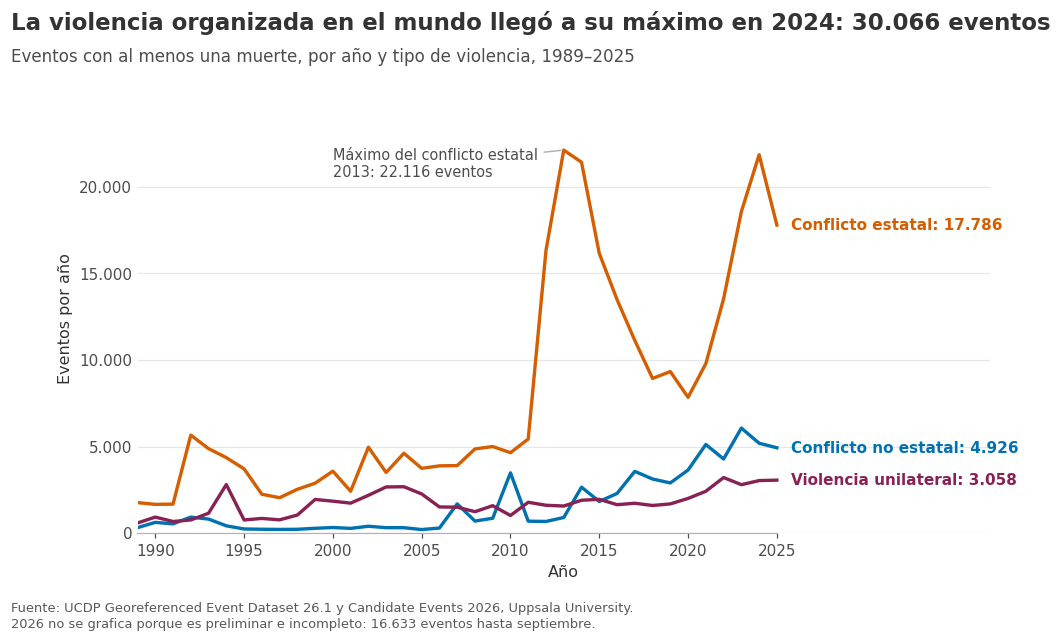

In [24]:
anual_tipo = (ucdp[ucdp["anio"] <= ANIO_COMPLETO_UCDP]
              .groupby(["anio", "tipo_violencia"], observed=True).size().unstack())
total_anual = anual_tipo.sum(axis=1)
anio_pico, total_pico = int(total_anual.idxmax()), int(total_anual.max())
eventos_parcial = int((ucdp["anio"] > ANIO_COMPLETO_UCDP).sum())

fig, ax = plt.subplots(figsize=(10, 5.8))
finales = [anual_tipo[t].iloc[-1] for t in eg.TIPOS_UCDP]
posiciones = eg.separar_etiquetas(finales, distancia_minima=total_pico * 0.045)
for (tipo, color), y_etiqueta in zip(eg.TIPOS_UCDP.items(), posiciones):
    serie = anual_tipo[tipo]
    ax.plot(serie.index, serie.values, color=color, linewidth=2.2)
    ax.text(serie.index[-1] + 0.8, y_etiqueta, f"{tipo}: {eg.formato_miles(serie.iloc[-1])}",
            color=color, fontsize=10, fontweight="bold", va="center")
pico_estatal = anual_tipo["Conflicto estatal"]
ax.annotate(f"Máximo del conflicto estatal\n{int(pico_estatal.idxmax())}: {eg.formato_miles(pico_estatal.max())} eventos",
            xy=(pico_estatal.idxmax(), pico_estatal.max()), xytext=(pico_estatal.idxmax() - 13, pico_estatal.max() * 0.93),
            fontsize=9.5, color=eg.GRIS_TEXTO, arrowprops=dict(arrowstyle="-", color=eg.GRIS_CONTEXTO))
ax.set_xlim(anual_tipo.index.min(), ANIO_COMPLETO_UCDP + 12)
ax.set_xticks([anio for anio in range(1990, ANIO_COMPLETO_UCDP + 1, 5)])  # sin marcas de años sin datos
ax.spines["bottom"].set_bounds(anual_tipo.index.min(), ANIO_COMPLETO_UCDP)
ax.set_ylim(0, anual_tipo.max().max() * 1.12)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(eg.formato_miles))
ax.set_ylabel("Eventos por año")
ax.set_xlabel("Año")
eg.grilla(ax, "y")

titulo = f"La violencia organizada en el mundo llegó a su máximo en {anio_pico}: {eg.formato_miles(total_pico)} eventos"
eg.encabezado(fig, titulo, f"Eventos con al menos una muerte, por año y tipo de violencia, 1989–{ANIO_COMPLETO_UCDP}")
eg.pie_de_fuente(fig, f"{FUENTE_UCDP}\n2026 no se grafica porque es preliminar e incompleto: "
                      f"{eg.formato_miles(eventos_parcial)} eventos hasta septiembre.")
publicar(fig, "01_ucdp_evolucion_tipo", titulo, "Líneas", "Pregunta 1", "Cualitativa (Okabe-Ito + vino)",
         f"Líneas de eventos anuales por tipo de violencia entre 1989 y {ANIO_COMPLETO_UCDP}. El conflicto estatal domina "
         f"y el total alcanza su máximo en {anio_pico} con {total_pico} eventos.")

#### Visualización 2 — Dónde se concentra la violencia organizada (pregunta 1)
- **Tipo:** mapa de calor, indicado para dos dimensiones categóricas (región × quinquenio) con una cantidad (unidad 4).
- **Color:** paleta **secuencial** `cividis`: una sola escala de luminosidad, de oscuro (pocos eventos) a claro (muchos), perceptualmente uniforme y apta para daltonismo (unidad 2). Cada celda lleva su valor escrito, así que no depende solo del color.
- **Qué muestra:** La violencia organizada se desplaza entre regiones según los conflictos de cada época: el pico de Medio Oriente coincide con la guerra en Siria e Irak, y el salto de Europa en la década de 2020 con la guerra en Ucrania. América, donde está Colombia, tiene su mayor actividad en los periodos más recientes, impulsada en buena parte por la violencia entre grupos criminales.

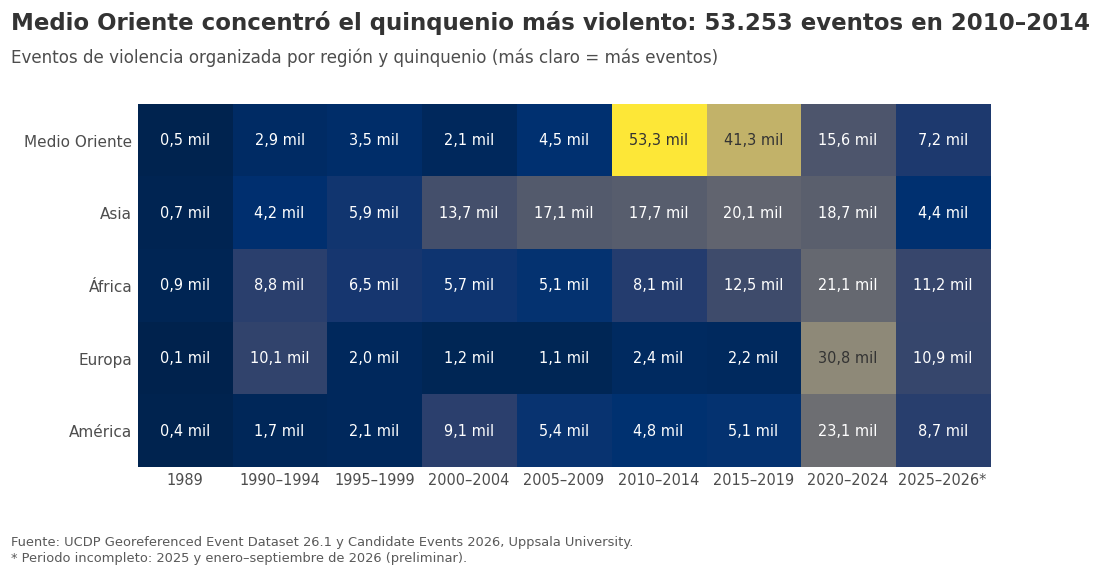

In [25]:
regional = (ucdp.assign(quinquenio=(ucdp["anio"] // 5) * 5)
            .pivot_table(index="region", columns="quinquenio", values="id", aggfunc="size", observed=True)
            .fillna(0))
regional = regional.loc[regional.sum(axis=1).sort_values(ascending=False).index]
etiquetas_periodo = []
for inicio in regional.columns:
    desde, hasta = max(inicio, 1989), min(inicio + 4, int(ucdp["anio"].max()))
    etiqueta = str(desde) if desde == hasta else f"{desde}–{hasta}"
    etiquetas_periodo.append(etiqueta + "*" if hasta > ANIO_COMPLETO_UCDP else etiqueta)

region_max, periodo_max = np.unravel_index(regional.values.argmax(), regional.shape)
fig, ax = plt.subplots(figsize=(10, 5.2))
imagen = ax.imshow(regional.values, cmap=eg.MAPA_SECUENCIAL, aspect="auto")
maximo = regional.values.max()
for i in range(regional.shape[0]):
    for j in range(regional.shape[1]):
        valor = regional.values[i, j]
        color_texto = "white" if valor / maximo < 0.55 else eg.GRIS_OSCURO
        ax.text(j, i, f"{valor / 1000:.1f} mil".replace(".", ","), ha="center", va="center", fontsize=9.5, color=color_texto)
ax.set_xticks(range(len(etiquetas_periodo)), etiquetas_periodo, fontsize=9.5)
ax.set_yticks(range(len(regional.index)), [REGIONES_ES.get(r, r) for r in regional.index])
ax.tick_params(length=0)
for borde in ax.spines.values():
    borde.set_visible(False)
# Sin barra de color: cada celda ya muestra su valor (se evita tinta redundante)

nombre_region = REGIONES_ES.get(regional.index[region_max], regional.index[region_max])
titulo = (f"{nombre_region} concentró el quinquenio más violento: "
          f"{eg.formato_miles(maximo)} eventos en {etiquetas_periodo[periodo_max]}")
eg.encabezado(fig, titulo, "Eventos de violencia organizada por región y quinquenio (más claro = más eventos)")
eg.pie_de_fuente(fig, f"{FUENTE_UCDP}\n* Periodo incompleto: 2025 y enero–septiembre de 2026 (preliminar).")
publicar(fig, "02_ucdp_region_quinquenio", titulo, "Mapa de calor", "Pregunta 1", "Secuencial (cividis)",
         "Mapa de calor de eventos por región (filas) y quinquenio (columnas) con el valor escrito en cada celda.")

#### Visualización 3 — Qué arma se usa en cada tipo de homicidio (pregunta 2)
- **Tipo:** barras horizontales apiladas al 100 %, para mostrar la composición de un todo en pocas categorías con etiquetas largas (unidad 4).
- **Color:** jerarquía por color (unidad 3): el arma de fuego, que es el foco de la pregunta, va en el naranja reservado para ella; las demás armas van en grises de más oscuro a más claro. El porcentaje va escrito dentro de cada segmento.
- **Qué muestra:** El arma de fuego domina en las cuatro categorías, pero con diferencias que el modelo puede aprovechar: en el sicariato y el crimen organizado es prácticamente la única arma, mientras que en las riñas casi la mitad de las víctimas muere por arma blanca u objetos contundentes. El conflicto armado tiene además una parte visible de explosivos, que aparecen en "otras armas y medios".

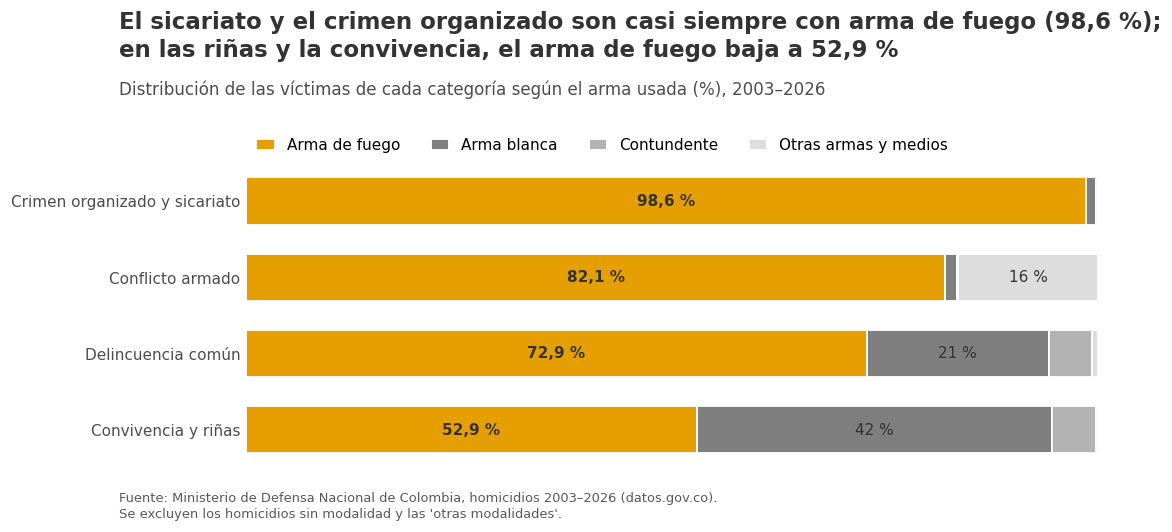

arma_resumen,Arma de fuego,Arma blanca,Contundente,Otras armas y medios,"de ellas, explosivos"
categoria_violencia,,,,,
Convivencia y riñas,52.9,41.6,5.2,0.3,0.1
Delincuencia común,72.9,21.3,5.1,0.7,0.0
Conflicto armado,82.1,1.4,0.1,16.4,16.1
Crimen organizado y sicariato,98.6,1.1,0.2,0.1,0.0


In [26]:
ARMAS_ORDEN = ["Arma de fuego", "Arma blanca", "Contundente", "Otras armas y medios"]
COLORES_ARMA = {"Arma de fuego": eg.ARMA_DE_FUEGO, "Arma blanca": "#7F7F7F", "Contundente": "#B3B3B3",
                "Otras armas y medios": "#DDDDDD"}

con_clase = hom[hom["objetivo_modelo"]].copy()
con_clase["arma_resumen"] = con_clase["arma_grupo"].astype(str).where(
    con_clase["arma_grupo"].isin(ARMAS_ORDEN[:3]), "Otras armas y medios")
armas_categoria = (con_clase.pivot_table(index="categoria_violencia", columns="arma_resumen", values="cantidad",
                                         aggfunc="sum", observed=True)
                   .reindex(index=CLASES_MODELO, columns=ARMAS_ORDEN).fillna(0))
pct_armas = (armas_categoria.div(armas_categoria.sum(axis=1), axis=0) * 100).sort_values("Arma de fuego")

fig, ax = plt.subplots(figsize=(10, 4.8))
izquierda = np.zeros(len(pct_armas))
for arma in ARMAS_ORDEN:
    valores = pct_armas[arma].values
    ax.barh(pct_armas.index, valores, left=izquierda, color=COLORES_ARMA[arma], height=0.62,
            edgecolor="white", linewidth=1.2, label=arma)
    for fila, (inicio, ancho) in enumerate(zip(izquierda, valores)):
        if ancho >= 6:
            ax.text(inicio + ancho / 2, fila, eg.porcentaje(ancho, 0 if arma != "Arma de fuego" else 1),
                    ha="center", va="center", fontsize=10, color=eg.GRIS_OSCURO,
                    fontweight="bold" if arma == "Arma de fuego" else "normal")
    izquierda += valores
ax.set_xlim(0, 100)
ax.xaxis.set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=10, handlelength=1.2, borderaxespad=0.3)

fuego = pct_armas["Arma de fuego"]
titulo = (f"El sicariato y el crimen organizado son casi siempre con arma de fuego ({eg.porcentaje(fuego['Crimen organizado y sicariato'])});\n"
          f"en las riñas y la convivencia, el arma de fuego baja a {eg.porcentaje(fuego['Convivencia y riñas'])}")
eg.encabezado(fig, titulo, "Distribución de las víctimas de cada categoría según el arma usada (%), 2003–2026", espacio_extra=0.25)
eg.pie_de_fuente(fig, f"{FUENTE_HOM}\nSe excluyen los homicidios sin modalidad y las 'otras modalidades'.", espacio_ejes=0.15)
publicar(fig, "03_arma_por_categoria", titulo, "Barras apiladas al 100 %", "Pregunta 2", "Acento naranja + grises",
         "Barras horizontales al 100 % para cuatro categorías de violencia, con el porcentaje de víctimas por arma de fuego, "
         "arma blanca, contundente y otras.")
explosivos = (con_clase[con_clase["arma_grupo"] == "Explosivos"].groupby("categoria_violencia", observed=True)["cantidad"].sum()
              .reindex(CLASES_MODELO).fillna(0) / armas_categoria.sum(axis=1) * 100)
pct_armas.round(1).assign(**{"de ellas, explosivos": explosivos.round(1)})

#### Visualización 4 — Cómo cambió la composición de los homicidios (pregunta 3)
- **Tipo:** barras apiladas al 100 % por año, la forma que la unidad 4 recomienda para la evolución de proporciones en el tiempo. Se marca la firma del Acuerdo de Paz con una línea de referencia.
- **Color:** las cuatro categorías del modelo con sus colores fijos; *Otras modalidades* y *Sin información* en grises, porque son contexto. Las categorías se etiquetan directamente a la derecha.
- **Qué muestra:** La gráfica muestra un cambio de fondo en la violencia homicida de Colombia: el crimen organizado y el sicariato ganan peso año tras año, hasta ser la mayoría de los homicidios, mientras las riñas pierden participación. El conflicto armado baja a su mínimo alrededor de la firma del Acuerdo de Paz y vuelve a crecer en los años siguientes; en el parcial de 2026 alcanza su mayor participación de toda la serie. Los primeros años (2003–2005) deben leerse con cuidado, porque muchos registros no tienen modalidad.

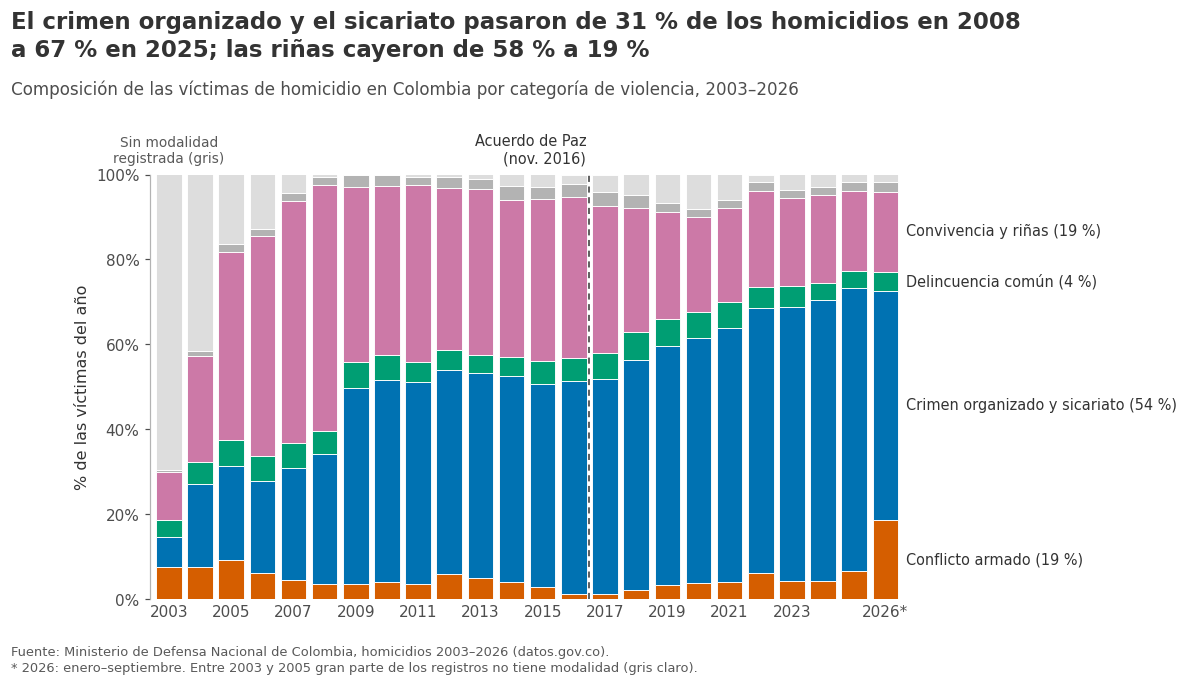

Conflicto armado: 1,3 % en 2016, 6,7 % en 2025 y 18,5 % en 2026 (parcial)


In [27]:
ORDEN_APILADO = ["Conflicto armado", "Crimen organizado y sicariato", "Delincuencia común",
                 "Convivencia y riñas", "Otras modalidades", "Sin información"]
composicion = (hom.pivot_table(index="anio", columns="categoria_violencia", values="cantidad", aggfunc="sum", observed=True)
               .reindex(columns=ORDEN_APILADO).fillna(0))
pct_anual = composicion.div(composicion.sum(axis=1), axis=0) * 100
ultimo_anio = int(pct_anual.index.max())

fig, ax = plt.subplots(figsize=(11, 6.2))
abajo = np.zeros(len(pct_anual))
for categoria in ORDEN_APILADO:
    ax.bar(pct_anual.index, pct_anual[categoria], bottom=abajo, width=0.82,
           color=eg.CATEGORIAS_VIOLENCIA[categoria], edgecolor="white", linewidth=0.6)
    if categoria in CLASES_MODELO:
        centro = abajo[-1] + pct_anual[categoria].iloc[-1] / 2
        ax.text(ultimo_anio + 0.65, centro, f"{categoria} ({eg.porcentaje(pct_anual[categoria].iloc[-1], 0)})",
                va="center", fontsize=9.5, color=eg.GRIS_OSCURO)
    abajo += pct_anual[categoria].values

ax.axvline(2016.5, color=eg.GRIS_OSCURO, linewidth=1, linestyle=(0, (4, 3)))
ax.text(2016.4, 102, "Acuerdo de Paz\n(nov. 2016)", ha="right", va="bottom", fontsize=9.5, color=eg.GRIS_OSCURO)
ax.text(2003, 102, "Sin modalidad\nregistrada (gris)", ha="center", va="bottom", fontsize=9, color=eg.GRIS_FUENTE)
anios = list(pct_anual.index)
# Años impares + el año parcial; se omite el penúltimo si choca con la etiqueta del parcial
ax.set_xticks(anios, [f"{a}*" if a > ANIO_COMPLETO_HOM else (str(a) if a % 2 == 1 and a < ultimo_anio - 1 else "")
                      for a in anios])
ax.set_xlim(anios[0] - 0.6, ultimo_anio + 6.5)
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_ylabel("% de las víctimas del año")
ax.spines["bottom"].set_visible(False)
ax.tick_params(axis="x", length=0)

base, final = 2008, ANIO_COMPLETO_HOM
crimen = pct_anual["Crimen organizado y sicariato"]
titulo = (f"El crimen organizado y el sicariato pasaron de {eg.porcentaje(crimen[base], 0)} de los homicidios en {base}\n"
          f"a {eg.porcentaje(crimen[final], 0)} en {final}; las riñas cayeron de "
          f"{eg.porcentaje(pct_anual['Convivencia y riñas'][base], 0)} a {eg.porcentaje(pct_anual['Convivencia y riñas'][final], 0)}")
eg.encabezado(fig, titulo, f"Composición de las víctimas de homicidio en Colombia por categoría de violencia, 2003–{ultimo_anio}",
              espacio_extra=0.35)
eg.pie_de_fuente(fig, f"{FUENTE_HOM}\n* {ultimo_anio}: enero–septiembre. Entre 2003 y 2005 gran parte de los registros no tiene modalidad (gris claro).",
                 espacio_ejes=0.35)
publicar(fig, "04_composicion_anual", titulo, "Barras apiladas al 100 %", "Pregunta 3", "Cualitativa Okabe-Ito + grises",
         f"Barras apiladas al 100 % por año de 2003 a {ultimo_anio} con la proporción de víctimas por categoría de violencia "
         "y una línea vertical en la firma del Acuerdo de Paz.")
print(f"Conflicto armado: {eg.porcentaje(pct_anual['Conflicto armado'][2016])} en 2016, "
      f"{eg.porcentaje(pct_anual['Conflicto armado'][final])} en {final} y "
      f"{eg.porcentaje(pct_anual['Conflicto armado'][ultimo_anio])} en {ultimo_anio} (parcial)")

#### Visualización 5 — Antes y después del Acuerdo de Paz (pregunta 3)
- **Tipo:** *slope graph* (gráfico de pendiente), recomendado para datos pareados del tipo "antes frente a después" (unidad 4). Cada línea es una categoría y su inclinación muestra si subió o bajó.
- **Periodos:** 2008–2016 frente a 2017 hasta el último año completo. Se parte de 2008 y no de 2003 porque antes de 2008 una parte importante de los registros no tiene modalidad, lo que haría parecer que todas las categorías crecieron.
- **Color:** colores fijos de cada categoría y etiquetas directas en ambos extremos.
- **Qué muestra:** El Acuerdo de Paz no redujo la violencia homicida en general: la cambió de forma. Las riñas caen a casi la mitad; el conflicto armado y la delincuencia común quedan prácticamente estables en promedio (aunque el conflicto repunta en los últimos años, como muestra la visualización 4); y el crimen organizado y el sicariato suben hasta ser la principal fuente de homicidios. Es una señal de que las economías ilegales que dejó el conflicto siguen produciendo violencia con otros actores y otras modalidades.

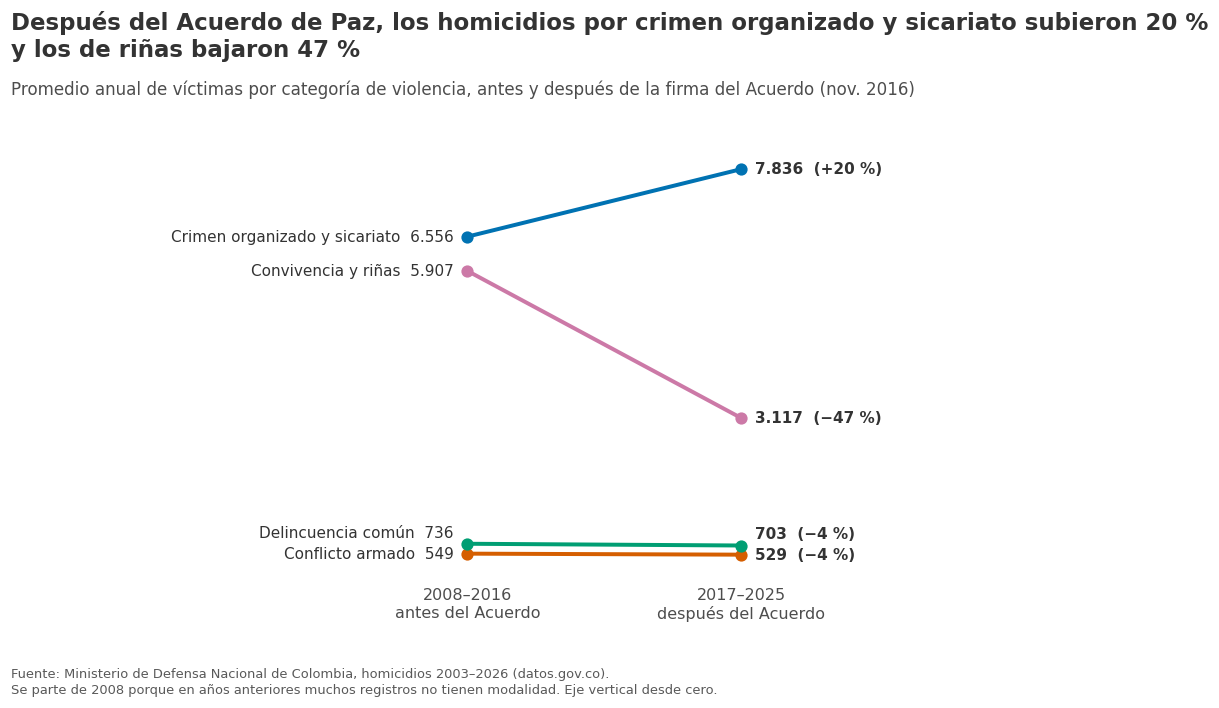

,antes,después,cambio_%
categoria_violencia,,,
Conflicto armado,549.0,529.0,-3.5
Crimen organizado y sicariato,6556.0,7836.0,19.5
Convivencia y riñas,5907.0,3117.0,-47.2
Delincuencia común,736.0,703.0,-4.5


In [28]:
ANTES, DESPUES = (2008, 2016), (2017, ANIO_COMPLETO_HOM)

def promedio_anual(desde, hasta):
    periodo = hom[hom["anio"].between(desde, hasta) & hom["objetivo_modelo"]]
    return periodo.groupby("categoria_violencia", observed=True)["cantidad"].sum().reindex(CLASES_MODELO) / (hasta - desde + 1)

promedio_antes, promedio_despues = promedio_anual(*ANTES), promedio_anual(*DESPUES)
cambio_pct = (promedio_despues / promedio_antes - 1) * 100

fig, ax = plt.subplots(figsize=(9, 6.4))
escala = max(promedio_antes.max(), promedio_despues.max())
pos_izq = eg.separar_etiquetas(promedio_antes.values, escala * 0.05)
pos_der = eg.separar_etiquetas(promedio_despues.values, escala * 0.05)
for i, categoria in enumerate(CLASES_MODELO):
    color = eg.CATEGORIAS_VIOLENCIA[categoria]
    ax.plot([0, 1], [promedio_antes[categoria], promedio_despues[categoria]], color=color, linewidth=2.6,
            marker="o", markersize=7)
    ax.text(-0.05, pos_izq[i], f"{categoria}  {eg.formato_miles(promedio_antes[categoria])}",
            ha="right", va="center", fontsize=10, color=eg.GRIS_OSCURO)
    ax.text(1.05, pos_der[i], f"{eg.formato_miles(promedio_despues[categoria])}  ({cambio_pct[categoria]:+.0f} %)".replace("-", "−"),
            ha="left", va="center", fontsize=10, color=eg.GRIS_OSCURO, fontweight="bold")
ax.set_xlim(-1.25, 1.55)
ax.set_ylim(0, escala * 1.08)
ax.set_xticks([0, 1], [f"{ANTES[0]}–{ANTES[1]}\nantes del Acuerdo", f"{DESPUES[0]}–{DESPUES[1]}\ndespués del Acuerdo"],
              fontsize=10.5)
ax.yaxis.set_visible(False)
for lado in ["left", "bottom"]:
    ax.spines[lado].set_visible(False)
ax.tick_params(axis="x", length=0)

def verbo(cambio):
    return f"subieron {abs(cambio):.0f} %" if cambio > 0 else f"bajaron {abs(cambio):.0f} %"

titulo = (f"Después del Acuerdo de Paz, los homicidios por crimen organizado y sicariato {verbo(cambio_pct['Crimen organizado y sicariato'])}\n"
          f"y los de riñas {verbo(cambio_pct['Convivencia y riñas'])}")
eg.encabezado(fig, titulo, "Promedio anual de víctimas por categoría de violencia, antes y después de la firma del Acuerdo (nov. 2016)")
eg.pie_de_fuente(fig, f"{FUENTE_HOM}\nSe parte de 2008 porque en años anteriores muchos registros no tienen modalidad. Eje vertical desde cero.",
                 espacio_ejes=0.7)
publicar(fig, "05_antes_despues_acuerdo", titulo, "Slope graph", "Pregunta 3", "Cualitativa Okabe-Ito",
         "Gráfico de pendiente con el promedio anual de víctimas de cuatro categorías antes (2008–2016) y después (2017 en adelante) "
         "del Acuerdo de Paz.")
pd.DataFrame({"antes": promedio_antes.round(0), "después": promedio_despues.round(0), "cambio_%": cambio_pct.round(1)})

#### Visualización 6 — Cuándo ocurre cada tipo de homicidio (preguntas 2 y 3, y variables del modelo)
- **Tipo:** mapa de calor categoría × día de la semana, el uso que la unidad 4 menciona para "actividad por hora o día".
- **Normalización:** cada fila suma 100 %, para comparar el patrón semanal de categorías de tamaños muy distintos.
- **Color:** secuencial `cividis` con el porcentaje escrito en cada celda.
- **Qué muestra:** Las riñas tienen un patrón semanal muy marcado (fin de semana, y sobre todo domingo), asociado al consumo de alcohol y a la vida social. El conflicto armado, en cambio, se reparte casi por igual entre los siete días. Esta diferencia justifica usar `dia_semana` y `fin_de_semana` como variables del modelo.

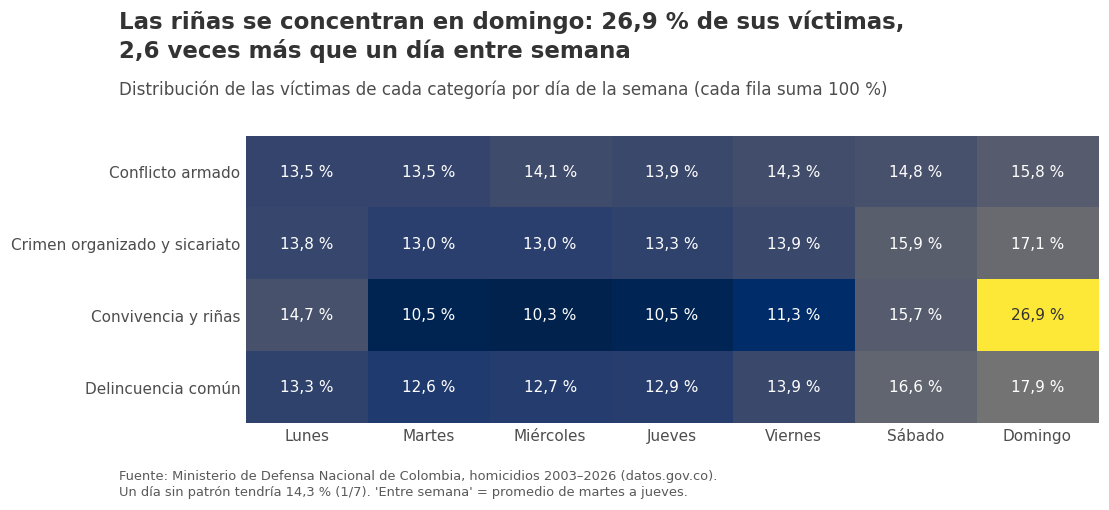

In [29]:
semana = (hom[hom["objetivo_modelo"]]
          .pivot_table(index="categoria_violencia", columns="dia_semana", values="cantidad", aggfunc="sum", observed=True)
          .reindex(index=CLASES_MODELO))
pct_semana = semana.div(semana.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, 4.6))
imagen = ax.imshow(pct_semana.values, cmap=eg.MAPA_SECUENCIAL, aspect="auto")
vmin, vmax = pct_semana.values.min(), pct_semana.values.max()
for i in range(pct_semana.shape[0]):
    for j in range(pct_semana.shape[1]):
        valor = pct_semana.values[i, j]
        color_texto = "white" if (valor - vmin) / (vmax - vmin) < 0.55 else eg.GRIS_OSCURO
        ax.text(j, i, eg.porcentaje(valor), ha="center", va="center", fontsize=10, color=color_texto)
ax.set_xticks(range(7), pct_semana.columns)
ax.set_yticks(range(len(CLASES_MODELO)), CLASES_MODELO)
ax.tick_params(length=0)
for borde in ax.spines.values():
    borde.set_visible(False)
# Sin barra de color: cada celda ya muestra su porcentaje

domingo = pct_semana.loc["Convivencia y riñas", "Domingo"]
entre_semana = pct_semana.loc["Convivencia y riñas", ["Martes", "Miércoles", "Jueves"]].mean()
titulo = (f"Las riñas se concentran en domingo: {eg.porcentaje(domingo)} de sus víctimas,\n"
          f"{domingo / entre_semana:.1f} veces más que un día entre semana".replace(".", ","))
eg.encabezado(fig, titulo, "Distribución de las víctimas de cada categoría por día de la semana (cada fila suma 100 %)")
eg.pie_de_fuente(fig, f"{FUENTE_HOM}\nUn día sin patrón tendría 14,3 % (1/7). 'Entre semana' = promedio de martes a jueves.",
                 espacio_ejes=0.35)
publicar(fig, "06_dia_semana_categoria", titulo, "Mapa de calor", "Preguntas 2 y 3", "Secuencial (cividis)",
         "Mapa de calor de cuatro categorías por siete días con el porcentaje de víctimas en cada celda; las riñas destacan el domingo.")

#### Visualización 7 — Conflicto armado y homicidios por departamento (pregunta 4)
- **Tipo:** diagrama de dispersión, la visualización arquetípica para la relación entre dos variables cuantitativas (unidad 4). Cada punto es un departamento.
- **Color:** puntos de contexto en gris y acento bermellón (color del conflicto armado) solo en los departamentos destacados, que llevan su nombre.
- **Medida de asociación:** correlación de Spearman, porque es robusta a valores extremos y no supone relación lineal.
- **Qué muestra:** La relación es positiva y moderada: los departamentos con más eventos registrados por UCDP tienden a tener una parte mayor de homicidios atribuidos al conflicto armado, lo que confirma que las dos fuentes, construidas de forma independiente, cuentan una historia coherente. La relación con el crimen organizado y el sicariato también es positiva (ver el valor impreso arriba): donde hay grupos armados, también hay más violencia criminal. Hay casos que se apartan del patrón, como Arauca, donde casi todos los homicidios se atribuyen al conflicto aunque el número de eventos no es el mayor; y Valle del Cauca o Antioquia, con muchos homicidios urbanos que diluyen el porcentaje.

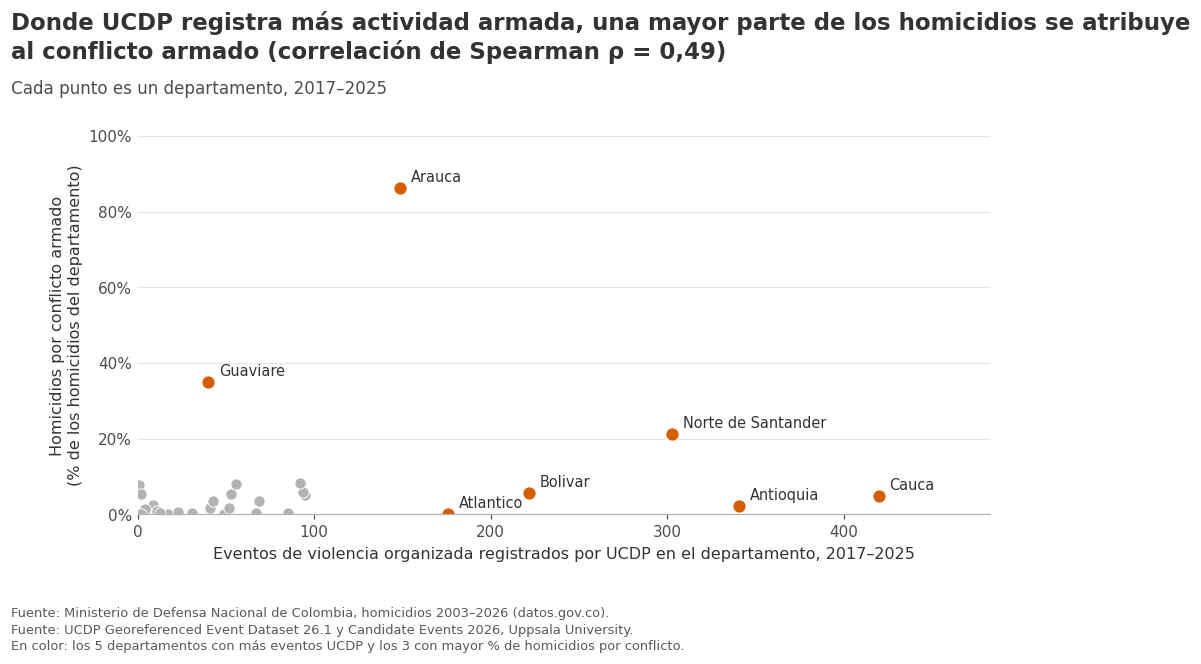

Spearman eventos UCDP vs % conflicto armado: 0.49 | vs % crimen organizado y sicariato: 0.42


,victimas,pct_conflicto,pct_crimen,eventos_ucdp
depto_clave,,,,
CAUCA,7003,4.9,66.8,420.0
ANTIOQUIA,17919,2.2,68.8,341.0
NORTE DE SANTANDER,5016,21.3,53.2,303.0
BOLIVAR,4736,5.7,50.5,222.0
ATLANTICO,6017,0.1,68.3,176.0
ARAUCA,1454,86.3,2.5,149.0
CHOCO,2160,5.0,78.4,95.0
NARINO,4504,5.9,66.4,94.0


In [30]:
RANGO_DEPTOS = (2017, ANIO_COMPLETO_HOM)
recientes = hom[hom["anio"].between(*RANGO_DEPTOS)]
por_depto = recientes.groupby("depto_clave", observed=True).agg(victimas=("cantidad", "sum"))
por_depto["pct_conflicto"] = (recientes[recientes["categoria_violencia"] == "Conflicto armado"]
                              .groupby("depto_clave", observed=True)["cantidad"].sum()
                              .reindex(por_depto.index).fillna(0) / por_depto["victimas"] * 100)
por_depto["pct_crimen"] = (recientes[recientes["categoria_violencia"] == "Crimen organizado y sicariato"]
                           .groupby("depto_clave", observed=True)["cantidad"].sum()
                           .reindex(por_depto.index).fillna(0) / por_depto["victimas"] * 100)
por_depto["eventos_ucdp"] = (ucdp[ucdp["depto_clave"].notna() & ucdp["anio"].between(*RANGO_DEPTOS)]
                             .groupby("depto_clave", observed=True).size()
                             .reindex(por_depto.index).fillna(0))
rho_conflicto = por_depto["eventos_ucdp"].corr(por_depto["pct_conflicto"], method="spearman")
rho_crimen = por_depto["eventos_ucdp"].corr(por_depto["pct_crimen"], method="spearman")

destacados = set(por_depto.nlargest(5, "eventos_ucdp").index) | set(por_depto.nlargest(3, "pct_conflicto").index)
fig, ax = plt.subplots(figsize=(10, 6))
normales = por_depto.drop(index=list(destacados))
ax.scatter(normales["eventos_ucdp"], normales["pct_conflicto"], s=55, color=eg.GRIS_CONTEXTO, edgecolor="white", linewidth=0.6)
resaltados = por_depto.loc[list(destacados)]
ax.scatter(resaltados["eventos_ucdp"], resaltados["pct_conflicto"], s=75, color=eg.CATEGORIAS_VIOLENCIA["Conflicto armado"],
           edgecolor="white", linewidth=0.6)
for depto, fila in resaltados.iterrows():
    ax.annotate(depto.title().replace(" De ", " de ").replace(" Del ", " del "), (fila["eventos_ucdp"], fila["pct_conflicto"]),
                xytext=(7, 4), textcoords="offset points", fontsize=9.5, color=eg.GRIS_OSCURO)
ax.set_xlim(0, por_depto["eventos_ucdp"].max() * 1.15)
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel(f"Eventos de violencia organizada registrados por UCDP en el departamento, {RANGO_DEPTOS[0]}–{RANGO_DEPTOS[1]}")
ax.set_ylabel("Homicidios por conflicto armado\n(% de los homicidios del departamento)")
eg.grilla(ax, "y")

titulo = (f"Donde UCDP registra más actividad armada, una mayor parte de los homicidios se atribuye\n"
          f"al conflicto armado (correlación de Spearman ρ = {rho_conflicto:.2f})").replace("0.", "0,")
eg.encabezado(fig, titulo, f"Cada punto es un departamento, {RANGO_DEPTOS[0]}–{RANGO_DEPTOS[1]}")
eg.pie_de_fuente(fig, f"{FUENTE_HOM}\n{FUENTE_UCDP}\nEn color: los 5 departamentos con más eventos UCDP y los 3 con mayor % de homicidios por conflicto.",
                 espacio_ejes=0.75)
publicar(fig, "07_departamentos_ucdp_conflicto", titulo, "Dispersión", "Pregunta 4", "Gris de contexto + acento bermellón",
         "Diagrama de dispersión de 33 departamentos: eventos UCDP en el eje x y porcentaje de homicidios por conflicto armado en el eje y.")
print(f"Spearman eventos UCDP vs % conflicto armado: {rho_conflicto:.2f} | vs % crimen organizado y sicariato: {rho_crimen:.2f}")
por_depto.sort_values("eventos_ucdp", ascending=False).head(8).round(1)

#### Visualización 8 — Actividad armada previa según el tipo de homicidio (pregunta 4 y variable del modelo)
- **Tipo:** *boxplot*, adecuado para comparar la distribución de una variable entre 2 a 5 grupos (unidad 4): muestra mediana, cuartiles y dispersión de forma compacta.
- **Variable:** `eventos_ucdp_12m`, creada en el enriquecimiento: eventos de violencia organizada en el departamento durante los 12 meses anteriores a cada homicidio.
- **Color:** cada caja con el color fijo de su categoría; la mediana en negro y su valor escrito al lado.
- **Qué muestra:** La variable de enriquecimiento separa bien al conflicto armado de las demás categorías: sus homicidios ocurren en departamentos con mucha más actividad armada reciente. Para las otras tres categorías las distribuciones se parecen entre sí, así que el modelo tendrá que apoyarse en otras variables (arma, zona, día de la semana) para distinguirlas.

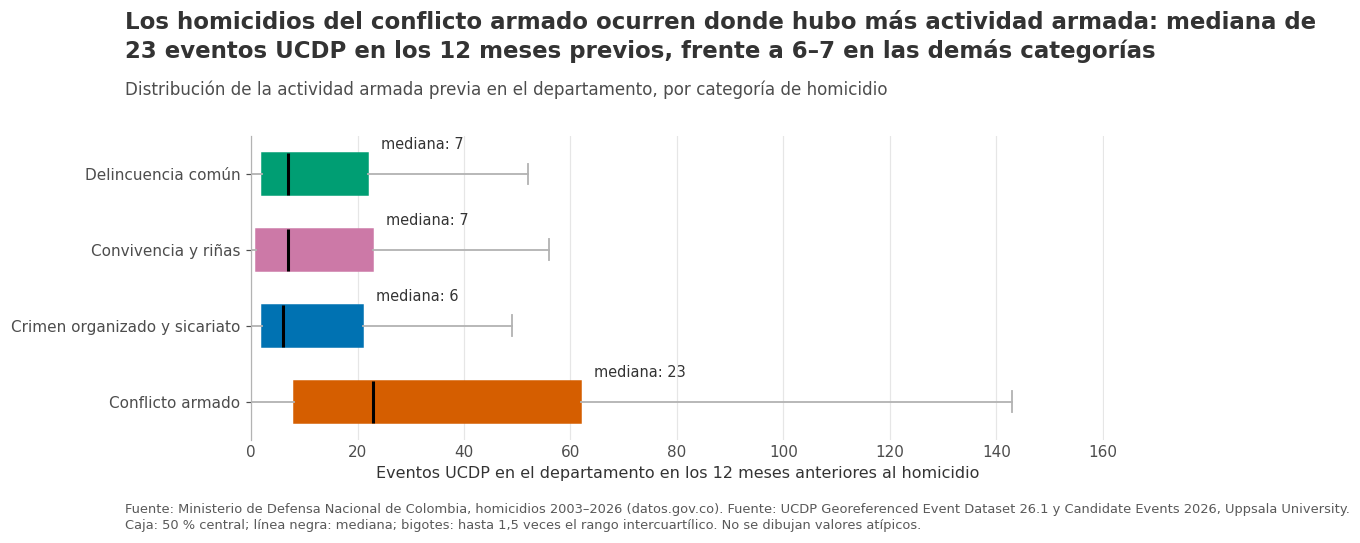

In [31]:
grupos = [hom.loc[hom["categoria_violencia"] == categoria, "eventos_ucdp_12m"].values for categoria in CLASES_MODELO]
medianas = {categoria: float(np.median(valores)) for categoria, valores in zip(CLASES_MODELO, grupos)}

fig, ax = plt.subplots(figsize=(10, 4.9))
cajas = ax.boxplot(grupos, vert=False, showfliers=False, patch_artist=True, widths=0.55,
                   medianprops=dict(color="black", linewidth=2),
                   whiskerprops=dict(color=eg.GRIS_CONTEXTO, linewidth=1.2),
                   capprops=dict(color=eg.GRIS_CONTEXTO, linewidth=1.2))
for caja, categoria in zip(cajas["boxes"], CLASES_MODELO):
    caja.set_facecolor(eg.CATEGORIAS_VIOLENCIA[categoria])
    caja.set_edgecolor(eg.CATEGORIAS_VIOLENCIA[categoria])
limite_x = max(linea.get_xdata().max() for linea in cajas["whiskers"]) * 1.12
for fila, categoria in enumerate(CLASES_MODELO, start=1):
    q3 = np.percentile(grupos[fila - 1], 75)
    ax.text(q3 + limite_x * 0.015, fila + 0.33, f"mediana: {medianas[categoria]:.0f}", fontsize=9.5, color=eg.GRIS_OSCURO)
ax.set_yticks(range(1, len(CLASES_MODELO) + 1), CLASES_MODELO)
ax.set_xlim(0, limite_x)
ax.set_xlabel("Eventos UCDP en el departamento en los 12 meses anteriores al homicidio")
eg.grilla(ax, "x")

otras_medianas = [medianas[c] for c in CLASES_MODELO if c != "Conflicto armado"]
titulo = (f"Los homicidios del conflicto armado ocurren donde hubo más actividad armada: mediana de\n"
          f"{medianas['Conflicto armado']:.0f} eventos UCDP en los 12 meses previos, frente a {min(otras_medianas):.0f}–{max(otras_medianas):.0f} en las demás categorías")
eg.encabezado(fig, titulo, "Distribución de la actividad armada previa en el departamento, por categoría de homicidio")
eg.pie_de_fuente(fig, f"{FUENTE_HOM} {FUENTE_UCDP}\nCaja: 50 % central; línea negra: mediana; bigotes: hasta 1,5 veces el rango intercuartílico. "
                      "No se dibujan valores atípicos.", espacio_ejes=0.5)
publicar(fig, "08_ucdp_previo_por_categoria", titulo, "Boxplot", "Pregunta 4", "Cualitativa Okabe-Ito",
         "Cuatro diagramas de caja horizontales con la distribución de eventos UCDP previos por categoría de homicidio; "
         "el conflicto armado tiene la mediana más alta.")

## 8. Machine Learning (Modeling + Evaluation)

### 8.1 Planteamiento
- **Tarea:** clasificación multiclase. Dado un homicidio con arma (dónde, cuándo, con qué y en qué contexto de conflicto ocurrió), predecir a cuál de las cuatro categorías de violencia pertenece: *Conflicto armado*, *Crimen organizado y sicariato*, *Convivencia y riñas* o *Delincuencia común*.
- **Utilidad para el negocio:** cerca del 10 % de los homicidios llega sin modalidad. Un clasificador permite estimar a qué tipo de violencia corresponden, y sus variables más importantes indican qué señales distinguen la violencia del conflicto de la criminalidad urbana.
- **Datos:** registros con una de las cuatro clases, desde 2005. Se dejan fuera 2003 y 2004, años en que la mayoría de registros no tenía modalidad, lo que indica una forma de clasificar distinta.
- **Métrica principal: F1 macro.** Es el promedio simple del F1 de cada clase, así que una clase pequeña como *Conflicto armado* (cerca del 5 %) pesa lo mismo que la mayoritaria. La exactitud (*accuracy*) sería engañosa: predecir siempre *Crimen organizado* ya acierta más de la mitad de las veces.
- **Criterio de éxito (definido en la sección 1.4):** superar la F1 macro de la línea base en al menos 0,10 puntos y lograr un *recall* de al menos 0,50 en *Conflicto armado*.

### 8.2 Variables y prevención de la fuga de información (*data leakage*)
Las variables están definidas en `src/modelo.py`, que también usará el dashboard:

| Grupo | Variables | Codificación |
|---|---|---|
| Lugar | departamento, zona (urbana/rural) | One-hot (modelo lineal) u ordinal (árboles) |
| Municipio | código DANE del municipio (~1.100 valores) | *Target encoding* con validación cruzada interna |
| Víctima y hecho | sexo, arma usada, víctimas en el mismo hecho | One-hot u ordinal; el conteo con log + escalado |
| Tiempo | día de la semana, mes, fin de semana, después del Acuerdo de Paz | One-hot u ordinal; binarias como 0/1 |
| Contexto de conflicto | eventos y muertes UCDP en el departamento en los 12 meses anteriores | Log + escalado en el modelo lineal |

Cómo se evitó la fuga de información:
1. **Se excluye la modalidad presunta**, porque es la fuente de la variable objetivo, y la **caracterización SPOA** (homicidio o feminicidio), que la Fiscalía define durante la investigación, es decir, después del hecho.
2. **Las variables UCDP solo miran meses anteriores** al homicidio (`shift(1)` en la sección 6.5): no usan información del mismo mes ni posterior.
3. **División temporal y no aleatoria.** Se entrena con 2005–2022 y se evalúa con 2023 en adelante, como se usaría el modelo en la realidad (aprender del pasado y clasificar hechos nuevos). Una división aleatoria pondría en entrenamiento y prueba filas idénticas del mismo día y municipio (sección 6.1) y daría un resultado demasiado optimista.
4. **Los codificadores se ajustan solo con el entrenamiento**, dentro de un `Pipeline` de scikit-learn. El *target encoding* del municipio usa además validación cruzada interna, para que cada fila no vea su propia clase.
5. **La selección del modelo no usa el conjunto de prueba.** Los modelos se comparan con una validación interna (entrenar con 2005–2019 y validar con 2020–2022). El conjunto de prueba se usa una sola vez, al final.
6. **No se usa el año como variable**, porque en la prueba tomaría valores que el modelo nunca vio. La tendencia de largo plazo queda recogida por `post_acuerdo_paz` y las variables UCDP.

In [32]:
import json
from datetime import datetime, timezone

import joblib
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler, TargetEncoder

import modelo as mdl

import warnings
# Aviso inofensivo de SciPy reciente con el solver lbfgs de scikit-learn 1.5 (no afecta el resultado)
warnings.filterwarnings("ignore", message="Unknown solver options")

ANIO_INICIO_MODELO = 2005
FIN_ENTRENAMIENTO = 2022           # entrenamiento: 2005–2022 | prueba: 2023 en adelante
INICIO_VALIDACION = 2020           # validación interna para elegir el modelo: 2020–2022
SEMILLA = 42

datos_modelo = hom[hom["objetivo_modelo"] & (hom["anio"] >= ANIO_INICIO_MODELO)].copy()
X_todo = mdl.preparar_variables(datos_modelo)
y_todo = datos_modelo[mdl.OBJETIVO].astype(str)
anio_modelo = datos_modelo["anio"]

es_entrenamiento = anio_modelo <= FIN_ENTRENAMIENTO
X_train, y_train = X_todo[es_entrenamiento], y_todo[es_entrenamiento]
X_test, y_test = X_todo[~es_entrenamiento], y_todo[~es_entrenamiento]
es_subentrenamiento = anio_modelo[es_entrenamiento] < INICIO_VALIDACION
X_subtrain, y_subtrain = X_train[es_subentrenamiento], y_train[es_subentrenamiento]
X_val, y_val = X_train[~es_subentrenamiento], y_train[~es_subentrenamiento]

def distribucion(y):
    return (y.value_counts(normalize=True).reindex(mdl.CLASES) * 100).round(1)

particiones = pd.DataFrame({
    "periodo": [f"{ANIO_INICIO_MODELO}–{INICIO_VALIDACION - 1}", f"{INICIO_VALIDACION}–{FIN_ENTRENAMIENTO}",
                f"{ANIO_INICIO_MODELO}–{FIN_ENTRENAMIENTO}", f"{FIN_ENTRENAMIENTO + 1}–{int(anio_modelo.max())}"],
    "filas": [len(y_subtrain), len(y_val), len(y_train), len(y_test)],
}, index=["subentrenamiento", "validación", "entrenamiento completo", "prueba"])
particiones = particiones.join(pd.DataFrame({n: distribucion(y) for n, y in
                                             [("subentrenamiento", y_subtrain), ("validación", y_val),
                                              ("entrenamiento completo", y_train), ("prueba", y_test)]}).T)
print(f"Registros para el modelo: {len(X_todo):,} | variables: {X_todo.shape[1]}".replace(",", "."))
particiones

Registros para el modelo: 284.398 | variables: 12


,periodo,filas,Conflicto armado,Crimen organizado y sicariato,Convivencia y riñas,Delincuencia común
subentrenamiento,2005–2019,199035,4.4,45.2,44.5,5.9
validación,2020–2022,36403,5.1,64.7,24.1,6.1
entrenamiento completo,2005–2022,235438,4.5,48.2,41.3,6.0
prueba,2023–2026,48960,8.1,66.4,20.9,4.6


La tabla muestra el desbalance de clases (en %) y el cambio de composición en el tiempo: en la prueba hay más crimen organizado y menos riñas que en el entrenamiento. Es una prueba exigente y realista, porque el modelo debe funcionar con la violencia de hoy aunque aprendió con la de años anteriores. Para que las clases pequeñas no queden ignoradas, los modelos usan `class_weight="balanced"`, que da a cada clase un peso inversamente proporcional a su frecuencia.

### 8.3 Modelos
Se comparan una línea base y tres modelos de naturaleza distinta:

| Modelo | Por qué se incluye |
|---|---|
| **Línea base:** clase más frecuente | Referencia mínima: un modelo útil debe superarla con claridad |
| **Regresión logística** multinomial | Modelo lineal, rápido e interpretable |
| **Random Forest** | Captura interacciones entre variables (por ejemplo, zona rural × actividad UCDP) |
| **Gradient Boosting** (`HistGradientBoostingClassifier`) | Suele ser el más preciso en datos tabulares y maneja variables categóricas de forma nativa |

### 8.4 Entrenamiento y selección con validación temporal
Cada modelo se entrena dos veces: con 2005–2019 para medirlo en la validación (2020–2022), que es lo que decide cuál se elige, y con todo el entrenamiento (2005–2022) para la evaluación final en la prueba.

**Regla de selección, fijada antes de mirar la prueba:** entre los modelos que en la validación cumplen los dos criterios de éxito de la sección 1.4 (mejorar la F1 macro de la línea base en al menos 0,10 y tener un *recall* de al menos 0,50 en *Conflicto armado*), se elige el de mayor F1 macro. Si ninguno los cumple, se elige el de mayor F1 macro. Así el requisito de negocio (no perder de vista los homicidios del conflicto, la clase pequeña) pesa en la elección y no solo la métrica global.

In [33]:
n_categoricas = len(mdl.VARIABLES_CATEGORICAS)
n_columnas_municipio = len(mdl.CLASES)  # el target encoding multiclase genera una columna por clase

def preprocesador_lineal():
    return ColumnTransformer([
        ("categoricas", OneHotEncoder(handle_unknown="ignore", min_frequency=20), mdl.VARIABLES_CATEGORICAS),
        ("municipio", TargetEncoder(target_type="multiclass", random_state=SEMILLA), mdl.VARIABLE_MUNICIPIO),
        ("conteos", Pipeline([("log", FunctionTransformer(np.log1p)), ("escala", StandardScaler())]), mdl.VARIABLES_CONTEO),
        ("binarias", "passthrough", mdl.VARIABLES_BINARIAS),
    ])

def preprocesador_arboles():
    return ColumnTransformer([
        ("categoricas", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), mdl.VARIABLES_CATEGORICAS),
        ("municipio", TargetEncoder(target_type="multiclass", random_state=SEMILLA), mdl.VARIABLE_MUNICIPIO),
        ("numericas", "passthrough", mdl.VARIABLES_NUMERICAS),
    ])

mascara_categoricas = [True] * n_categoricas + [False] * (n_columnas_municipio + len(mdl.VARIABLES_NUMERICAS))

modelos = {
    "Línea base (clase más frecuente)": DummyClassifier(strategy="most_frequent"),
    "Regresión logística": Pipeline([
        ("preparacion", preprocesador_lineal()),
        ("modelo", LogisticRegression(max_iter=2000, class_weight="balanced", C=1.0)),
    ]),
    "Random Forest": Pipeline([
        ("preparacion", preprocesador_arboles()),
        ("modelo", RandomForestClassifier(n_estimators=150, max_depth=18, min_samples_leaf=10,
                                          class_weight="balanced_subsample", n_jobs=4, random_state=SEMILLA)),
    ]),
    "Gradient Boosting": Pipeline([
        ("preparacion", preprocesador_arboles()),
        ("modelo", HistGradientBoostingClassifier(categorical_features=mascara_categoricas, class_weight="balanced",
                                                  max_iter=300, learning_rate=0.1, max_leaf_nodes=63,
                                                  early_stopping=True, random_state=SEMILLA)),
    ]),
}

def evaluar(modelo, X, y):
    prediccion = modelo.predict(X)
    precision, recall, f1, _ = precision_recall_fscore_support(y, prediccion, labels=mdl.CLASES, zero_division=0)
    metricas = {"accuracy": accuracy_score(y, prediccion), "precision_macro": precision.mean(),
                "recall_macro": recall.mean(), "f1_macro": f1.mean()}
    metricas.update({f"recall · {c}": r for c, r in zip(mdl.CLASES, recall)})
    metricas.update({f"f1 · {c}": f for c, f in zip(mdl.CLASES, f1)})
    return metricas, prediccion

# ---------------- entrenamiento: validación temporal (para elegir) y entrenamiento completo (para la prueba)
resultados_validacion, resultados_prueba, modelos_finales, predicciones_prueba, tiempos = {}, {}, {}, {}, {}
for nombre, plantilla in modelos.items():
    inicio = time.perf_counter()
    modelo_val = clone(plantilla).fit(X_subtrain, y_subtrain)
    resultados_validacion[nombre], _ = evaluar(modelo_val, X_val, y_val)

    modelo_final = clone(plantilla).fit(X_train, y_train)
    resultados_prueba[nombre], predicciones_prueba[nombre] = evaluar(modelo_final, X_test, y_test)
    modelos_finales[nombre] = modelo_final
    tiempos[nombre] = time.perf_counter() - inicio
    print(f"{nombre:<35} F1 macro validación: {resultados_validacion[nombre]['f1_macro']:.3f} "
          f"| prueba: {resultados_prueba[nombre]['f1_macro']:.3f} | {tiempos[nombre]:.0f} s")
    del modelo_val
    gc.collect()

NOMBRE_BASE = "Línea base (clase más frecuente)"
MEJORA_MINIMA_F1, RECALL_MINIMO_CONFLICTO = 0.10, 0.50

def cumple_criterios(resultado, resultado_base):
    return (resultado["f1_macro"] - resultado_base["f1_macro"] >= MEJORA_MINIMA_F1
            and resultado["recall · Conflicto armado"] >= RECALL_MINIMO_CONFLICTO)

candidatos = {n: r for n, r in resultados_validacion.items() if n != NOMBRE_BASE}
cumplen_validacion = [n for n in candidatos if cumple_criterios(candidatos[n], resultados_validacion[NOMBRE_BASE])]
NOMBRE_MEJOR = max(cumplen_validacion or candidatos, key=lambda n: candidatos[n]["f1_macro"])

seleccion = pd.DataFrame({
    "f1_macro": {n: r["f1_macro"] for n, r in candidatos.items()},
    "mejora_sobre_base": {n: r["f1_macro"] - resultados_validacion[NOMBRE_BASE]["f1_macro"] for n, r in candidatos.items()},
    "recall_conflicto_armado": {n: r["recall · Conflicto armado"] for n, r in candidatos.items()},
}).round(3)
seleccion["cumple_criterios"] = seleccion.index.isin(cumplen_validacion)
print(f"Modelo elegido con la regla de selección (validación 2020–2022): {NOMBRE_MEJOR}")
seleccion

Línea base (clase más frecuente)    F1 macro validación: 0.196 | prueba: 0.200 | 1 s


Regresión logística                 F1 macro validación: 0.491 | prueba: 0.483 | 48 s


Random Forest                       F1 macro validación: 0.592 | prueba: 0.543 | 52 s


Gradient Boosting                   F1 macro validación: 0.588 | prueba: 0.516 | 28 s
Modelo elegido con la regla de selección (validación 2020–2022): Random Forest


,f1_macro,mejora_sobre_base,recall_conflicto_armado,cumple_criterios
Regresión logística,0.491,0.294,0.624,True
Random Forest,0.592,0.395,0.589,True
Gradient Boosting,0.588,0.392,0.599,True


In [34]:
columnas_resumen = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
comparacion_modelos = pd.concat({
    "validación (2020–2022)": pd.DataFrame(resultados_validacion).T[columnas_resumen],
    f"prueba ({FIN_ENTRENAMIENTO + 1}–{int(anio_modelo.max())})": pd.DataFrame(resultados_prueba).T[columnas_resumen],
}, axis=1).round(3)
comparacion_modelos[("", "segundos")] = pd.Series(tiempos).round(0)
display(comparacion_modelos)

# Métricas por clase en la prueba
print("Métricas por clase en la prueba:")
pd.DataFrame({
    nombre: {**{f"recall · {c}": r[f"recall · {c}"] for c in mdl.CLASES}, **{f"f1 · {c}": r[f"f1 · {c}"] for c in mdl.CLASES}}
    for nombre, r in resultados_prueba.items()
}).round(3)

validación (2020–2022)                                       prueba (2023–2026)                                        \
                                               accuracy precision_macro recall_macro f1_macro           accuracy precision_macro recall_macro f1_macro   
Línea base (clase más frecuente)                  0.647           0.162        0.250    0.196              0.664           0.166        0.250    0.200   
Regresión logística                               0.616           0.549        0.550    0.491              0.545           0.563        0.546    0.483   
Random Forest                                     0.748           0.608        0.584    0.592              0.732           0.565        0.540    0.543   
Gradient Boosting                                 0.709           0.623        0.588    0.588              0.619           0.540        0.558    0.516   

                                           
                                 segundos  
Línea base (clase más frecuente)      1.0  
Regresión logística                  48.0  
Random Forest                        52.0  
Gradient Boosting                    28.0

Métricas por clase en la prueba:


,Línea base (clase más frecuente),Regresión logística,Random Forest,Gradient Boosting
recall · Conflicto armado,0.000,0.598,0.411,0.554
recall · Crimen organizado y sicariato,1.000,0.556,0.803,0.624
recall · Convivencia y riñas,0.000,0.491,0.751,0.687
recall · Delincuencia común,0.000,0.537,0.195,0.367
f1 · Conflicto armado,0.000,0.497,0.483,0.487
f1 · Crimen organizado y sicariato,0.798,0.681,0.827,0.727
f1 · Convivencia y riñas,0.000,0.630,0.744,0.733
f1 · Delincuencia común,0.000,0.124,0.119,0.118


### 8.5 Evaluación del modelo elegido frente al criterio de éxito
**Lectura de la evaluación.** El modelo elegido supera ampliamente a la línea base: su F1 macro en la prueba es más del doble, y el primer criterio se cumple con holgura. El segundo criterio se cumplió en la validación (2020–2022) para los tres modelos, pero **en la prueba (2023 en adelante) el *recall* de *Conflicto armado* del modelo elegido queda por debajo de 0,50**. Se reporta tal cual, porque es un hallazgo y no un error de método:

- **La violencia cambió entre el entrenamiento y la prueba.** El conflicto armado pasa de cerca del 4,5 % de los homicidios en el entrenamiento a cerca del 8 % en la prueba, por el repunte de 2025–2026 (visualización 4). Los homicidios del conflicto en la prueba se cometen con arma de fuego, igual que el sicariato, y el modelo clasifica como *Crimen organizado y sicariato* la mayor parte de los que no reconoce como conflicto (ver la matriz de confusión). Un modelo entrenado cuando el conflicto era menos frecuente tiende a subestimarlo cuando crece.
- **Hay un compromiso entre modelos.** La regresión logística y el Gradient Boosting reconocen más homicidios del conflicto en la prueba, pero confunden más las otras categorías, y por eso su F1 macro es menor. La regla de selección se fijó antes de ver la prueba y no se cambia después de verla: hacerlo sería ajustar el modelo a la prueba.
- **Qué implica para el negocio:** el modelo sirve para clasificar la mayoría de los homicidios, pero en contextos de recrudecimiento del conflicto subestima esa categoría. Se recomienda reentrenarlo con datos recientes y vigilar el *recall* de la clase *Conflicto armado* en cada actualización (ver las recomendaciones en MongoDB).

**Lectura de la matriz de confusión** (visualización 10, abajo). *Crimen organizado y sicariato* y *Convivencia y riñas* se reconocen bien (la diagonal en amarillo). La categoría más difícil es *Delincuencia común*: los atracos con arma de fuego en zona urbana se parecen mucho al sicariato, y los que se cometen con arma blanca se parecen a las riñas, así que el modelo los reparte entre esas dos categorías. Con las variables disponibles no hay una señal que distinga el móvil económico de un atraco; esa información aparece en la investigación, después del hecho.

In [35]:
base, mejor = resultados_prueba[NOMBRE_BASE], resultados_prueba[NOMBRE_MEJOR]
mejora_f1 = mejor["f1_macro"] - base["f1_macro"]
recall_conflicto = mejor["recall · Conflicto armado"]
criterios = pd.DataFrame([
    {"criterio": "F1 macro supera la línea base en ≥ 0,10", "valor": f"+{mejora_f1:.3f}".replace(".", ","),
     "cumple": mejora_f1 >= MEJORA_MINIMA_F1},
    {"criterio": "Recall de 'Conflicto armado' ≥ 0,50", "valor": f"{recall_conflicto:.3f}".replace(".", ","),
     "cumple": recall_conflicto >= RECALL_MINIMO_CONFLICTO},
])
print(f"Modelo: {NOMBRE_MEJOR} | F1 macro prueba: {mejor['f1_macro']:.3f} | línea base: {base['f1_macro']:.3f}")
criterios

Modelo: Random Forest | F1 macro prueba: 0.543 | línea base: 0.200


,criterio,valor,cumple
0,"F1 macro supera la línea base en ≥ 0,10","+0,344",True
1,"Recall de 'Conflicto armado' ≥ 0,50","0,411",False


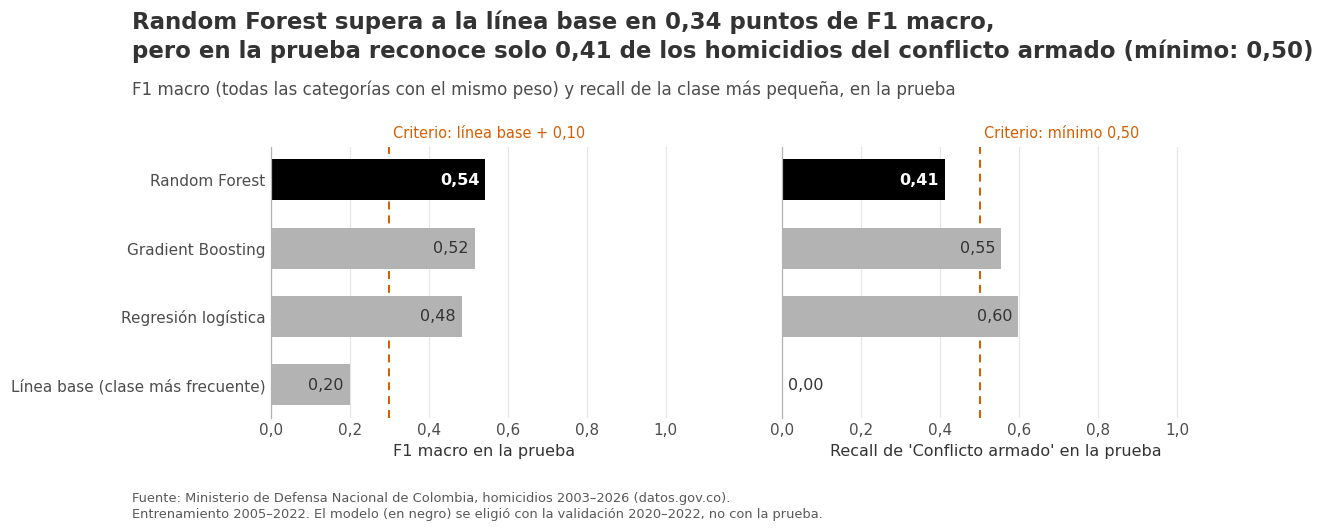

In [36]:
# Visualización 9: comparación de modelos en la prueba frente a los dos criterios de éxito
orden_modelos = sorted(resultados_prueba, key=lambda n: resultados_prueba[n]["f1_macro"])
paneles = [("f1_macro", "F1 macro", base["f1_macro"] + MEJORA_MINIMA_F1, "línea base + 0,10"),
           ("recall · Conflicto armado", "Recall de 'Conflicto armado'", RECALL_MINIMO_CONFLICTO, "mínimo 0,50")]

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for ax, (metrica, etiqueta, umbral, texto_umbral) in zip(ejes, paneles):
    valores = [resultados_prueba[n][metrica] for n in orden_modelos]
    ax.barh(orden_modelos, valores, height=0.6, zorder=2,
            color=[eg.COLOR_MODELO if n == NOMBRE_MEJOR else eg.GRIS_CONTEXTO for n in orden_modelos])
    for fila, valor in enumerate(valores):
        elegido = orden_modelos[fila] == NOMBRE_MEJOR
        if valor >= 0.12:   # etiqueta dentro de la barra: no choca con la línea del criterio
            ax.text(valor - 0.015, fila, f"{valor:.2f}".replace(".", ","), va="center", ha="right", fontsize=10.5,
                    color="white" if elegido else eg.GRIS_OSCURO, fontweight="bold" if elegido else "normal")
        else:
            ax.text(valor + 0.015, fila, f"{valor:.2f}".replace(".", ","), va="center", fontsize=10.5, color=eg.GRIS_OSCURO)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(eg.formato_decimal(1)))
    # La línea del criterio va detrás de las barras para no cruzar las etiquetas
    ax.axvline(umbral, color=eg.CATEGORIAS_VIOLENCIA["Conflicto armado"], linewidth=1.3, linestyle=(0, (4, 3)), zorder=1)
    ax.text(umbral + 0.01, len(orden_modelos) - 0.42, f"Criterio: {texto_umbral}", fontsize=9.5,
            color=eg.CATEGORIAS_VIOLENCIA["Conflicto armado"], va="bottom")
    ax.set_xlim(0, 1.08)
    ax.set_xlabel(etiqueta + " en la prueba")
    eg.grilla(ax, "x")
    ax.tick_params(axis="y", length=0)

cumple_prueba = cumple_criterios(mejor, base)
if cumple_prueba:
    segunda_linea = f"y cumple los dos criterios de éxito con homicidios que nunca vio ({FIN_ENTRENAMIENTO + 1}–{int(anio_modelo.max())})"
else:
    segunda_linea = (f"pero en la prueba reconoce solo {recall_conflicto:.2f} de los homicidios del conflicto armado "
                     f"(mínimo: {RECALL_MINIMO_CONFLICTO:.2f})")
titulo = f"{NOMBRE_MEJOR} supera a la línea base en {mejora_f1:.2f} puntos de F1 macro,\n{segunda_linea}".replace("0.", "0,")
eg.encabezado(fig, titulo, "F1 macro (todas las categorías con el mismo peso) y recall de la clase más pequeña, en la prueba",
              espacio_extra=0.1)
eg.pie_de_fuente(fig, f"{FUENTE_HOM}\nEntrenamiento {ANIO_INICIO_MODELO}–{FIN_ENTRENAMIENTO}. El modelo (en negro) se eligió "
                      f"con la validación {INICIO_VALIDACION}–{FIN_ENTRENAMIENTO}, no con la prueba.", espacio_ejes=0.6)
publicar(fig, "09_modelo_comparacion", titulo, "Barras horizontales (dos paneles)", "Machine Learning", "Acento negro + grises",
         "Dos paneles de barras horizontales con la F1 macro y el recall de conflicto armado de la línea base y tres modelos; "
         "el modelo elegido en negro y líneas con los criterios de éxito.")

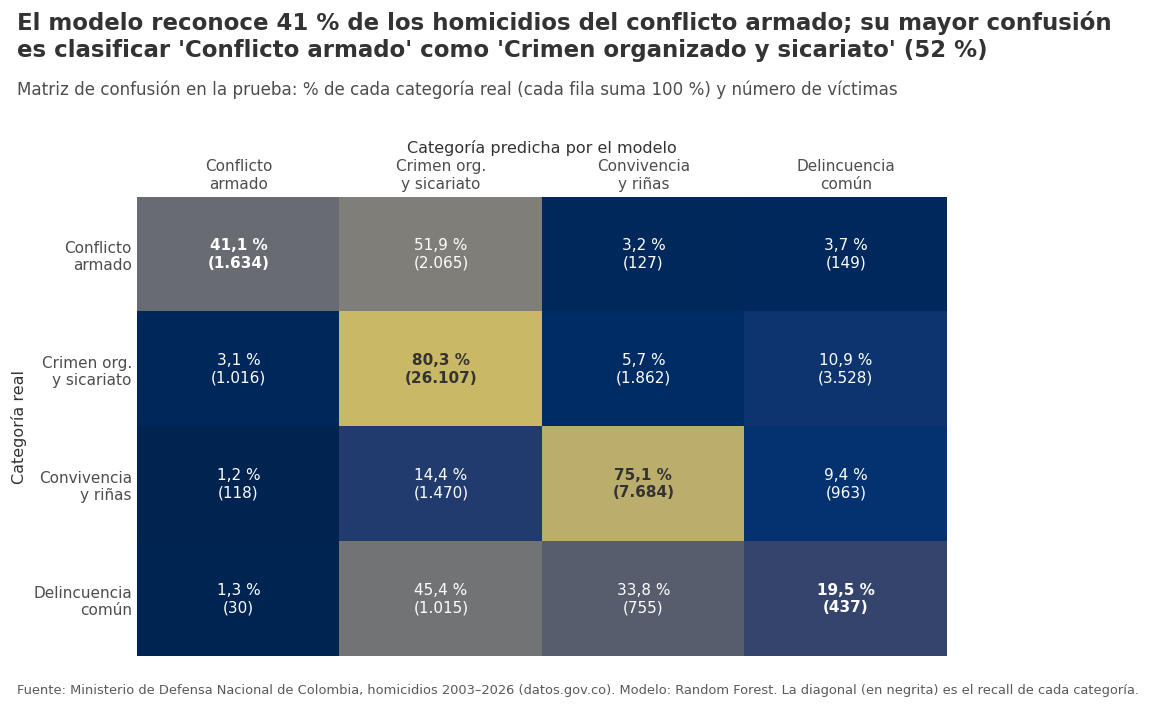

In [37]:
# Visualización 10: matriz de confusión normalizada por fila (recall de cada clase)
matriz = confusion_matrix(y_test, predicciones_prueba[NOMBRE_MEJOR], labels=mdl.CLASES)
matriz_pct = matriz / matriz.sum(axis=1, keepdims=True) * 100
fuera_diagonal = matriz_pct.copy()
np.fill_diagonal(fuera_diagonal, 0)
real_conf, pred_conf = np.unravel_index(fuera_diagonal.argmax(), fuera_diagonal.shape)

fig, ax = plt.subplots(figsize=(9.5, 6.4))
ax.imshow(matriz_pct, cmap=eg.MAPA_SECUENCIAL, vmin=0, vmax=100, aspect="auto")
for i in range(len(mdl.CLASES)):
    for j in range(len(mdl.CLASES)):
        valor = matriz_pct[i, j]
        ax.text(j, i, f"{eg.porcentaje(valor)}\n({eg.formato_miles(matriz[i, j])})", ha="center", va="center", fontsize=10,
                color="white" if valor < 55 else eg.GRIS_OSCURO, fontweight="bold" if i == j else "normal")
etiquetas_cortas = ["Conflicto\narmado", "Crimen org.\ny sicariato", "Convivencia\ny riñas", "Delincuencia\ncomún"]
ax.set_xticks(range(4), etiquetas_cortas)
ax.set_yticks(range(4), etiquetas_cortas)
ax.set_xlabel("Categoría predicha por el modelo")
ax.set_ylabel("Categoría real")
ax.xaxis.set_label_position("top"); ax.xaxis.tick_top()
ax.tick_params(length=0)
for borde in ax.spines.values():
    borde.set_visible(False)

titulo = (f"El modelo reconoce {eg.porcentaje(matriz_pct[0, 0], 0)} de los homicidios del conflicto armado; su mayor confusión\n"
          f"es clasificar '{mdl.CLASES[real_conf]}' como '{mdl.CLASES[pred_conf]}' ({eg.porcentaje(fuera_diagonal.max(), 0)})")
eg.encabezado(fig, titulo, "Matriz de confusión en la prueba: % de cada categoría real (cada fila suma 100 %) y número de víctimas",
              espacio_extra=0.55)
eg.pie_de_fuente(fig, f"{FUENTE_HOM} Modelo: {NOMBRE_MEJOR}. La diagonal (en negrita) es el recall de cada categoría.",
                 espacio_ejes=0.2)
publicar(fig, "10_modelo_matriz_confusion", titulo, "Mapa de calor (matriz de confusión)", "Machine Learning", "Secuencial (cividis)",
         "Matriz de confusión de 4 por 4 con el porcentaje de cada categoría real que el modelo asigna a cada categoría predicha.")

### 8.6 Interpretación: qué variables usa el modelo
Se usa la **importancia por permutación** sobre la prueba: se desordena una variable a la vez y se mide cuánto cae la F1 macro. Si al desordenarla el modelo empeora mucho, esa variable es importante. Tiene dos ventajas: se calcula sobre las variables originales (no sobre las columnas codificadas) y sirve igual para cualquier modelo.

,variable,caida_f1_macro,desviacion,nombre
0,arma_grupo,0.1744,0.0030,Arma usada
1,cod_muni,0.0997,0.0018,Municipio
2,zona,0.0152,0.0007,Zona (urbana / rural)
3,muertes_ucdp_12m,0.0048,0.0013,Muertes de conflicto (UCDP) en 12 meses previos
4,eventos_ucdp_12m,0.0042,0.0013,Eventos de conflicto (UCDP) en 12 meses previos
5,dia_semana,0.0031,0.0005,Día de la semana
6,fin_de_semana,0.0016,0.0008,Fin de semana
7,mes,0.0010,0.0004,Mes
8,sexo,0.0000,0.0006,Sexo de la víctima
9,cantidad,0.0000,0.0000,Víctimas en el mismo hecho


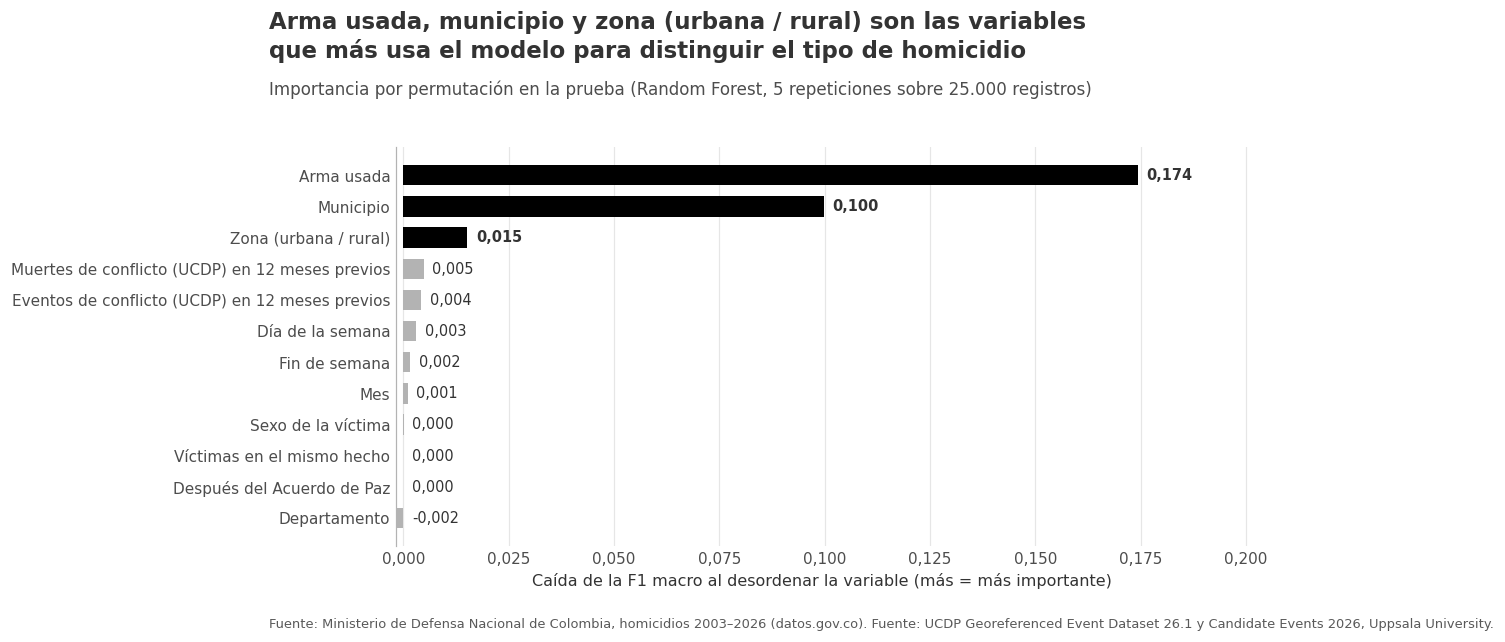

In [38]:
modelo_elegido = modelos_finales[NOMBRE_MEJOR]
muestra_importancia = X_test.sample(n=min(25_000, len(X_test)), random_state=SEMILLA)
importancia = permutation_importance(modelo_elegido, muestra_importancia, y_test.loc[muestra_importancia.index],
                                     scoring="f1_macro", n_repeats=5, random_state=SEMILLA, n_jobs=1)
importancia_variables = (pd.DataFrame({"variable": muestra_importancia.columns,
                                       "caida_f1_macro": importancia.importances_mean,
                                       "desviacion": importancia.importances_std})
                         .assign(nombre=lambda t: t["variable"].map(mdl.NOMBRES_VARIABLES))
                         .sort_values("caida_f1_macro", ascending=False)
                         .reset_index(drop=True))
display(importancia_variables.round(4))

# Visualización 11: importancia de las variables
datos_grafico = importancia_variables.sort_values("caida_f1_macro")
top3 = set(importancia_variables["variable"].head(3))
fig, ax = plt.subplots(figsize=(10, 5.8))
ax.barh(datos_grafico["nombre"], datos_grafico["caida_f1_macro"],
        color=[eg.COLOR_MODELO if v in top3 else eg.GRIS_CONTEXTO for v in datos_grafico["variable"]], height=0.65)
for fila, (valor, variable) in enumerate(zip(datos_grafico["caida_f1_macro"], datos_grafico["variable"])):
    ax.text(max(valor, 0) + 0.002, fila, f"{valor:.3f}".replace(".", ","), va="center", fontsize=9.5,
            color=eg.GRIS_OSCURO, fontweight="bold" if variable in top3 else "normal")
ax.set_xlim(min(0, datos_grafico["caida_f1_macro"].min()), datos_grafico["caida_f1_macro"].max() * 1.15)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(eg.formato_decimal(3)))
ax.set_xlabel("Caída de la F1 macro al desordenar la variable (más = más importante)")
eg.grilla(ax, "x")
ax.tick_params(axis="y", length=0)

nombres_top = importancia_variables["nombre"].head(3).tolist()
titulo = (f"{nombres_top[0]}, {nombres_top[1].lower()} y {nombres_top[2].lower()} son las variables\n"
          f"que más usa el modelo para distinguir el tipo de homicidio")
eg.encabezado(fig, titulo, f"Importancia por permutación en la prueba ({NOMBRE_MEJOR}, 5 repeticiones sobre 25.000 registros)",
              espacio_extra=0.1)
eg.pie_de_fuente(fig, f"{FUENTE_HOM} {FUENTE_UCDP}", espacio_ejes=0.6)
publicar(fig, "11_modelo_importancia_variables", titulo, "Barras horizontales", "Machine Learning", "Acento negro + grises",
         "Barras horizontales con la importancia por permutación de cada variable del modelo; las tres más importantes en negro.")

In [39]:
# Perfil de cada categoría predicha en la prueba (lenguaje de negocio)
perfil = (X_test.assign(prediccion=predicciones_prueba[NOMBRE_MEJOR])
          .groupby("prediccion")
          .agg(registros=("zona", "size"),
               pct_rural=("zona", lambda s: (s == "RURAL").mean() * 100),
               pct_arma_fuego=("arma_grupo", lambda s: (s == "Arma de fuego").mean() * 100),
               pct_arma_blanca=("arma_grupo", lambda s: (s == "Arma blanca").mean() * 100),
               pct_fin_de_semana=("fin_de_semana", lambda s: s.mean() * 100),
               mediana_eventos_ucdp_12m=("eventos_ucdp_12m", "median"))
          .reindex(mdl.CLASES).round(1))
perfil

,registros,pct_rural,pct_arma_fuego,pct_arma_blanca,pct_fin_de_semana,mediana_eventos_ucdp_12m
prediccion,,,,,,
Conflicto armado,2798,89.1,84.3,0.1,30.7,36.0
Crimen organizado y sicariato,30657,35.2,99.1,0.0,33.0,18.0
Convivencia y riñas,10428,21.2,19.3,74.1,47.8,6.0
Delincuencia común,5077,20.1,87.7,3.0,32.4,5.0


**Interpretación en lenguaje de negocio.**
- **El arma es la señal más fuerte.** Separa de inmediato las riñas (donde abundan el arma blanca y los objetos contundentes) del sicariato y del conflicto armado, que se cometen casi siempre con arma de fuego. El conflicto armado tiene además una firma propia: los explosivos.
- **El municipio es la segunda.** Cada municipio tiene una dinámica de violencia propia y persistente: hay municipios donde casi todo es sicariato y otros donde domina el conflicto. El modelo la aprende a partir del historial de cada municipio en el entrenamiento (*target encoding*).
- **La zona rural es la marca del conflicto.** Casi todos los homicidios que el modelo clasifica como conflicto armado son rurales (ver la tabla de perfiles), mientras que el crimen organizado, las riñas y la delincuencia común son mayoritariamente urbanos.
- **La actividad armada según UCDP aporta, pero menos de lo esperado** cuando el modelo ya conoce el municipio y la zona, porque en buena parte repite esa información territorial. Aun así, en la tabla de perfiles los homicidios clasificados como conflicto ocurren en lugares con el doble de eventos UCDP que el resto.
- **El día de la semana ayuda a reconocer las riñas** (casi la mitad de las predichas ocurren en fin de semana), como anticipó la visualización 6.
- **Variables sin aporte:** el sexo de la víctima y el número de víctimas casi no cambian la predicción. *Después del Acuerdo de Paz* tiene importancia cero por construcción, porque en la prueba todos los registros son posteriores al acuerdo. El departamento queda en cero o ligeramente negativo porque el municipio ya contiene esa información.

### 8.7 Guardar el modelo para el dashboard
Se guarda el `Pipeline` completo (preparación + modelo), de modo que el dashboard lo carga y predice sin reentrenar y sin repetir el ETL. Junto al modelo se guarda un archivo de metadatos con las métricas, la línea base, las variables y las opciones que necesita el formulario de predicción (departamentos y sus municipios).

Después se prueba como lo usará el dashboard: se carga el archivo, se arma el registro con `registro_nuevo()` y se piden las probabilidades de dos casos opuestos. Un homicidio rural con arma de fuego en Arauca, con alta actividad armada reciente, debe clasificarse como conflicto armado; uno urbano con arma blanca un domingo en Valle del Cauca, como convivencia y riñas. El dashboard mostrará las probabilidades de todas las categorías, no solo la ganadora, para que se vea la incertidumbre de cada predicción.

In [40]:
CARPETA_MODELOS = RAIZ / "models"
CARPETA_MODELOS.mkdir(exist_ok=True)
ruta_modelo = CARPETA_MODELOS / "modelo_categoria_violencia.joblib"
joblib.dump(modelo_elegido, ruta_modelo, compress=3)

municipios = (datos_modelo.drop_duplicates("cod_muni")[["departamento", "cod_muni", "municipio"]]
              .astype({"departamento": str, "municipio": str}).sort_values(["departamento", "municipio"]))
metadatos_modelo = {
    "tarea": "Clasificación multiclase",
    "algoritmo": NOMBRE_MEJOR,
    "objetivo": mdl.OBJETIVO,
    "clases": mdl.CLASES,
    "variables": mdl.VARIABLES_MODELO,
    "nombres_variables": mdl.NOMBRES_VARIABLES,
    "periodo_entrenamiento": f"{ANIO_INICIO_MODELO}–{FIN_ENTRENAMIENTO}",
    "periodo_validacion": f"{INICIO_VALIDACION}–{FIN_ENTRENAMIENTO}",
    "periodo_prueba": f"{FIN_ENTRENAMIENTO + 1}–{int(anio_modelo.max())}",
    "filas_entrenamiento": int(len(X_train)), "filas_prueba": int(len(X_test)),
    "metricas_prueba": {k: round(float(v), 4) for k, v in mejor.items()},
    "linea_base": {"estrategia": "clase más frecuente", **{k: round(float(v), 4) for k, v in base.items()}},
    "comparacion_modelos": {n: {k: round(float(v), 4) for k, v in r.items()} for n, r in resultados_prueba.items()},
    "criterio_exito": {"mejora_f1_macro": round(float(mejora_f1), 4), "recall_conflicto_armado": round(float(recall_conflicto), 4),
                       "cumple": bool(criterios["cumple"].all())},
    "variables_importantes": importancia_variables[["variable", "nombre", "caida_f1_macro"]].round(4).to_dict("records"),
    "matriz_confusion": {"clases": mdl.CLASES, "valores": matriz.tolist()},
    "opciones_formulario": {
        "departamentos": {d: g[["cod_muni", "municipio"]].to_dict("records") for d, g in municipios.groupby("departamento")},
        "zonas": sorted(X_train["zona"].unique().tolist()),
        "sexos": sorted(X_train["sexo"].unique().tolist()),
        "armas": sorted(X_train["arma_grupo"].unique().tolist()),
    },
    "fecha_entrenamiento": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "versiones": {"scikit-learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
ruta_metadatos = CARPETA_MODELOS / "metadatos_modelo.json"
ruta_metadatos.write_text(json.dumps(metadatos_modelo, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Modelo: {ruta_modelo.relative_to(RAIZ)} ({ruta_modelo.stat().st_size / 1e6:.1f} MB)")
print(f"Metadatos: {ruta_metadatos.relative_to(RAIZ)}")

Modelo: models/modelo_categoria_violencia.joblib (76.4 MB)
Metadatos: models/metadatos_modelo.json


In [41]:
# Prueba de uso: cargar el modelo y predecir casos nuevos
modelo_cargado = joblib.load(ruta_modelo)

def municipio_principal(departamento):
    # Municipio con más homicidios del departamento (para armar ejemplos realistas)
    tabla = datos_modelo[datos_modelo["departamento"] == departamento]
    return int(tabla["cod_muni"].value_counts().idxmax())

contexto_ucdp = panel_ucdp.set_index(["depto_clave", "periodo"])
def ucdp_reciente(depto_clave):
    fila = contexto_ucdp.loc[(depto_clave, panel_ucdp["periodo"].max())]
    return float(fila["eventos_ucdp_12m"]), float(fila["muertes_ucdp_12m"])

eventos_arauca, muertes_arauca = ucdp_reciente("ARAUCA")
casos = pd.concat([
    mdl.registro_nuevo("ARAUCA", municipio_principal("ARAUCA"), "RURAL", "MASCULINO", "Arma de fuego",
                       "2026-03-10", eventos_arauca, muertes_arauca, cantidad=2),
    mdl.registro_nuevo("VALLE DEL CAUCA", municipio_principal("VALLE DEL CAUCA"), "URBANA", "MASCULINO", "Arma blanca",
                       "2026-03-15", *ucdp_reciente("VALLE DEL CAUCA"), cantidad=1),
], ignore_index=True)
probabilidades = pd.DataFrame(modelo_cargado.predict_proba(casos), columns=modelo_cargado.classes_).reindex(columns=mdl.CLASES)
probabilidades.index = ["Arauca, rural, arma de fuego, martes, 2 víctimas", "Valle del Cauca, urbano, arma blanca, domingo"]
(probabilidades * 100).round(1)

,Conflicto armado,Crimen organizado y sicariato,Convivencia y riñas,Delincuencia común
"Arauca, rural, arma de fuego, martes, 2 víctimas",91.4,7.4,0.5,0.7
"Valle del Cauca, urbano, arma blanca, domingo",0.6,1.2,73.3,24.9


## 9. Insights en MongoDB
El análisis completo se guarda en MongoDB como **un solo documento**, con la estructura de la Actividad 1 ampliada con los resultados del modelo. Así el dashboard y el reporte PDF leen los resultados del mismo lugar, sin repetir el análisis:

| Campo | Contenido |
|---|---|
| `metadata` | Fecha, autor, pregunta de negocio y las tres fuentes (URL, periodo, filas, columnas, peso) |
| `calidad_datos` | Tabla de problemas de calidad, registros eliminados y conteos antes/después del ETL |
| `estadisticas_descriptivas` | Cifras generales de homicidios y de UCDP |
| `agregaciones` | Tablas OLAP listas para mostrar (año × categoría, departamento × categoría, región × quinquenio…) |
| `modelo` | Tarea, algoritmo, métricas, línea base, comparación de modelos, criterios de éxito, variables importantes y matriz de confusión |
| `insights` | Hallazgos con tema, detalle y la gráfica que los respalda |
| `visualizaciones_generadas` | Las figuras con su tipo, paleta y texto alternativo |
| `recomendaciones` | Recomendaciones con prioridad y el insight que las sustenta |

Las cifras de los insights se calculan con los datos (no se escriben a mano), así que siguen siendo correctas si se vuelven a descargar las fuentes.

In [42]:
from pymongo import DESCENDING, MongoClient

def a_nativo(objeto):
    # Convierte tipos de NumPy/pandas a tipos de Python que MongoDB (BSON) acepta
    def convertir(valor):
        if isinstance(valor, (np.integer,)):
            return int(valor)
        if isinstance(valor, (np.floating,)):
            return None if np.isnan(valor) else float(valor)
        if isinstance(valor, np.bool_):
            return bool(valor)
        if isinstance(valor, (pd.Timestamp, datetime)):
            return valor.isoformat()
        if isinstance(valor, (pd.Period, Path)):
            return str(valor)
        raise TypeError(f"Tipo no convertible: {type(valor)}")
    return json.loads(json.dumps(objeto, default=convertir, ensure_ascii=False))

def a_agregacion(tabla, nombre, descripcion, dimensiones, medida, formato="entero"):
    # Convierte una tabla (pivot) en un bloque autodescriptivo para MongoDB, el PDF y el dashboard
    tabla = tabla.reset_index()
    tabla.columns = [str(c) for c in tabla.columns]
    if formato == "porcentaje":
        tabla = tabla.round(1)
    return {"nombre": nombre, "descripcion": descripcion, "dimensiones": dimensiones, "medida": medida,
            "formato": formato, "columnas": list(tabla.columns),
            "filas": tabla.astype(object).where(tabla.notna(), None).values.tolist()}

# ---------------- agregaciones OLAP que se guardan
pivot_anio_categoria = olap.pivotear(olap.filtrar(cubo_homicidios, anio=(2008, ultimo_anio)), "anio", "categoria_violencia", "victimas")
pivot_anio_categoria.index = pivot_anio_categoria.index.map(lambda a: f"{a}*" if isinstance(a, (int, np.integer)) and a > ANIO_COMPLETO_HOM else str(a))
pivot_anio_categoria.index.name = "Año"

pivot_depto = olap.pivotear(olap.filtrar(cubo_homicidios, anio=(2017, ANIO_COMPLETO_HOM)), "departamento", "categoria_violencia",
                            "victimas", totales=False)
pivot_depto["Total"] = pivot_depto.sum(axis=1)
pivot_depto = pivot_depto.sort_values("Total", ascending=False).head(12)
pivot_depto.index.name = "Departamento"

pivot_region = regional.copy()
pivot_region.columns = etiquetas_periodo
pivot_region.index = [REGIONES_ES.get(r, r) for r in pivot_region.index]
pivot_region.index.name = "Región"

pivot_armas = pct_armas.copy()
pivot_armas.index.name = "Categoría"

PAISES_ES = {"Mexico": "México", "Brazil": "Brasil", "Haiti": "Haití", "Peru": "Perú", "Panama": "Panamá",
             "United States of America": "Estados Unidos", "Dominican Republic": "República Dominicana"}
pivot_america = tabla_america.assign(Total=tabla_america.sum(axis=1)).sort_values("Total", ascending=False).head(10)
pivot_america.index = [PAISES_ES.get(p, p) for p in pivot_america.index]
pivot_america.index.name = "País"

def nombre_propio(texto):
    # 'NORTE DE SANTANDER' -> 'Norte de Santander'
    return " ".join(p.lower() if p.lower() in {"de", "del", "la", "y"} else p.capitalize() for p in str(texto).split())

agregaciones = [
    a_agregacion(pivot_anio_categoria, "Víctimas de homicidio por año y categoría de violencia",
                 f"Colombia, 2008–{ultimo_anio} (* año parcial).", ["año", "categoría de violencia"], "víctimas"),
    a_agregacion(pivot_depto, f"Víctimas por departamento y categoría, 2017–{ANIO_COMPLETO_HOM}",
                 "Los 12 departamentos con más víctimas.", ["departamento", "categoría de violencia"], "víctimas"),
    a_agregacion(pivot_armas, "Arma usada según la categoría de violencia",
                 "Porcentaje de las víctimas de cada categoría, 2003–2026.", ["categoría de violencia", "arma"],
                 "% de víctimas", formato="porcentaje"),
    a_agregacion(pivot_region, "Eventos de violencia organizada por región y quinquenio",
                 "UCDP, mundo (* periodo incompleto).", ["región", "quinquenio"], "eventos"),
    a_agregacion(pivot_america, f"Eventos en América por país y tipo de violencia, {ANIO_COMPLETO_UCDP - 4}–{ANIO_COMPLETO_UCDP}",
                 "UCDP, los 10 países con más eventos.", ["país", "tipo de violencia"], "eventos"),
]
print("Agregaciones preparadas:", [a["nombre"] for a in agregaciones])

Agregaciones preparadas: ['Víctimas de homicidio por año y categoría de violencia', 'Víctimas por departamento y categoría, 2017–2025', 'Arma usada según la categoría de violencia', 'Eventos de violencia organizada por región y quinquenio', 'Eventos en América por país y tipo de violencia, 2021–2025']


In [43]:
# ---------------- insights (cifras calculadas con los datos)
crimen_inicio, crimen_fin = pct_anual.loc[2008, "Crimen organizado y sicariato"], pct_anual.loc[ANIO_COMPLETO_HOM, "Crimen organizado y sicariato"]
rinas_inicio, rinas_fin = pct_anual.loc[2008, "Convivencia y riñas"], pct_anual.loc[ANIO_COMPLETO_HOM, "Convivencia y riñas"]
no_estatal_2015, no_estatal_fin = anual_tipo.loc[2015, "Conflicto no estatal"], anual_tipo.loc[ANIO_COMPLETO_UCDP, "Conflicto no estatal"]
america_reciente = pivot_region.loc["América"]
paises_no_estatal = tabla_america["Conflicto no estatal"].sort_values(ascending=False).head(2)
conflicto_parcial = (hom[(hom["anio"] == ultimo_anio) & (hom["categoria_violencia"] == "Conflicto armado")]
                     .groupby("departamento", observed=True)["cantidad"].sum().sort_values(ascending=False))
explosivos_conflicto = explosivos["Conflicto armado"]
arauca = por_depto.loc["ARAUCA"]
fmt = eg.formato_miles

insights = [
    {"id": 1, "tema": "Violencia global", "visualizacion": "reports/figuras/01_ucdp_evolucion_tipo.png",
     "titulo": f"La violencia organizada en el mundo llegó a su máximo en {anio_pico}",
     "detalle": f"UCDP registró {fmt(total_pico)} eventos de violencia organizada en {anio_pico}, el valor más alto desde 1989. "
                f"El conflicto estatal es el tipo más frecuente, y el conflicto no estatal (enfrentamientos entre grupos armados, "
                f"incluidos carteles) pasó de {fmt(no_estatal_2015)} eventos en 2015 a {fmt(no_estatal_fin)} en {ANIO_COMPLETO_UCDP}.",
     "valor_clave": total_pico},
    {"id": 2, "tema": "Violencia global", "visualizacion": "reports/figuras/02_ucdp_region_quinquenio.png",
     "titulo": f"{nombre_region} concentró el quinquenio más violento; América vive su periodo más violento en los años recientes",
     "detalle": f"{nombre_region} acumuló {fmt(maximo)} eventos en {etiquetas_periodo[periodo_max]}. En América el máximo está en "
                f"{america_reciente.idxmax()} ({fmt(america_reciente.max())} eventos), impulsado por la violencia entre grupos "
                f"criminales: {PAISES_ES.get(paises_no_estatal.index[0], paises_no_estatal.index[0])} y "
                f"{PAISES_ES.get(paises_no_estatal.index[1], paises_no_estatal.index[1])} concentran la mayoría de los eventos "
                f"de conflicto no estatal de la región entre {ANIO_COMPLETO_UCDP - 4} y {ANIO_COMPLETO_UCDP}.",
     "valor_clave": maximo},
    {"id": 3, "tema": "Armas", "visualizacion": "reports/figuras/03_arma_por_categoria.png",
     "titulo": "El sicariato es casi siempre con arma de fuego; las riñas, no",
     "detalle": f"El {eg.porcentaje(fuego['Crimen organizado y sicariato'])} de las víctimas de crimen organizado y sicariato murió por "
                f"arma de fuego, frente al {eg.porcentaje(fuego['Convivencia y riñas'])} en las riñas, donde el arma blanca pesa mucho. "
                f"En el conflicto armado el {eg.porcentaje(explosivos_conflicto)} de las víctimas murió por explosivos.",
     "valor_clave": fuego["Crimen organizado y sicariato"]},
    {"id": 4, "tema": "Tendencia en Colombia", "visualizacion": "reports/figuras/04_composicion_anual.png",
     "titulo": "El crimen organizado y el sicariato ya son la mayoría de los homicidios",
     "detalle": f"Su participación pasó de {eg.porcentaje(crimen_inicio, 0)} en 2008 a {eg.porcentaje(crimen_fin, 0)} en "
                f"{ANIO_COMPLETO_HOM}, mientras las riñas bajaron de {eg.porcentaje(rinas_inicio, 0)} a {eg.porcentaje(rinas_fin, 0)}.",
     "valor_clave": crimen_fin},
    {"id": 5, "tema": "Acuerdo de Paz", "visualizacion": "reports/figuras/05_antes_despues_acuerdo.png",
     "titulo": "Después del Acuerdo de Paz la violencia homicida cambió de forma más que de nivel",
     "detalle": f"Comparando el promedio anual de 2008–2016 con el de 2017–{ANIO_COMPLETO_HOM}, los homicidios por crimen organizado y "
                f"sicariato cambiaron {cambio_pct['Crimen organizado y sicariato']:+.0f} %, los de riñas "
                f"{cambio_pct['Convivencia y riñas']:+.0f} %, los del conflicto armado {cambio_pct['Conflicto armado']:+.0f} % y los "
                f"de delincuencia común {cambio_pct['Delincuencia común']:+.0f} %.",
     "valor_clave": cambio_pct["Crimen organizado y sicariato"]},
    {"id": 6, "tema": "Temporalidad", "visualizacion": "reports/figuras/06_dia_semana_categoria.png",
     "titulo": "Las riñas se concentran en domingo",
     "detalle": f"El {eg.porcentaje(domingo)} de las víctimas de riñas murió un domingo, {domingo / entre_semana:.1f} veces más que un "
                f"día entre semana. El conflicto armado, en cambio, se reparte casi por igual en los siete días.".replace(".", ",", 1),
     "valor_clave": domingo},
    {"id": 7, "tema": "Conflicto y territorio", "visualizacion": "reports/figuras/07_departamentos_ucdp_conflicto.png",
     "titulo": "Donde UCDP registra más actividad armada, más homicidios se atribuyen al conflicto",
     "detalle": f"La correlación de Spearman entre los eventos UCDP de cada departamento y su porcentaje de homicidios por conflicto "
                f"armado es {rho_conflicto:.2f} (2017–{ANIO_COMPLETO_HOM}). Arauca es el caso extremo: el "
                f"{eg.porcentaje(arauca['pct_conflicto'])} de sus homicidios se atribuye al conflicto.".replace("0.", "0,", 1),
     "valor_clave": rho_conflicto},
    {"id": 8, "tema": "Conflicto y territorio", "visualizacion": "reports/figuras/04_composicion_anual.png",
     "titulo": f"El conflicto armado repunta en {ultimo_anio}",
     "detalle": f"En el parcial de {ultimo_anio} (enero–septiembre) el conflicto armado explica el "
                f"{eg.porcentaje(pct_anual.loc[ultimo_anio, 'Conflicto armado'])} de los homicidios, frente a "
                f"{eg.porcentaje(pct_anual.loc[2016, 'Conflicto armado'])} en 2016. Los departamentos con más víctimas por conflicto en "
                f"{ultimo_anio} son {', '.join(nombre_propio(d) for d in conflicto_parcial.index[:3])}.",
     "valor_clave": pct_anual.loc[ultimo_anio, "Conflicto armado"]},
    {"id": 9, "tema": "Modelo", "visualizacion": "reports/figuras/09_modelo_comparacion.png",
     "titulo": "El modelo clasifica bien la mayoría de los homicidios, pero subestima el conflicto cuando crece",
     "detalle": f"{NOMBRE_MEJOR} logra una F1 macro de {mejor['f1_macro']:.2f} en 2023–{int(anio_modelo.max())}, "
                f"{mejora_f1:.2f} puntos por encima de la línea base. Su recall en conflicto armado es {recall_conflicto:.2f}: la "
                f"proporción de conflicto en la prueba casi duplica la del entrenamiento. Las variables más importantes son "
                f"{', '.join(importancia_variables['nombre'].head(3).str.lower())}.".replace("0.", "0,"),
     "valor_clave": mejor["f1_macro"]},
]

recomendaciones = [
    {"id": 1, "prioridad": "Alta", "tema": "Armas",
     "titulo": "Concentrar el control de armas de fuego en las estructuras de sicariato y crimen organizado",
     "detalle": "Las incautaciones y el rastreo de armas de fuego deberían priorizar los municipios donde el sicariato es la "
                "modalidad dominante, porque allí el arma de fuego está en casi todas las muertes.",
     "sustento": "Insights 3 y 4"},
    {"id": 2, "prioridad": "Media", "tema": "Temporalidad",
     "titulo": "Programas de convivencia y control de alcohol enfocados en fines de semana y domingos",
     "detalle": "Las riñas tienen un patrón semanal muy marcado; concentrar presencia institucional, horarios de venta de alcohol "
                "y mediación comunitaria en esos días ataca el momento de mayor riesgo.",
     "sustento": "Insight 6"},
    {"id": 3, "prioridad": "Alta", "tema": "Conflicto y territorio",
     "titulo": "Alerta temprana territorial con datos de conflicto actualizados mes a mes",
     "detalle": "Cruzar cada mes la actividad armada de UCDP con los homicidios por departamento permite detectar repuntes del "
                "conflicto (como el de 2025–2026) antes de que se reflejen en las cifras anuales.",
     "sustento": "Insights 7 y 8"},
    {"id": 4, "prioridad": "Media", "tema": "Modelo",
     "titulo": "Usar el modelo como apoyo para los casos sin modalidad, reentrenándolo con datos recientes",
     "detalle": "El modelo puede sugerir la categoría de los homicidios que llegan sin modalidad (cerca del 10 %), siempre con "
                "revisión humana. Debe reentrenarse al menos cada año y vigilar el recall de 'Conflicto armado', que cae "
                "cuando el conflicto repunta.",
     "sustento": "Insight 9"},
]
pd.DataFrame(insights)[["id", "tema", "titulo"]]

,id,tema,titulo
0,1,Violencia global,La violencia organizada en el mundo llegó a su...
1,2,Violencia global,Medio Oriente concentró el quinquenio más viol...
2,3,Armas,El sicariato es casi siempre con arma de fuego...
3,4,Tendencia en Colombia,El crimen organizado y el sicariato ya son la ...
4,5,Acuerdo de Paz,Después del Acuerdo de Paz la violencia homici...
5,6,Temporalidad,Las riñas se concentran en domingo
6,7,Conflicto y territorio,"Donde UCDP registra más actividad armada, más ..."
7,8,Conflicto y territorio,El conflicto armado repunta en 2026
8,9,Modelo,El modelo clasifica bien la mayoría de los hom...


In [44]:
# ---------------- documento completo
PERIODOS_FUENTE = {
    "ucdp_ged": f"1989–{ANIO_COMPLETO_UCDP}",
    "ucdp_candidate": f"{ANIO_COMPLETO_UCDP + 1} (hasta {ucdp['date_start'].max():%m/%Y})",
    "homicidios_col": f"2003–{hom['fecha_hecho'].max():%m/%Y}",
}
fuentes = []
for _, fila in resumen_datasets.iterrows():
    fuentes.append({"clave": fila["dataset"], "nombre": fila["fuente"], "url": fila["url"], "periodo": PERIODOS_FUENTE[fila["dataset"]],
                    "fecha_descarga": fila["fecha_descarga"], "registros": fila["filas"], "columnas": fila["columnas"],
                    "peso_mb": fila["disco_mb"], "memoria_mb": fila["memoria_mb"]})

victimas_categoria = hom.groupby("categoria_violencia", observed=True)["cantidad"].sum().sort_values(ascending=False)
documento_analisis = a_nativo({
    "metadata": {
        "proyecto": "violencia-armada",
        "titulo": "Violencia armada: conflicto global y homicidios en Colombia",
        "subtitulo": "Pipeline de Big Data con Machine Learning, almacenamiento híbrido y dashboard contenerizado",
        "curso": "Gerencia y almacenamiento en Big Data — Proyecto final",
        "autores": ["Diego Almanza"],
        "fecha_analisis": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "pregunta_negocio": "¿Qué distingue a los homicidios asociados al conflicto armado de los asociados a la criminalidad "
                            "urbana en Colombia, y se puede anticipar el tipo de homicidio a partir de dónde, cuándo y con qué "
                            "arma ocurre?",
        "dataset": {
            "fuente": "UCDP GED 26.1 + UCDP Candidate 2026 (Uppsala University); Homicidios — Ministerio de Defensa Nacional (datos.gov.co)",
            "url": [f["url"] for f in fuentes],
            "registros": total_registros,
            "columnas": int(resumen_datasets["columnas"].sum()),
            "descripcion": "Tres fuentes oficiales y públicas que se complementan: los eventos de violencia organizada del mundo "
                           "registrados por UCDP (con su tipo: estatal, no estatal o unilateral) y los homicidios de Colombia "
                           "registrados por el Ministerio de Defensa, con el arma usada y la modalidad presunta.",
            "fuentes": fuentes,
        },
    },
    "calidad_datos": {
        "problemas_detectados": problemas_calidad.to_dict("records"),
        "registros_eliminados": int(resumen_etl.loc[resumen_etl["tecnica"] == "Limpieza", "filas_antes"].sum()
                                    - resumen_etl.loc[resumen_etl["tecnica"] == "Limpieza", "filas_despues"].sum()),
        "valores_corregidos_limpieza": int(resumen_etl.loc[resumen_etl["tecnica"] == "Limpieza", "valores_corregidos"].sum()),
        "resumen_etl": resumen_etl.to_dict("records"),
    },
    "estadisticas_descriptivas": {
        "homicidios": {
            "victimas": hom["cantidad"].sum(), "registros": len(hom),
            "periodo": f"{hom['fecha_hecho'].min():%Y-%m-%d} y {hom['fecha_hecho'].max():%Y-%m-%d}",
            "pct_arma_fuego": np.average(hom["es_arma_fuego"], weights=hom["cantidad"]) * 100,
            "pct_rural": np.average(hom["zona"] == "RURAL", weights=hom["cantidad"]) * 100,
            "victimas_por_categoria": victimas_categoria.to_dict(),
            "victimas_por_anio": hom.groupby("anio")["cantidad"].sum().astype(int).rename(index=str).to_dict(),
            "cantidad_por_registro": hom["cantidad"].describe().round(3).to_dict(),
            "eventos_ucdp_12m": hom["eventos_ucdp_12m"].describe().round(2).to_dict(),
        },
        "ucdp": {
            "eventos": len(ucdp), "paises": int(ucdp["country"].nunique()),
            "periodo": f"{ucdp['date_start'].min():%Y-%m-%d} y {ucdp['date_start'].max():%Y-%m-%d}",
            "muertes_estimadas": ucdp["best"].sum(),
            "eventos_por_tipo": ucdp["tipo_violencia"].value_counts().to_dict(),
            "eventos_por_region": ucdp["region"].map(REGIONES_ES).value_counts().to_dict(),
            "muertes_por_evento": ucdp["best"].describe().round(2).to_dict(),
        },
    },
    "agregaciones": agregaciones,
    "modelo": {
        "tarea": "Clasificación multiclase de la categoría de violencia del homicidio",
        "algoritmo": NOMBRE_MEJOR,
        "descripcion": f"Se compararon una línea base y tres modelos; el elegido cumple los criterios de éxito en la validación "
                       f"{INICIO_VALIDACION}–{FIN_ENTRENAMIENTO} y tiene la mayor F1 macro.",
        "periodo_entrenamiento": metadatos_modelo["periodo_entrenamiento"],
        "periodo_prueba": metadatos_modelo["periodo_prueba"],
        "archivo": str(ruta_modelo.relative_to(RAIZ)).replace("\\", "/"),
        "metricas": metadatos_modelo["metricas_prueba"],
        "linea_base": metadatos_modelo["linea_base"],
        "comparacion_modelos": metadatos_modelo["comparacion_modelos"],
        "metricas_validacion": {n: {k: round(float(v), 4) for k, v in r.items()} for n, r in resultados_validacion.items()},
        "criterios_exito": criterios.to_dict("records"),
        "variables_importantes": metadatos_modelo["variables_importantes"],
        "matriz_confusion": metadatos_modelo["matriz_confusion"],
        "perfil_predicciones": perfil.reset_index().to_dict("records"),
    },
    "insights": insights,
    "visualizaciones_generadas": visualizaciones_generadas,
    "recomendaciones": recomendaciones,
})
print(f"Documento listo: {len(json.dumps(documento_analisis, ensure_ascii=False)) / 1024:.0f} KB, "
      f"{len(documento_analisis['insights'])} insights, {len(documento_analisis['recomendaciones'])} recomendaciones, "
      f"{len(documento_analisis['visualizaciones_generadas'])} visualizaciones")

# ---------------- conexión e inserción
MONGO_URI = os.environ.get("MONGO_URI")
MONGO_BD = os.environ.get("MONGO_BD", "violencia_armada")
if not MONGO_URI:
    raise RuntimeError("Falta MONGO_URI: ejecute el notebook dentro del contenedor (docker compose up).")

cliente_mongo = MongoClient(MONGO_URI, serverSelectionTimeoutMS=8000)
print("MongoDB", cliente_mongo.server_info()["version"], "| base de datos:", MONGO_BD)
coleccion = cliente_mongo[MONGO_BD]["analisis"]
coleccion.create_index([("metadata.fecha_analisis", DESCENDING)])

# Se reemplaza el análisis anterior del proyecto para que volver a ejecutar el notebook no duplique documentos
eliminados = coleccion.delete_many({"metadata.proyecto": "violencia-armada"}).deleted_count
id_documento = coleccion.insert_one(documento_analisis).inserted_id
print(f"Documentos anteriores reemplazados: {eliminados} | nuevo _id: {id_documento}")

Documento listo: 34 KB, 9 insights, 4 recomendaciones, 11 visualizaciones


MongoDB 7.0.45 | base de datos: violencia_armada
Documentos anteriores reemplazados: 1 | nuevo _id: 6af740107456d646dce6cdaf


### 9.1 Consultas a MongoDB
Tres consultas que el dashboard usará de la misma forma: una proyección de campos anidados, un filtro sobre un arreglo (`$unwind` + `$match`) y un filtro con proyección de los resultados.

In [45]:
# Consulta 1: recuperar las métricas del modelo y los criterios de éxito (proyección de campos anidados)
consulta_modelo = coleccion.find_one(
    {"metadata.proyecto": "violencia-armada"},
    {"_id": 0, "modelo.algoritmo": 1, "modelo.metricas.f1_macro": 1, "modelo.linea_base.f1_macro": 1, "modelo.criterios_exito": 1},
)
print("Algoritmo:", consulta_modelo["modelo"]["algoritmo"],
      "| F1 macro:", consulta_modelo["modelo"]["metricas"]["f1_macro"],
      "| línea base:", consulta_modelo["modelo"]["linea_base"]["f1_macro"])
pd.DataFrame(consulta_modelo["modelo"]["criterios_exito"])

Algoritmo: Random Forest | F1 macro: 0.5431 | línea base: 0.1995


,criterio,valor,cumple
0,"F1 macro supera la línea base en ≥ 0,10","+0,344",True
1,"Recall de 'Conflicto armado' ≥ 0,50","0,411",False


In [46]:
# Consulta 2: filtrar insights por tema ($unwind + $match sobre el arreglo de insights)
tema_buscado = "Conflicto y territorio"
insights_tema = list(coleccion.aggregate([
    {"$match": {"metadata.proyecto": "violencia-armada"}},
    {"$unwind": "$insights"},
    {"$match": {"insights.tema": tema_buscado}},
    {"$project": {"_id": 0, "id": "$insights.id", "titulo": "$insights.titulo", "visualizacion": "$insights.visualizacion"}},
]))
print(f"Insights con tema '{tema_buscado}':")
pd.DataFrame(insights_tema)

Insights con tema 'Conflicto y territorio':


,id,titulo,visualizacion
0,7,"Donde UCDP registra más actividad armada, más ...",reports/figuras/07_departamentos_ucdp_conflict...
1,8,El conflicto armado repunta en 2026,reports/figuras/04_composicion_anual.png


In [47]:
# Consulta 3: recomendaciones de prioridad alta con el insight que las sustenta
pd.DataFrame(coleccion.aggregate([
    {"$unwind": "$recomendaciones"},
    {"$match": {"recomendaciones.prioridad": "Alta"}},
    {"$project": {"_id": 0, "titulo": "$recomendaciones.titulo", "sustento": "$recomendaciones.sustento"}},
]))

,titulo,sustento
0,Concentrar el control de armas de fuego en las...,Insights 3 y 4
1,Alerta temprana territorial con datos de confl...,Insights 7 y 8


## 10. Reporte PDF generado desde MongoDB
El reporte se genera con **ReportLab** mediante el script `src/generar_reporte.py`, que **lee el documento de MongoDB** y construye el PDF: portada, resumen de los datos, problemas de calidad resueltos, tablas de agregación, las visualizaciones del análisis, los resultados del modelo, los insights y las recomendaciones. No hay texto escrito a mano en el PDF: si cambian los datos, se vuelve a ejecutar el notebook y el reporte se actualiza solo.

El PDF usa la misma tipografía de las gráficas (DejaVu Sans) y tablas sin bordes verticales, con líneas finas, para mantener el data-ink ratio. El script también se puede ejecutar por separado: `python src/generar_reporte.py`.

In [48]:
from generar_reporte import generar_reporte

ruta_reporte = generar_reporte(MONGO_URI, MONGO_BD, RAIZ / "reports" / "reporte_violencia_armada.pdf", RAIZ)
paginas = ruta_reporte.read_bytes().count(b"/Type /Page") - ruta_reporte.read_bytes().count(b"/Type /Pages")
print(f"Reporte: {ruta_reporte.relative_to(RAIZ)} | {paginas} páginas | {ruta_reporte.stat().st_size / 1e6:.1f} MB")

Reporte: reports/reporte_violencia_armada.pdf | 13 páginas | 2.1 MB


## 11. Cierre
Se cierra la conexión a MongoDB (Spark ya se cerró en la sección 5, incluida su JVM) y se listan los productos que deja el pipeline para el dashboard.

In [49]:
cliente_mongo.close()
print("Conexión a MongoDB cerrada.")

productos = []
for carpeta in ["data/processed", "models", "reports", "reports/figuras"]:
    for archivo in sorted((RAIZ / carpeta).glob("*.*")):
        if archivo.name != ".gitkeep":
            productos.append({"carpeta": carpeta, "archivo": archivo.name, "MB": round(archivo.stat().st_size / 1e6, 2)})
pd.DataFrame(productos)

Conexión a MongoDB cerrada.


,carpeta,archivo,MB
0,data/processed,cubo_homicidios.parquet,0.08
1,data/processed,cubo_ucdp.parquet,0.04
2,data/processed,homicidios_limpio.parquet,3.06
3,data/processed,panel_ucdp_colombia.parquet,0.03
4,data/processed,ucdp_eventos.parquet,11.89
5,models,metadatos_modelo.json,0.10
6,models,modelo_categoria_violencia.joblib,76.39
7,reports,reporte_violencia_armada.pdf,2.13
8,reports/figuras,01_ucdp_evolucion_tipo.png,0.21
9,reports/figuras,02_ucdp_region_quinquenio.png,0.18
